# Visualising results

Notebook purpose:
- Load DiD analysis outputs from R into Python
- Plot main results figures
- Inspect relevant nuances

#### 1. Set-up

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import numpy as np
from matplotlib.path import Path
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker


In [2]:
plt.style.use("default")
#mpl.rcParams.update(mpl.rcParamsDefault)


In [3]:
from ipcei_spillovers.io import data_path, results_path, load_df, save_df, save_fig

from ipcei_spillovers.plotting import (
    COLORS,
    PLOT_START,
    PLOT_END,
    style_ax
)


In [4]:
# ============================================================
# Load data
# ============================================================

firm_master_ipcei = load_df(
    "interim", "combined", "firm_master_ipcei_corrected_extended_jan26.csv",
    low_memory=False
)

partnership_master = load_df(
    "interim", "combined", "partnership_master_ipcei_jan26.csv",
    low_memory=False
)

# --- R results ---
from ipcei_spillovers.config_paths import R_RESULTS_DIR
import pandas as pd

METHOD  = "psm"   # "psm" | "ebal" | "unmatched" -- flip and re-run to regenerate per method
# Figures are all on the primary (PSM) spec; organise by paper destination.
FIG_MAIN = "main"        # -> results/figures/main/  (main text)
FIG_SI   = "si"          # -> results/figures/si/    (supplementary)
FIG_EXTRA = "extra"      # -> results/figures/extra/ (not in draft)
TAB_MAIN = "post-audit/psm"   # working CSVs (post-matching descriptives)
TT_DIR  = R_RESULTS_DIR / METHOD / "composition_techtagged" / "month"
INT_DIR = R_RESULTS_DIR / METHOD / "intensity"

# Tech-tagged composition ATTs (replaces att_summary_all.csv)
att_summary = pd.read_csv(TT_DIR / "att_techtagged_table.csv")

# Tech-tagged dynamic event studies (replaces event_study_all.csv)
event_study = pd.read_csv(TT_DIR / "event_study_techtagged.csv")

# Overall-total "intensity" reference — the "intensity did NOT rise" outcome
reference_atts      = pd.read_csv(INT_DIR / "att_summary_intensity.csv")
event_study_total   = pd.read_csv(INT_DIR / "event_study_intensity.csv")

# Matched panels for trajectory plots (unchanged)
battery_cs  = load_df("processed", "combined", "battery_spec2_cs_ready.csv", low_memory=False)
hydrogen_cs = load_df("processed", "combined", "hydrogen_spec2_cs_ready.csv", low_memory=False)

print(f"att_summary (techtagged): {att_summary.shape}")
print(f"event_study (techtagged): {event_study.shape}")
print(f"reference_atts (total):   {reference_atts.shape}")
print(f"event_study_total:        {event_study_total.shape}")

# Label/column conventions changed — check before the plotting cells run:
print(f"\nTech-tagged ES labels:\n{event_study['label'].unique()}")
print(f"\nTotal ES labels:\n{event_study_total['label'].unique()}")
print(f"\nATT outcomes:\n{att_summary['Outcome'].unique()}")


att_summary (techtagged): (16, 13)
event_study (techtagged): (584, 10)
reference_atts (total):   (2, 13)
event_study_total:        (73, 9)

Tech-tagged ES labels:
['Battery -- Technology-tagged collaborations'
 'Hydrogen -- Technology-tagged collaborations'
 'Battery -- EU-internal collaborations'
 'Hydrogen -- EU-internal collaborations'
 'Battery -- Cross-sector collaborations'
 'Hydrogen -- Cross-sector collaborations'
 'Battery -- Cross-border collaborations'
 'Hydrogen -- Cross-border collaborations'
 'Battery -- International collaborations'
 'Hydrogen -- International collaborations'
 'Battery -- National collaborations'
 'Hydrogen -- National collaborations'
 'Battery -- Same-sector collaborations'
 'Hydrogen -- Same-sector collaborations'
 'Battery -- Non-funded collaborations'
 'Hydrogen -- Non-funded collaborations']

Total ES labels:
['Battery -- Total collabs' 'Hydrogen -- Total collabs']

ATT outcomes:
['Technology-tagged collaborations' 'Non-funded collaborations'
 'Nati

In [5]:
partnership_master["post_date"] = pd.to_datetime(
    partnership_master["post_date"], errors="coerce"
)


## 2. Main results (figures & tables)

Headline causal exhibits (main text): technology-tagged event study (Fig. 3) and the channel event studies (Fig. 9). Note: the cross-border flow map (Fig. 4) and cross-sector chord (Fig. 5) are also **main-text** figures but sit in §3 with the other network code because they share helper functions.

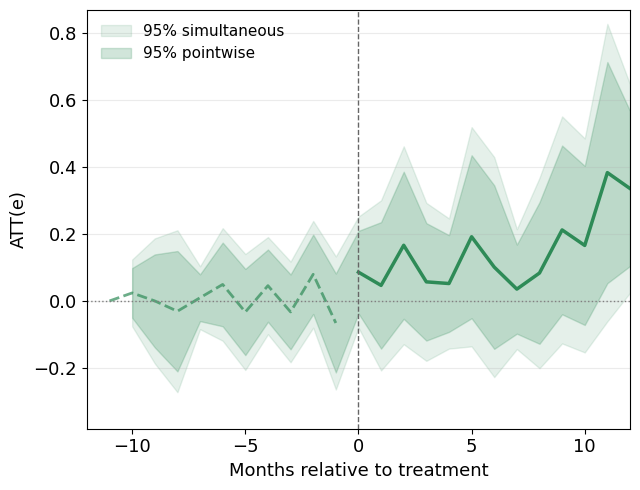

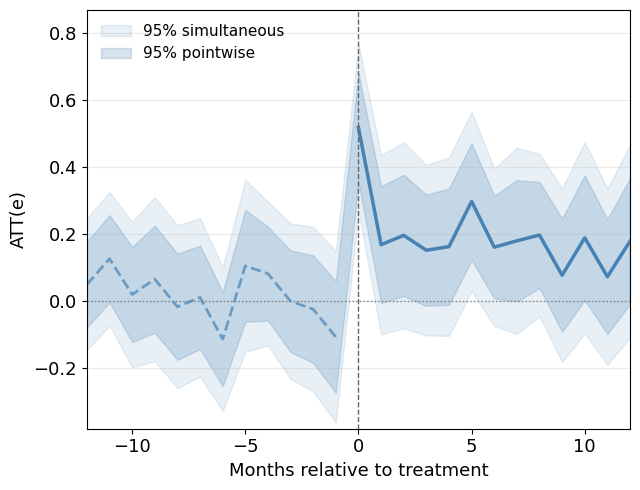

In [6]:
# ============================================================
# Main event study: technology-tagged collaborations
# One PDF per technology, so the draft can place them as subfigures (a)/(b)
# like every other paired exhibit. Bands are the SIMULTANEOUS (uniform) ones
# from did's crit.val.egt, exported by 07_..._psm.Rmd; the narrower pointwise
# band is drawn underneath for reference.
# ============================================================

def plot_eventstudy_single(event_study, label, color, fname, folder,
                           ylab="ATT(e)", ylim=None):
    df = event_study[event_study["label"] == label].copy()
    if df.empty:
        print(f"WARNING: no rows for '{label}'"); return
    df = df[(df["e"] >= -12) & (df["e"] <= 12)]
    pre, post = df[df["e"] < 0], df[df["e"] >= 0]

    fig, ax = plt.subplots(figsize=(6.5, 5))
    # simultaneous band (wide, light) then pointwise band (narrow, darker)
    ax.fill_between(df["e"], df["ci_lower"], df["ci_upper"], color=color, alpha=0.12,
                    label="95% simultaneous")
    ax.fill_between(df["e"], df["att"] - 1.96 * df["se"], df["att"] + 1.96 * df["se"],
                    color=color, alpha=0.22, label="95% pointwise")
    if not pre.empty:
        ax.plot(pre["e"], pre["att"], color=color, lw=2, ls="--", alpha=0.7)
    ax.plot(post["e"], post["att"], color=color, lw=2.5)

    ax.axhline(0, ls=":", color="grey", lw=1)
    ax.axvline(0, ls="--", color="#666666", lw=1)
    ax.set_xlim(-12, 12)
    if ylim: ax.set_ylim(*ylim)
    ax.set_xlabel("Months relative to treatment", fontsize=13)
    ax.set_ylabel(ylab, fontsize=13)
    ax.tick_params(axis="both", labelsize=13)
    style_ax(ax)
    ax.legend(frameon=False, fontsize=11, loc="upper left")
    plt.tight_layout()
    save_fig(fig, folder, fname)
    plt.show()


# common y-limits so the two panels are comparable side by side
_tt = event_study[event_study["Outcome"] == "Technology-tagged collaborations"]
_tt = _tt[(_tt["e"] >= -12) & (_tt["e"] <= 12)]
_YL = (min(_tt.ci_lower.min(), 0) * 1.05, _tt.ci_upper.max() * 1.05)

for _tech, _col in [("Battery", COLORS["two"][1]), ("Hydrogen", COLORS["two"][0])]:
    plot_eventstudy_single(
        event_study,
        label=f"{_tech} -- Technology-tagged collaborations", color=_col,
        fname=f"collaborations_techtagged_event_study_{_tech.lower()}",
        folder=FIG_MAIN, ylim=_YL)


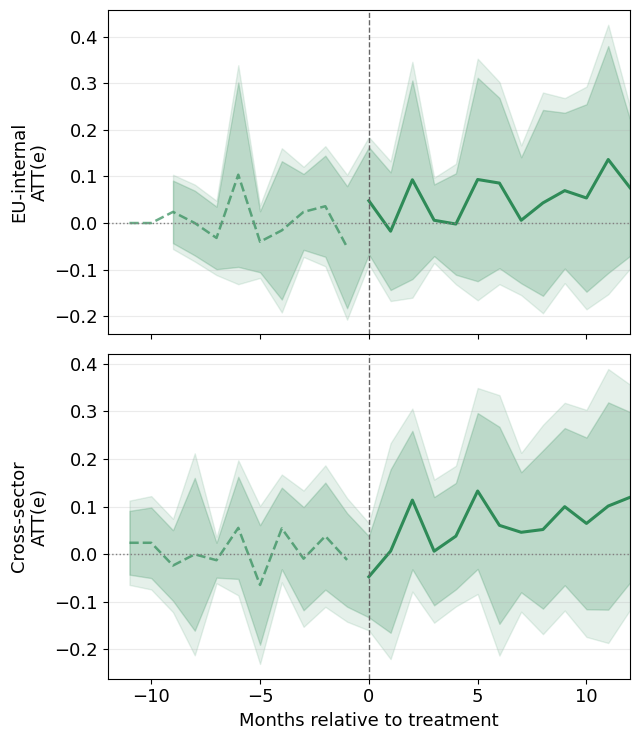

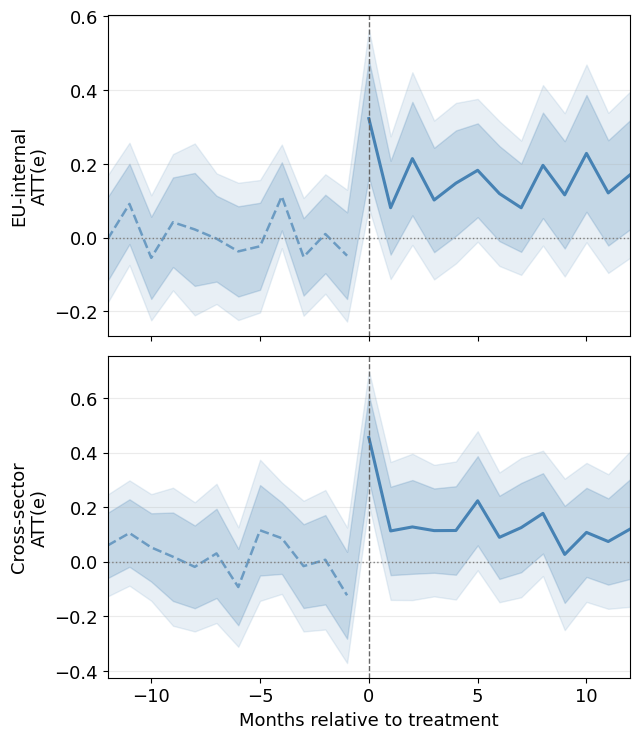

In [7]:
# ============================================================
# SI event study: the two conditioned outcomes, one PDF per technology
# (cross-border EU on top, cross-sector below), for subfigures (a)/(b).
# ============================================================

def plot_channels_single(event_study, tech, color, fname):
    # Geography is now classified at the collaboration level: EU-internal means
    # every participant is headquartered in the EU. Cross-sector is NACE-1.
    rows = [("EU-internal collaborations", "EU-internal"),
            ("Cross-sector collaborations",    "Cross-sector")]
    fig, axes = plt.subplots(2, 1, figsize=(6.5, 7.5), sharex=True)
    for ax, (outcome, row_label) in zip(axes, rows):
        df = event_study[event_study["label"] == f"{tech} -- {outcome}"].copy()
        if df.empty:
            ax.text(0.5, 0.5, "no data", transform=ax.transAxes,
                    ha="center", va="center", fontsize=11, color="#999999"); continue
        df = df[(df["e"] >= -12) & (df["e"] <= 12)]
        pre, post = df[df["e"] < 0], df[df["e"] >= 0]
        ax.fill_between(df["e"], df["ci_lower"], df["ci_upper"], color=color, alpha=0.12)
        ax.fill_between(df["e"], df["att"] - 1.96 * df["se"], df["att"] + 1.96 * df["se"],
                        color=color, alpha=0.22)
        if not pre.empty:
            ax.plot(pre["e"], pre["att"], color=color, lw=1.8, ls="--", alpha=0.7)
        ax.plot(post["e"], post["att"], color=color, lw=2.2)
        ax.axhline(0, ls=":", color="grey", lw=1)
        ax.axvline(0, ls="--", color="#666666", lw=1)
        ax.set_xlim(-12, 12)
        ax.set_ylabel(f"{row_label}\nATT(e)", fontsize=13)
        ax.tick_params(axis="both", labelsize=13)
        style_ax(ax)
    axes[-1].set_xlabel("Months relative to treatment", fontsize=13)
    plt.tight_layout()
    save_fig(fig, FIG_SI, fname)
    plt.show()


for _tech, _col in [("Battery", COLORS["two"][1]), ("Hydrogen", COLORS["two"][0])]:
    plot_channels_single(event_study, _tech, _col,
                         f"collaborations_channels_event_study_{_tech.lower()}")


## 3. Descriptive results (figures & tables)

Descriptive & network exhibits: cross-border flows (Fig. 4, *main*), cross-sector chord (Fig. 5, *main*), collaboration-type inventory, top firms, partner overlap, activity mix, baseline shares, and the SI network/prevalence plots. Each cell notes its paper destination.

Battery:


  Flows above threshold: 55
  IPCEI countries:   ['AT', 'DE', 'EE', 'FR', 'GR', 'HR', 'IT', 'NL', 'SE', 'SK']
  Partner countries: ['AT', 'BE', 'CZ', 'DE', 'DK', 'ES', 'FI', 'FR', 'GR', 'IE', 'IT', 'LU', 'NL', 'PL', 'PT', 'SE', 'SI']

Hydrogen:


  Flows above threshold: 76
  IPCEI countries:   ['AT', 'BE', 'DE', 'DK', 'EE', 'ES', 'FR', 'IT', 'NL', 'PT', 'SE', 'SK']
  Partner countries: ['AT', 'BE', 'BG', 'CZ', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'GR', 'HU', 'IT', 'LT', 'LU', 'LV', 'NL', 'PL', 'PT', 'SE', 'SI']
Battery right countries:  17
Hydrogen right countries: 21
Shared figure height:     7.3


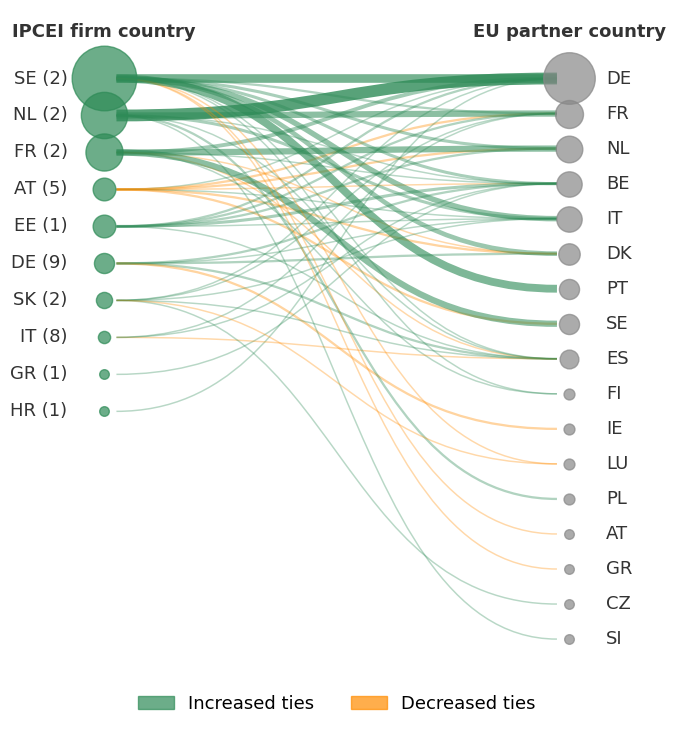

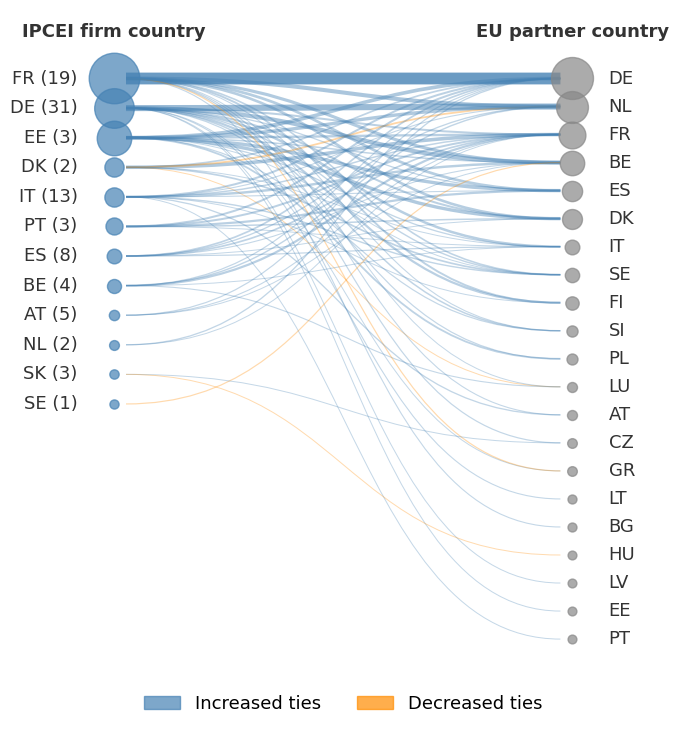

In [8]:
# ============================================================
# Change in EU cross-border ties - Sankey-style bipartite flow chart
# ============================================================

def build_bipartite_flows(partnership_master, firm_master_ipcei,
                           treated_names, tech_col, treatment_date,
                           eu_codes, window_months=12, min_flow=3):
    primary_map = dict(zip(
        firm_master_ipcei["Linkedin_name"],
        firm_master_ipcei["primary_country"].str.strip().str.upper()
    ))

    all_ipcei = set(firm_master_ipcei.loc[
        firm_master_ipcei["treated_any"].fillna(0).astype(int) == 1,
        "Linkedin_name"
    ])

    t         = pd.Timestamp(treatment_date)
    pre_start = t - pd.DateOffset(months=window_months)
    post_end  = t + pd.DateOffset(months=window_months)

    def get_flows(start, end):
        p = partnership_master.copy()
        p["post_date"] = pd.to_datetime(p["post_date"], errors="coerce")
        p = p[(p["post_date"] >= pd.Timestamp(start)) &
              (p["post_date"] <  pd.Timestamp(end))]
        p = p[p[tech_col] == 1]
        p = p[p["source"].isin(treated_names) | p["target"].isin(treated_names)]
        p = p[~(p["source"].isin(all_ipcei) & p["target"].isin(all_ipcei))]

        p["src_country"] = p["source"].map(primary_map)
        p["tgt_country"] = p["target"].map(primary_map)

        p = p[
            p["src_country"].isin(eu_codes) &
            p["tgt_country"].isin(eu_codes) &
            (p["src_country"] != p["tgt_country"])
        ]

        rows = []
        for _, row in p.iterrows():
            if row["source"] in treated_names:
                ipcei_country   = row["src_country"]
                partner_country = row["tgt_country"]
            else:
                ipcei_country   = row["tgt_country"]
                partner_country = row["src_country"]
            rows.append({
                "ipcei_country":    ipcei_country,
                "partner_country":  partner_country,
                "collaboration_id": row["collaboration_id"]
            })

        if not rows:
            return pd.DataFrame(columns=["ipcei_country",
                                          "partner_country", "n"])
        df = pd.DataFrame(rows)
        return (
            df.groupby(["ipcei_country", "partner_country"])
              ["collaboration_id"].nunique()
              .reset_index(name="n")
        )

    flows_pre  = get_flows(pre_start, t)
    flows_post = get_flows(t, post_end)

    delta = flows_pre.rename(columns={"n": "n_pre"}).merge(
        flows_post.rename(columns={"n": "n_post"}),
        on=["ipcei_country", "partner_country"], how="outer"
    ).fillna(0)

    delta["n_delta"] = delta["n_post"] - delta["n_pre"]
    delta = delta[delta["n_delta"].abs() >= min_flow]

    print(f"  Flows above threshold: {len(delta)}")
    print(f"  IPCEI countries:   {sorted(delta['ipcei_country'].unique())}")
    print(f"  Partner countries: {sorted(delta['partner_country'].unique())}")

    return delta


def draw_bipartite_flow(ax, delta, color, firm_counts=None, right_header="EU partner country"):
    if delta.empty:
        ax.text(0.5, 0.5, "No data", ha="center", va="center",
                transform=ax.transAxes)
        return

    from matplotlib.path import Path

    # ── Node ordering ─────────────────────────────────────────────────────────
    left_countries = (
        delta.groupby("ipcei_country")["n_delta"]
             .apply(lambda x: x.abs().sum())
             .sort_values(ascending=False)
             .index.tolist()
    )

    # Filter delta to only include flows from top 9 left countries
    delta = delta[delta["ipcei_country"].isin(left_countries)]

    right_countries = (
        delta.groupby("partner_country")["n_delta"]
             .apply(lambda x: x.abs().sum())
             .sort_values(ascending=False)
             .index.tolist()
    )

    n_left  = len(left_countries)
    n_right = len(right_countries)

    # ── Y positions — adaptive spacing ─────────────────────
    n_max    = max(n_left, n_right)
    y_step   = min(0.90 / max(n_max - 1, 1), 0.18)  # cap max spacing
    y_top    = 0.95

    left_y  = {c: y_top - i * (y_top / max(n_left  - 1, 1))
                * (n_left - 1) / max(n_max - 1, 1)
                for i, c in enumerate(left_countries)}
    right_y = {c: y_top - i * y_step
                for i, c in enumerate(right_countries)}

    max_n     = delta["n_delta"].abs().max() or 1
    max_firms = max(firm_counts.values()) if firm_counts else 1

    # ── Draw flows ────────────────────────────────────────────────────────────
    for _, row in delta.iterrows():
        ic = row["ipcei_country"]
        pc = row["partner_country"]
        n  = row["n_delta"]

        if ic not in left_y or pc not in right_y:
            continue

        y0    = left_y[ic]
        y1    = right_y[pc]
        lw    = 0.5 + 8.0 * (abs(n) / max_n)
        fc    = color if n > 0 else "darkorange"
        alpha = 0.3 + 0.5 * (abs(n) / max_n)

        verts = [(0.14, y0), (0.5, y0), (0.5, y1), (0.86, y1)]
        codes = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4]
        path  = Path(verts, codes)
        patch = mpatches.PathPatch(path, facecolor="none",
                                   edgecolor=fc,
                                   linewidth=lw, alpha=alpha)
        ax.add_patch(patch)

    # ── Draw left nodes ───────────────────────────────────────────────────────
    for c, y in left_y.items():
        total     = delta.loc[delta["ipcei_country"] == c,
                               "n_delta"].abs().sum()
        node_size = 0.010 + 0.022 * (total / max_n)

        # Inner filled circle — sized by absolute flow delta
        ax.scatter(0.12, y,
                   s=(node_size * 6000) ** 2 / 100,
                   color=color,
                   alpha=0.7,
                   zorder=5)

        label = f"{c} ({firm_counts.get(c, 0)})" if firm_counts else c
        ax.text(0.06, y, label, ha="right", va="center",
                fontsize=13, color="#333333")

    # ── Draw right nodes ──────────────────────────────────────────────────────
    for c, y in right_y.items():
        total     = delta.loc[delta["partner_country"] == c,
                               "n_delta"].abs().sum()
        node_size = 0.010 + 0.022 * (total / max_n)

        ax.scatter(0.88, y,
                   s=(node_size * 6000) ** 2 / 100,
                   color="#888888",
                   alpha=0.7,
                   zorder=5)

        ax.text(0.94, y, c, ha="left", va="center",
                fontsize=13, color="#333333")

    # ── Column headers ────────────────────────────────────────────────────────
    y_header = max(left_y.values()) + 0.06

    ax.text(0.12, y_header, "IPCEI firm country",
            ha="center", va="bottom", fontsize=13,
            fontweight="bold", color="#333333")
    ax.text(0.88, y_header, right_header,
            ha="center", va="bottom", fontsize=13,
            fontweight="bold", color="#333333")

    # ── Legend ────────────────────────────────────────────────────────────────
    pos_patch  = mpatches.Patch(color=color,        alpha=0.7,
                                 label="Increased ties")
    neg_patch  = mpatches.Patch(color="darkorange",  alpha=0.7,
                                 label="Decreased ties")
    ax.legend(handles=[pos_patch, neg_patch],
              loc="lower center", frameon=False,
              fontsize=13, ncol=3,
              bbox_to_anchor=(0.5, -0.04))

    ax.set_xlim(0, 1)
    ax.set_ylim(-0.05, y_header + 0.05)
    ax.axis("off")


# ── EU codes ──────────────────────────────────────────────────────────────────
EU_CODES = {
    "AT","BE","BG","HR","CY","CZ","DK","EE","FI","FR","DE","GR",
    "HU","IE","IT","LV","LT","LU","MT","NL","PL","PT","RO","SK",
    "SI","ES","SE"
}

battery_treated  = set(battery_cs[battery_cs["is_treated"]  == 1]["Linkedin_name"])
hydrogen_treated = set(hydrogen_cs[hydrogen_cs["is_treated"] == 1]["Linkedin_name"])

# ── IPCEI firm counts by primary country ─────────────────────────────────────
fm_temp  = firm_master_ipcei.copy()
types_lc = fm_temp["ipcei_types"].astype("string").str.lower()
fm_temp["is_battery"]  = types_lc.str.contains("battery",  na=False)
fm_temp["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)

battery_firm_counts = (
    fm_temp[fm_temp["is_battery"]]
    .dropna(subset=["primary_country"])
    .assign(c=lambda d: d["primary_country"].str.strip().str.upper())
    .groupby("c")["Linkedin_name"].nunique()
    .to_dict()
)

hydrogen_firm_counts = (
    fm_temp[fm_temp["is_hydrogen"]]
    .dropna(subset=["primary_country"])
    .assign(c=lambda d: d["primary_country"].str.strip().str.upper())
    .groupby("c")["Linkedin_name"].nunique()
    .to_dict()
)

# ── Build flows ───────────────────────────────────────────────────────────────
print("Battery:")
battery_delta = build_bipartite_flows(
    partnership_master, firm_master_ipcei,
    treated_names  = battery_treated,
    tech_col       = "Battery",
    treatment_date = "2021-01-01",
    eu_codes       = EU_CODES,
    window_months  = 12,
    min_flow       = 1
)

print("\nHydrogen:")
hydrogen_delta = build_bipartite_flows(
    partnership_master, firm_master_ipcei,
    treated_names  = hydrogen_treated,
    tech_col       = "Hydrogen",
    treatment_date = "2022-07-01",
    eu_codes       = EU_CODES,
    window_months  = 12,
    min_flow       = 3
)

# ── Compute shared figure height ──────────────────────────────────────────────
n_right_b = battery_delta["partner_country"].nunique()
n_right_h = hydrogen_delta["partner_country"].nunique()
n_right_max = max(n_right_b, n_right_h)
shared_height = max(5, 0.35 * n_right_max)

print(f"Battery right countries:  {n_right_b}")
print(f"Hydrogen right countries: {n_right_h}")
print(f"Shared figure height:     {shared_height:.1f}")

# ── Plot Battery ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, shared_height))
draw_bipartite_flow(ax, battery_delta,
                    color       = COLORS["two"][1],
                    firm_counts = battery_firm_counts)
plt.tight_layout()
save_fig(fig, FIG_MAIN, "collaborations_battery_crossborder_bipartite")
plt.show()

# ── Plot Hydrogen ─────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, shared_height))
draw_bipartite_flow(ax, hydrogen_delta,
                    color       = COLORS["two"][0],
                    firm_counts = hydrogen_firm_counts)
plt.tight_layout()
save_fig(fig, FIG_MAIN, "collaborations_hydrogen_crossborder_bipartite")
plt.show()


In [9]:
# ============================================================
# Non-EU headquartered IPCEI firms
# ============================================================

non_eu_ipcei = (
    firm_master_ipcei.loc[
        (firm_master_ipcei["treated_any"].fillna(0).astype(int) == 1) &
        (~firm_master_ipcei["primary_country"].str.strip().str.upper()
         .isin(EU_CODES))
    ]
    [[
        "Linkedin_name", "primary_country", "hq_country",
        "primary_city", "ipcei_types", "ipcei_rounds"
    ]]
    .drop_duplicates("Linkedin_name")
    .sort_values("primary_country")
    .reset_index(drop=True)
)

print(f"Non-EU IPCEI firms: {len(non_eu_ipcei)}")
print(non_eu_ipcei.to_string())

_ne = results_path("tables", TAB_MAIN, "non_eu_ipcei_firms.csv")
_ne.parent.mkdir(parents=True, exist_ok=True)
non_eu_ipcei.to_csv(_ne, index=False)
print(f"✓ Saved to {_ne}")


Non-EU IPCEI firms: 8
             Linkedin_name primary_country hq_country primary_city ipcei_types ipcei_rounds
0      air-products-europe              GB         GB     Chertsey    hydrogen            4
1                       bp              GB         GB       London    hydrogen          2|3
2           ferroglobe-plc              GB         GB       London     battery            2
3                    shell              GB         GB       London    hydrogen            2
4               1s1-energy              US          0            0    hydrogen            1
5  advent-technologies-inc              US         US       Boston    hydrogen            1
6              cummins-inc              US         US     Columbus    hydrogen            1
7             tesla-motors              US         US       Austin     battery            2
✓ Saved to /Users/go82gax/Documents/Projekte/IPCEI/Analyse/PythonProject/ipcei-spillovers/results/tables/post-audit/psm/non_eu_ipcei_firms.csv


Battery:


  Flows above threshold: 46
  IPCEI countries:   ['AT', 'DE', 'EE', 'FR', 'GR', 'IT', 'NL', 'SE', 'SK']
  Partner countries: ['AU', 'CA', 'CH', 'CN', 'GB', 'IL', 'IN', 'JP', 'KR', 'NO', 'RU', 'SG', 'TR', 'UA', 'US', 'ZA']

Hydrogen:


  Flows above threshold: 54
  IPCEI countries:   ['AT', 'BE', 'DE', 'DK', 'EE', 'ES', 'FR', 'IT', 'NL', 'PL', 'PT']
  Partner countries: ['AE', 'AU', 'BR', 'CA', 'CH', 'CL', 'CO', 'DZ', 'GB', 'HK', 'ID', 'IN', 'JP', 'KR', 'MC', 'MX', 'NO', 'NZ', 'SA', 'SG', 'TR', 'US', 'UY']

Battery right countries:  16
Hydrogen right countries: 23
Shared figure height:     8.0


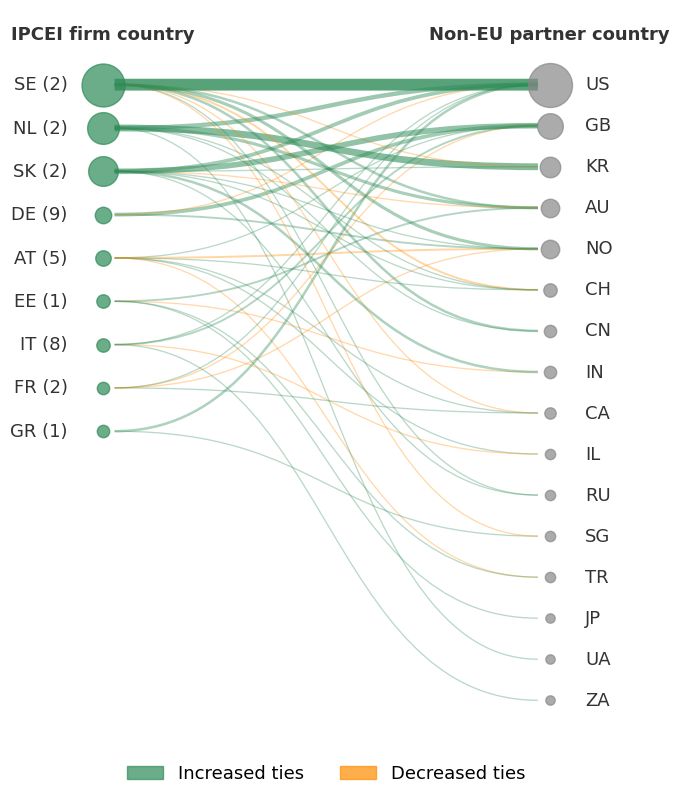

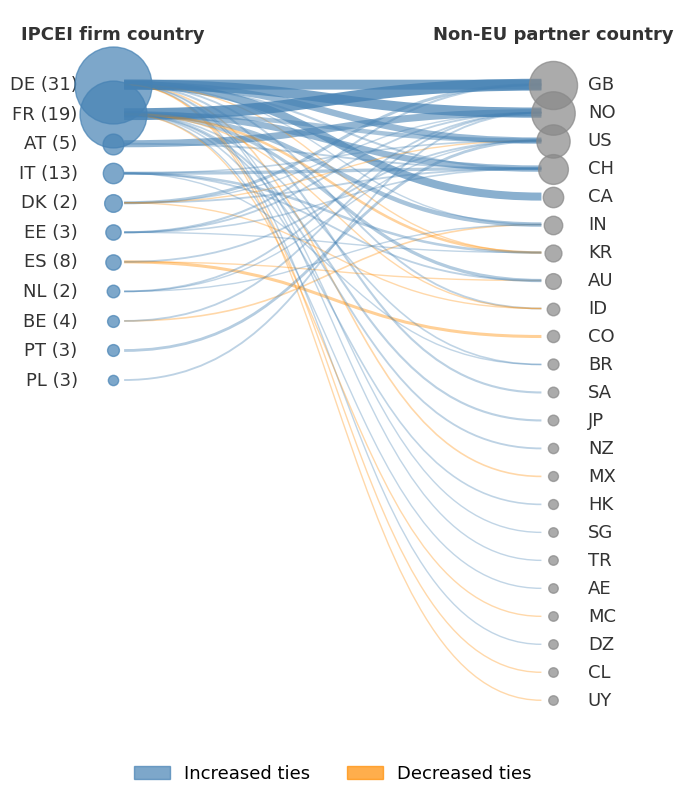

In [10]:
# ============================================================
# Non-EU collaborations - Sankey-style bipartite flow chart
# ============================================================

def build_bipartite_flows_noneu(partnership_master, firm_master_ipcei,
                                 treated_names, tech_col, treatment_date,
                                 eu_codes, window_months=12, min_flow=3):
    primary_map = dict(zip(
        firm_master_ipcei["Linkedin_name"],
        firm_master_ipcei["primary_country"].str.strip().str.upper()
    ))

    all_ipcei = set(firm_master_ipcei.loc[
        firm_master_ipcei["treated_any"].fillna(0).astype(int) == 1,
        "Linkedin_name"
    ])

    t         = pd.Timestamp(treatment_date)
    pre_start = t - pd.DateOffset(months=window_months)
    post_end  = t + pd.DateOffset(months=window_months)

    def get_flows(start, end):
        p = partnership_master.copy()
        p["post_date"] = pd.to_datetime(p["post_date"], errors="coerce")
        p = p[(p["post_date"] >= pd.Timestamp(start)) &
              (p["post_date"] <  pd.Timestamp(end))]
        p = p[p[tech_col] == 1]
        p = p[p["source"].isin(treated_names) | p["target"].isin(treated_names)]

        # Exclude IPCEI-IPCEI pairs
        p = p[~(p["source"].isin(all_ipcei) & p["target"].isin(all_ipcei))]

        p["src_country"] = p["source"].map(primary_map)
        p["tgt_country"] = p["target"].map(primary_map)

        p = p.dropna(subset=["src_country", "tgt_country"])

        # Remove invalid country codes
        valid_iso2 = lambda x: isinstance(x, str) and len(x) == 2 and x.isalpha()
        p = p[p["src_country"].apply(valid_iso2) & p["tgt_country"].apply(valid_iso2)]


        # IPCEI firm must be in EU, partner must be outside EU
        rows = []
        for _, row in p.iterrows():
            if row["source"] in treated_names:
                ipcei_country   = row["src_country"]
                partner_country = row["tgt_country"]
            else:
                ipcei_country   = row["tgt_country"]
                partner_country = row["src_country"]

            # IPCEI firm must be EU-headquartered
            # Partner must be non-EU
            if (ipcei_country in eu_codes and
                    partner_country not in eu_codes and
                    partner_country != ipcei_country):
                rows.append({
                    "ipcei_country":    ipcei_country,
                    "partner_country":  partner_country,
                    "collaboration_id": row["collaboration_id"]
                })

        if not rows:
            return pd.DataFrame(columns=["ipcei_country",
                                          "partner_country", "n"])
        df = pd.DataFrame(rows)
        return (
            df.groupby(["ipcei_country", "partner_country"])
              ["collaboration_id"].nunique()
              .reset_index(name="n")
        )

    flows_pre  = get_flows(pre_start, t)
    flows_post = get_flows(t, post_end)

    delta = flows_pre.rename(columns={"n": "n_pre"}).merge(
        flows_post.rename(columns={"n": "n_post"}),
        on=["ipcei_country", "partner_country"], how="outer"
    ).fillna(0)

    delta["n_delta"] = delta["n_post"] - delta["n_pre"]
    delta = delta[delta["n_delta"].abs() >= min_flow]

    print(f"  Flows above threshold: {len(delta)}")
    print(f"  IPCEI countries:   {sorted(delta['ipcei_country'].unique())}")
    print(f"  Partner countries: {sorted(delta['partner_country'].unique())}")

    return delta


# ── EU codes ──────────────────────────────────────────────────────────────────
EU_CODES = {
    "AT","BE","BG","HR","CY","CZ","DK","EE","FI","FR","DE","GR",
    "HU","IE","IT","LV","LT","LU","MT","NL","PL","PT","RO","SK",
    "SI","ES","SE"
}

battery_treated  = set(battery_cs[battery_cs["is_treated"]  == 1]["Linkedin_name"])
hydrogen_treated = set(hydrogen_cs[hydrogen_cs["is_treated"] == 1]["Linkedin_name"])

# ── Build flows ───────────────────────────────────────────────────────────────
print("Battery:")
battery_delta_noneu = build_bipartite_flows_noneu(
    partnership_master, firm_master_ipcei,
    treated_names  = battery_treated,
    tech_col       = "Battery",
    treatment_date = "2021-01-01",
    eu_codes       = EU_CODES,
    window_months  = 12,
    min_flow       = 1
)

print("\nHydrogen:")
hydrogen_delta_noneu = build_bipartite_flows_noneu(
    partnership_master, firm_master_ipcei,
    treated_names  = hydrogen_treated,
    tech_col       = "Hydrogen",
    treatment_date = "2022-07-01",
    eu_codes       = EU_CODES,
    window_months  = 12,
    min_flow       = 3
)

# ── Shared figure height ──────────────────────────────────────────────────────
n_right_b    = battery_delta_noneu["partner_country"].nunique()
n_right_h    = hydrogen_delta_noneu["partner_country"].nunique()
n_right_max  = max(n_right_b, n_right_h)
shared_height = max(5, 0.35 * n_right_max)

print(f"\nBattery right countries:  {n_right_b}")
print(f"Hydrogen right countries: {n_right_h}")
print(f"Shared figure height:     {shared_height:.1f}")

# ── Plot Battery ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, shared_height))
draw_bipartite_flow(ax, battery_delta_noneu,
                    color       = COLORS["two"][1],
                    firm_counts = battery_firm_counts,
                    right_header = "Non-EU partner country")
plt.tight_layout()
save_fig(fig, FIG_SI, "collaborations_battery_noneu_bipartite")
plt.show()

# ── Plot Hydrogen ─────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, shared_height))
draw_bipartite_flow(ax, hydrogen_delta_noneu,
                    color       = COLORS["two"][0],
                    firm_counts = hydrogen_firm_counts,
                    right_header = "Non-EU partner country")
plt.tight_layout()
save_fig(fig, FIG_SI, "collaborations_hydrogen_noneu_bipartite")
plt.show()


In [11]:
# *** CURRENTLY NOT USED ***
# Orphaned call: plot_sector_heatmaps_diff() was moved into the archive section
# during the chord-figure consolidation, but this call stayed live, so the
# notebook could not run top to bottom (NameError here blocked the cross-sector
# chord figure in cell 17 and the pre-trend overlay in cell 30). The function
# definition is in the archive cell further down; re-enable both together if
# the sector heatmaps are ever wanted again.
# plot_sector_heatmaps_diff(
#     battery_cs, hydrogen_cs,
#     partnership_master, firm_master_ipcei,
#     sector_labels, sector_order
# )


In [12]:
# ============================================================
# Cross-sector chord helpers, shared by the main chord figure (next cell)
# and the archived delta chord (section 5): simplified sector labels and
# their display order, sector-pair counts for a date window, and the
# chord drawer.
# ============================================================

# ── Sector label mapping (nace2_proxy_nace1 -> short label) ──────────────
# NACE-1 sections, the same resolution as the cross-sector OUTCOME. Until
# Nov 2026 the figure used simplified NACE-2 divisions, which did not match
# the reported outcome: most of what it drew as cross-sector (motor vehicle
# with machinery or electronics manufacturing, say) sits inside section C and
# is SAME-sector under the outcome.
sector_labels = {
    "A — Agriculture, forestry and fishing":      "Agriculture",
    "B — Mining and quarrying":                   "Mining",
    "C — Manufacturing":                          "Manufacturing",
    "D — Energy and utilities":                   "Energy & utilities",
    "E — Water and environmental services":       "Water & environment",
    "F — Construction":                           "Construction",
    "G — Wholesale and retail trade":             "Wholesale & retail",
    "H — Transportation and storage":             "Transport & storage",
    "I — Accommodation and food service":         "Accommodation & food",
    "J — Information and communication":          "Information & comms",
    "K — Finance and insurance":                  "Finance & insurance",
    "L — Real estate":                            "Real estate",
    "M — Professional, scientific and technical": "Professional & scientific",
    "N — Administrative and support services":    "Administrative services",
    "O — Public administration":                  "Public administration",
    "P — Education":                              "Education",
    "Q — Human health and social work":           "Health & social work",
    "R — Arts, entertainment and recreation":     "Arts & recreation",
    "S — Other services":                         "Other services",
}

# Display order around the circle (consistent across technologies)
sector_order = [
    # Industry and resources
    "Mining", "Manufacturing", "Construction",
    # Energy system
    "Energy & utilities", "Water & environment",
    # Moving and selling
    "Transport & storage", "Wholesale & retail",
    # Knowledge
    "Information & comms", "Professional & scientific", "Education",
    # Public administration and remaining services
    "Public administration", "Health & social work", "Finance & insurance",
    "Administrative services", "Real estate", "Agriculture",
    "Accommodation & food", "Arts & recreation", "Other services",
]


def _sector_pair_counts(partnership_master, firm_master_ipcei, treated_names,
                        tech_col, sector_labels, start_date, end_date):
    """
    Sector pairs linked by the technology-related collaborations of treated
    firms within [start_date, end_date).

    Classification matches the cross-sector OUTCOME on two points. Sectors are
    NACE-1 sections (nace2_proxy_nace1), not NACE-2 divisions, and each
    collaboration is classified as a whole from the sections of ALL its
    participants rather than pair by pair. A collaboration spanning k distinct
    sections therefore contributes its k(k-1)/2 unordered section pairs once
    each, and one staying inside a single section (same-sector under the
    outcome) contributes nothing. Participants with an unknown section are
    dropped. Returns sec_a / sec_b (alphabetical) / n = unique collaborations.
    """
    sector_map = dict(zip(
        firm_master_ipcei["Linkedin_name"],
        firm_master_ipcei["nace2_proxy_nace1"].map(sector_labels)
    ))
    p = partnership_master.copy()
    p["post_date"] = pd.to_datetime(p["post_date"], errors="coerce")
    p = p[(p["post_date"] >= pd.Timestamp(start_date)) &
          (p["post_date"] <  pd.Timestamp(end_date))]
    p = p[p[tech_col] == 1]
    p = p[p["source"].isin(treated_names) | p["target"].isin(treated_names)]

    # One row per (collaboration, participant), then per (collaboration, section).
    parts = pd.concat([
        p[["collaboration_id", "source"]].rename(columns={"source": "_f"}),
        p[["collaboration_id", "target"]].rename(columns={"target": "_f"}),
    ], ignore_index=True).dropna(subset=["collaboration_id", "_f"]).drop_duplicates()
    parts["_s"] = parts["_f"].map(sector_map)
    parts = parts.dropna(subset=["_s"]).drop_duplicates(["collaboration_id", "_s"])

    # Self-join on the collaboration gives every unordered pair of sections once
    # (the _s_a < _s_b filter also drops the same-section diagonal).
    pairs = parts.merge(parts, on="collaboration_id", suffixes=("_a", "_b"))
    pairs = pairs[pairs["_s_a"] < pairs["_s_b"]]
    return (pairs.groupby(["_s_a", "_s_b"])["collaboration_id"]
                 .nunique().reset_index()
                 .rename(columns={"_s_a": "sec_a", "_s_b": "sec_b",
                                  "collaboration_id": "n"}))


def draw_sector_chord(ax, flows, sectors, color, neg_flows=None, title=None,
                      label_fontsize=13):
    """
    Chord diagram of cross-sector ties. `flows` has sec_a / sec_b / n and is
    drawn in the technology colour. If `neg_flows` is given (delta chord:
    weakened ties), those are drawn in orange and a legend is added; arc
    sizes then reflect both sets.
    """
    n = len(sectors)
    if n == 0:
        ax.text(0.5, 0.5, "No data", ha="center", va="center", transform=ax.transAxes)
        if title: ax.set_title(title, fontsize=13, fontweight="bold", pad=12)
        ax.axis("off")
        return

    all_flows = flows if neg_flows is None else pd.concat([flows, neg_flows], ignore_index=True)
    totals = {c: 0 for c in sectors}
    for _, row in all_flows.iterrows():
        if row["sec_a"] in totals: totals[row["sec_a"]] += row["n"]
        if row["sec_b"] in totals: totals[row["sec_b"]] += row["n"]

    grand_total = sum(totals.values()) or 1
    gap = 0.02

    # Arc positions (angles in radians), proportional to each sector's tie total
    arc_pos = {}
    angle = 0
    for c in sectors:
        span = (totals[c] / grand_total) * (1 - gap * n)
        arc_pos[c] = {"start": angle * 2 * np.pi, "end": (angle + span) * 2 * np.pi}
        angle += span + gap

    base = mcolors.to_rgb(color)
    sector_colors = {}
    for i, c in enumerate(sectors):
        tt = i / max(len(sectors) - 1, 1)
        sector_colors[c] = tuple(base[j] + tt * (1 - base[j]) * 0.6 for j in range(3))

    def _draw(fl, color_fn, alpha_fn):
        fill_pos = {c: arc_pos[c]["start"] for c in sectors}
        max_n = fl["n"].max() if len(fl) > 0 else 1
        for _, row in fl.iterrows():
            ca, cb, n_flow = row["sec_a"], row["sec_b"], row["n"]
            if ca not in arc_pos or cb not in arc_pos:
                continue
            span = (n_flow / grand_total) * 2 * np.pi * (1 - gap * n)
            a0 = fill_pos[ca]; a1 = a0 + span
            b0 = fill_pos[cb]; b1 = b0 + span
            fill_pos[ca] += span
            fill_pos[cb] += span
            pt = lambda a, r=1: (r * np.cos(a), r * np.sin(a))
            verts = [pt(a0), (0, 0), pt(b1), pt(b0), (0, 0), pt(a1), pt(a0)]
            codes = [Path.MOVETO, Path.CURVE3, Path.CURVE3,
                     Path.LINETO, Path.CURVE3, Path.CURVE3, Path.CLOSEPOLY]
            ax.add_patch(mpatches.PathPatch(
                Path(verts, codes), facecolor=color_fn(ca), edgecolor="none",
                alpha=alpha_fn(n_flow, max_n)))

    _draw(flows,
          color_fn=lambda s: sector_colors.get(s, (0.5, 0.5, 0.5)),
          alpha_fn=lambda x, mx: 0.2 + 0.6 * (x / mx))
    if neg_flows is not None:
        _draw(neg_flows,
              color_fn=lambda s: mcolors.to_rgb("darkorange"),
              alpha_fn=lambda x, mx: 0.15 + 0.4 * (x / mx))

    # Outer arcs and rotated labels
    R_inner, R_outer, R_label = 0.95, 1.03, 1.18
    for c in sectors:
        a_start, a_end = arc_pos[c]["start"], arc_pos[c]["end"]
        mid = (a_start + a_end) / 2
        theta = np.linspace(a_start, a_end, 50)
        x_outer = R_outer * np.cos(theta); y_outer = R_outer * np.sin(theta)
        x_inner = R_inner * np.cos(theta[::-1]); y_inner = R_inner * np.sin(theta[::-1])
        ax.fill(np.concatenate([x_outer, x_inner]), np.concatenate([y_outer, y_inner]),
                color=sector_colors.get(c, (0.5, 0.5, 0.5)), alpha=0.9)
        ha = "left" if np.cos(mid) > 0 else "right"
        rotation = np.degrees(mid) + (180 if np.cos(mid) < 0 else 0)
        ax.text(R_label * np.cos(mid), R_label * np.sin(mid), c,
                ha=ha, va="center", fontsize=label_fontsize, color="#333333",
                rotation=rotation, rotation_mode="anchor")

    ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6)
    ax.set_aspect("equal"); ax.axis("off")
    if title:
        ax.set_title(title, fontsize=13, fontweight="bold", pad=12)
    if neg_flows is not None:
        ax.legend(handles=[mpatches.Patch(color=color, alpha=0.7, label="Strengthened ties"),
                           mpatches.Patch(color="darkorange", alpha=0.7, label="Weakened ties")],
                  loc="lower center", frameon=False, fontsize=13, ncol=2,
                  bbox_to_anchor=(0.5, -0.05))


Window: 2020-01-01 to 2026-01-01



Battery: 43 sector pairs, 3018 ties | pair-count quantiles 50/75/90: [31, 80, 188], max 473
  drawn: 43 pairs (min_flow = 1) | sectors: ['Electronics Mfg.', 'Machinery Mfg.', 'Motor Mfg.', 'Chemical Mfg.', 'Oil & Gas', 'Energy/Utilities', 'Env. Services', 'Transport', 'Digital/IT', 'Research', 'Mining']


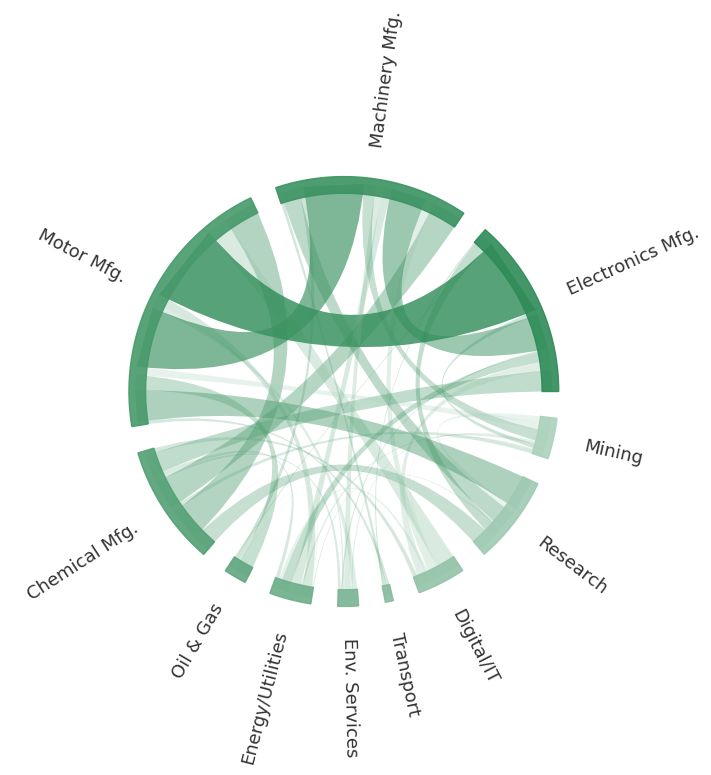


Hydrogen: 55 sector pairs, 17024 ties | pair-count quantiles 50/75/90: [268, 399, 666], max 1053
  drawn: 54 pairs (min_flow = 3) | sectors: ['Electronics Mfg.', 'Machinery Mfg.', 'Motor Mfg.', 'Chemical Mfg.', 'Oil & Gas', 'Energy/Utilities', 'Env. Services', 'Transport', 'Digital/IT', 'Research', 'Mining']


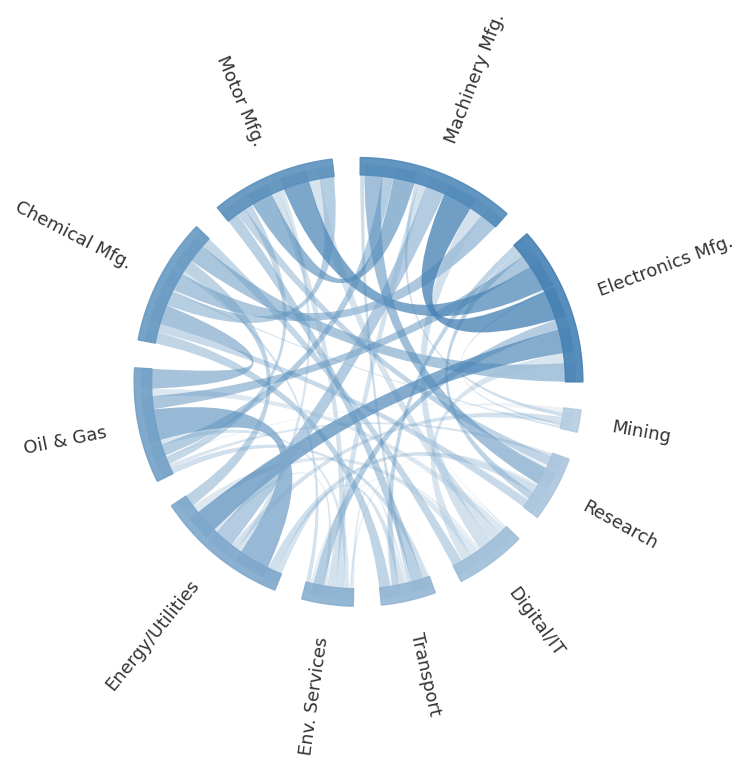

In [13]:
# ============================================================
# Cross-sector collaboration ties — chord diagrams (SI fig:crosssector_chords)
# Technology-related collaborations of IPCEI firms over the full analysis
# window (2020-2025), cross-sector pairs only, one PDF per technology.
# Sectors are NACE-1 sections and each collaboration is classified as a
# whole, matching the cross-sector outcome in Table 1. The sectoral
# structure is read as a property of the
# technology, not as a treatment effect, hence no pre/post split (the
# delta chord lives in section 5, archived).
# Helpers come from the cell above.
# ============================================================

# Window: the paper's analysis window 2020-2025 (PLOT_START/PLOT_END from
# ipcei_spillovers.plotting), not the raw data range, which has a pre-2020 tail.
CHORD_START, CHORD_END = PLOT_START, PLOT_END

# A section pair is drawn when it carries at least this share of its
# technology's section-pair ties. A share rather than two hand-set counts, so
# both technologies are filtered on one rule despite very different totals.
# 1.5% keeps 16 pairs / 11 sections for battery and 20 / 10 for hydrogen,
# covering 66% and 62% of ties. The value must be stated in the caption.
MIN_SHARE = 0.015

# Sector-label size, tuned for the printed page rather than for this preview.
# The saved PDF is about 8.8 in wide and the SI stacks the two panels at
# 0.65\textwidth, so 22 pt here prints at roughly 10.3 pt against 12 pt body
# text (the old side-by-side layout at 13 pt printed at 5 pt). Raising it
# further shrinks the ring rather than helping, because the long section names
# set the tight bounding box; widen the panel in the SI instead.
CHORD_LABEL_FS = 22

CHORD_SPECS = [
    ("Battery",  battery_cs,  COLORS["two"][1]),
    ("Hydrogen", hydrogen_cs, COLORS["two"][0]),
]

print(f"Window: {CHORD_START.date()} to {CHORD_END.date()}")
for tech, cs, color in CHORD_SPECS:
    treated = set(cs.loc[cs["is_treated"] == 1, "Linkedin_name"])
    flows = _sector_pair_counts(partnership_master, firm_master_ipcei, treated,
                                tech, sector_labels, CHORD_START, CHORD_END)
    q_total = flows["n"].sum()
    q = flows["n"].quantile([0.5, 0.75, 0.9]).astype(int).tolist()
    print(f"\n{tech}: {len(flows)} sector pairs, {int(flows['n'].sum())} ties | "
          f"pair-count quantiles 50/75/90: {q}, max {int(flows['n'].max())}")

    flows   = flows[flows["n"] >= MIN_SHARE * flows["n"].sum()]
    present = set(flows["sec_a"]) | set(flows["sec_b"])
    sectors = [s for s in sector_order if s in present]
    print(f"  drawn: {len(flows)} pairs (>= {MIN_SHARE:.1%} of ties), "
          f"{flows['n'].sum() / q_total:.0%} of ties | sectors: {sectors}")

    fig, ax = plt.subplots(figsize=(8, 8))
    draw_sector_chord(ax, flows, sectors, color=color,
                      label_fontsize=CHORD_LABEL_FS)
    plt.tight_layout()
    save_fig(fig, FIG_SI, f"collaborations_{tech.lower()}_crosssector_chord")
    plt.show()


**\*\*\* NOT USED (stale) \*\*\*** — references `nace_section`, a column not in the current data; superseded by the descriptive baseline cross-sector-share cell. Kept for reference only (disabled as a markdown cell so it never runs).

```python
# ============================================================
# Pre/post cross-sector collaboration shares, by technology
# Collaboration-level; per-firm treatment-date split.
# ============================================================
fm = firm_master_ipcei.copy()
fm["first_battery_date"]  = pd.to_datetime(fm["first_battery_date"],  errors="coerce")
fm["first_hydrogen_date"] = pd.to_datetime(fm["first_hydrogen_date"], errors="coerce")

p = partnership_master.copy()
p["post_date"] = pd.to_datetime(p["post_date"], errors="coerce")

# ---- cross-sector flag at collaboration level ----
# A collaboration is cross-sector if its partners span >=2 distinct sectors.
# ADJUST 'sector_col' and the tech flag columns to your actual schema.
sector_col = "nace_section"

# build collaboration -> set of sectors, from the endpoint-long structure
long = pd.concat([
    p[["collaboration_id", "source", "post_date"]].rename(columns={"source": "firm"}),
    p[["collaboration_id", "target", "post_date"]].rename(columns={"target": "firm"}),
], ignore_index=True).dropna(subset=["firm"])

# attach each firm's sector (from firm master; adjust key/columns)
firm_sector = fm.set_index("Linkedin_name")[sector_col].to_dict()
long["sector"] = long["firm"].map(firm_sector)

xsec = (long.dropna(subset=["sector"])
            .groupby("collaboration_id")["sector"]
            .nunique()
            .rename("n_sectors"))
xsec_flag = (xsec >= 2).rename("is_crosssector")   # collaboration-level flag

# ---- per-firm pre/post split, by technology ----
def crosssector_shares(tech, date_col, tech_flag_col):
    firms = fm.loc[fm[date_col].notna(), ["Linkedin_name", date_col]]
    # restrict to collaborations carrying this technology tag
    tech_collabs = set(p.loc[p[tech_flag_col] == 1, "collaboration_id"])

    rows = []
    for _, r in firms.iterrows():
        t0 = r[date_col]
        # this firm's collaborations in the tech, with dates
        fc = long[(long["firm"] == r["Linkedin_name"]) &
                  (long["collaboration_id"].isin(tech_collabs))]
        fc = fc.drop_duplicates("collaboration_id")
        for _, c in fc.iterrows():
            period = "pre" if c["post_date"] < t0 else "post"
            cs = bool(xsec_flag.get(c["collaboration_id"], False))
            rows.append((period, cs))
    d = pd.DataFrame(rows, columns=["period", "is_xsec"])
    out = d.groupby("period")["is_xsec"].mean().mul(100).round(1)
    n   = d.groupby("period")["is_xsec"].size()
    print(f"\n{tech}: cross-sector share (%)")
    for per in ["pre", "post"]:
        if per in out.index:
            print(f"  {per:4s}: {out[per]:.1f}%   (n={n[per]:,} collaborations)")

crosssector_shares("Battery",  "first_battery_date",  "Battery")
crosssector_shares("Hydrogen", "first_hydrogen_date", "Hydrogen")

```


In [14]:
# ============================================================
# Descriptive statistics behind the sectoral-composition and
# consortium-size results (numbers cited in the text).
#   (ii)  Baseline cross-sector share of technology-tagged
#         collaborations, treated firms, pre-treatment. Uses the NACE-1
#         collaboration-level columns, i.e. the reported outcome. The
#         dyad-level NACE-2 columns used here until Nov 2026 gave 86%
#         for battery, which no longer matched anything in the paper.
#   (iii) Mean consortium size, treated firms, pre-treatment vs
#         the first 12 months after approval.
# ============================================================

# These numbers are quoted in the main text beside the Table 1 estimates, so
# they are computed on the PRIMARY (spec 1) matched panels, not the spec-2
# panels that battery_cs / hydrogen_cs carry for the figures. The battery
# treated set is identical across specs; hydrogen has 93 treated firms here
# against 91 in spec 2, which moves its cross-sector share by about 1pp.
_panels = {
    "Battery":  load_df("processed", "combined", "battery_spec1_cs_ready.csv",  low_memory=False),
    "Hydrogen": load_df("processed", "combined", "hydrogen_spec1_cs_ready.csv", low_memory=False),
}

# -- (ii) Baseline cross-sector share -----------------------------------------
xsec_rows = []
for tech, cs in _panels.items():
    t   = tech.lower()
    pre = cs[(cs["is_treated"] == 1) & (cs["event_time"] < 0)]
    xs  = pre[f"n_collabs_crosssector_n1_{t}"].sum()
    wi  = pre[f"n_collabs_samesector_n1_{t}"].sum()
    tot = pre[f"n_collabs_{t}"].sum()
    xsec_rows.append({
        "technology":                    tech,
        "n_treated_firms":               int(pre["Linkedin_name"].nunique()),
        "n_crosssector":                 int(xs),
        "n_samesector":                  int(wi),
        "n_tech_tagged":                 int(tot),
        "share_of_classified_pct":       round(100 * xs / (xs + wi), 1) if (xs + wi) else float("nan"),
        "share_of_all_tech_tagged_pct":  round(100 * xs / tot, 1) if tot else float("nan"),
    })
crosssector_baseline = pd.DataFrame(xsec_rows)

# -- (iii) Consortium size, pre vs first 12 months post -----------------------
size_rows = []
for tech, cs in _panels.items():
    tr   = cs[cs["is_treated"] == 1]
    pre  = tr[tr["event_time"] < 0]
    post = tr[(tr["event_time"] >= 0) & (tr["event_time"] <= 12)]
    pre_active  = pre.loc[pre["mean_collab_size"]  > 0, "mean_collab_size"]
    post_active = post.loc[post["mean_collab_size"] > 0, "mean_collab_size"]
    size_rows.append({
        "technology":               tech,
        "pre_mean_active":          round(pre_active.mean(), 2),
        "post_mean_active":         round(post_active.mean(), 2),
        "pre_mean_incl_zeros":      round(pre["mean_collab_size"].mean(), 2),
        "post_mean_incl_zeros":     round(post["mean_collab_size"].mean(), 2),
        "n_firmmonths_pre_active":  int(pre_active.shape[0]),
        "n_firmmonths_post_active": int(post_active.shape[0]),
    })
consortium_size_prepost = pd.DataFrame(size_rows)

print("Baseline cross-sector share (treated firms, pre-treatment):")
print(crosssector_baseline.to_string(index=False))
print("\nConsortium size (treated firms, pre vs first 12 months post):")
print(consortium_size_prepost.to_string(index=False))

# -- Save ---------------------------------------------------------------------
for _df, _name in [(crosssector_baseline,    "crosssector_baseline_share"),
                   (consortium_size_prepost, "consortium_size_prepost")]:
    _out = results_path("tables", TAB_MAIN, f"{_name}.csv")
    _out.parent.mkdir(parents=True, exist_ok=True)
    _df.to_csv(_out, index=False)
    print(f"Saved: {_out}")


Baseline cross-sector share (treated firms, pre-treatment):
technology  n_treated_firms  n_crosssector  n_withinsector  n_tech_tagged  share_of_classified_pct  share_of_all_tech_tagged_pct
   Battery               29             68              11             73                     86.1                          93.2
  Hydrogen               91           4905            2123           5385                     69.8                          91.1

Consortium size (treated firms, pre vs first 12 months post):
technology  pre_mean_active  post_mean_active  pre_mean_incl_zeros  post_mean_incl_zeros  n_firmmonths_pre_active  n_firmmonths_post_active
   Battery             5.13              4.20                 0.99                  1.54                       67                       138
  Hydrogen             4.80              5.35                 2.25                  3.81                     1661                       842
Saved: /Users/go82gax/Documents/Projekte/IPCEI/Analyse/PythonProject/i

In [15]:
# ============================================================
# Benchmark: is the IPCEI firms' baseline cross-sector share high?
# Cross-sector share of collaborations for EVERY technology tag in the
# data (all firms), using the same definition as the DiD outcome and the
# treated baseline above:
#   - sector = nace2_proxy_nace1 (NACE-1 section) from firm_master, kept
#     only where genuinely known (same _is_known rule as nb03)
#   - a collaboration is classified as a WHOLE from the sections of all its
#     participants: cross-sector if it spans two or more sections,
#     same-sector if it stays within one. The two are mutually exclusive,
#     unlike the dyad-level NACE-2 flags used here until Nov 2026, under
#     which ~72% of same-sector collaborations also counted as cross-sector.
#   - a collaboration with no participant of known section is unclassified
#   - share_of_classified_pct = n_cross / (n_cross + n_same)
# Two windows (full 2020-2025; 2020 only = the year before the first
# IPCEI approval) x two samples (all collaborations; excluding any
# collaboration that involves an IPCEI beneficiary), so the treated
# baseline can be compared with the field and with other clean technologies.
# ============================================================

TECH_FLAGS = [c for c in [
    "Biomass", "Biofuels", "Biogas", "Wind", "Offshore_Wind", "Solar",
    "Concentrated_Solar", "Waste_to_Heat", "Direct_Air_Capture",
    "Carbon_Capture_And_Storage", "Biochar", "Carbon_Direct_Removal", "BECCS",
    "Hydrogen", "Nuclear_Energy", "Nuclear_Fusion", "Hydro_Energy", "Geothermal",
    "Battery", "Electric_Vehicles", "Sustainable_Aviation_Fuels", "E_Fuels",
    "Marine_Energy", "Heat_Pumps", "Railway", "Electric_Shipping",
    "Electric_Aviation", "Fuel_Cell_Aviation", "Other_Technology",
] if c in partnership_master.columns]

_nace1_map = dict(zip(firm_master_ipcei["Linkedin_name"],
                      firm_master_ipcei["nace2_proxy_nace1"]))
_ipcei_set = set(firm_master_ipcei.loc[
    firm_master_ipcei["treated_any"].fillna(0).astype(int) == 1, "Linkedin_name"])

def _is_known(s):
    if pd.isna(s):
        return False
    return str(s).strip() not in ("0", "nan", "none", "")

_p = partnership_master[["collaboration_id", "post_date", "source", "target"] + TECH_FLAGS].copy()
_p["dyad_ipcei"] = _p["source"].isin(_ipcei_set) | _p["target"].isin(_ipcei_set)

# dyads -> collaborations (one row per collaboration_id)
_agg = {"ipcei": ("dyad_ipcei", "any"), "post_date": ("post_date", "min")}
_agg.update({t: (t, "max") for t in TECH_FLAGS})
_c = _p.groupby("collaboration_id").agg(**_agg).reset_index()

# Sections of ALL participants per collaboration, then the collaboration-level
# split. n_s1 = 0 means no participant has a known section (unclassified).
_parts = pd.concat([
    _p[["collaboration_id", "source"]].rename(columns={"source": "_f"}),
    _p[["collaboration_id", "target"]].rename(columns={"target": "_f"}),
], ignore_index=True).dropna(subset=["collaboration_id", "_f"]).drop_duplicates()
_parts["_s1"] = _parts["_f"].map(_nace1_map)
_parts = _parts[_parts["_s1"].map(_is_known)]
_n_s1 = _parts.groupby("collaboration_id")["_s1"].nunique()

_c["n_s1"]  = _c["collaboration_id"].map(_n_s1).fillna(0).astype(int)
_c["cross"] = _c["n_s1"] > 1
_c["same"]  = _c["n_s1"] == 1

# Windows restricted to the paper's analysis window (the raw data has a
# pre-2020 tail that the panels and figures exclude).
_windows = {"2020-2025": (_c["post_date"] >= PLOT_START) & (_c["post_date"] < PLOT_END),
            "2020 only": (_c["post_date"] >= PLOT_START) & (_c["post_date"] < pd.Timestamp("2021-01-01"))}
_samples = {"all": pd.Series(True, index=_c.index),
            "excl. IPCEI firms": ~_c["ipcei"]}

bench_rows = []
for tech in TECH_FLAGS + ["All technologies"]:
    tmask = (_c[tech] == 1) if tech != "All technologies" else pd.Series(True, index=_c.index)
    for wname, wmask in _windows.items():
        for sname, smask in _samples.items():
            sub = _c[tmask & wmask & smask]
            n_x, n_w = int(sub["cross"].sum()), int(sub["same"].sum())
            bench_rows.append({
                "technology":              tech,
                "window":                  wname,
                "sample":                  sname,
                "n_collabs":               int(len(sub)),
                "n_crosssector":           n_x,
                "n_samesector":            n_w,
                "share_of_classified_pct": round(100 * n_x / (n_x + n_w), 1) if (n_x + n_w) else float("nan"),
            })
crosssector_benchmark = pd.DataFrame(bench_rows)

# Headline view: full period, non-IPCEI collaborations, technologies with
# at least 200 classified collaborations, ranked by cross-sector share.
_view = crosssector_benchmark[
    (crosssector_benchmark["window"] == "2020-2025") &
    (crosssector_benchmark["sample"] == "excl. IPCEI firms")].copy()
_view["n_classified"] = _view["n_crosssector"] + _view["n_samesector"]
_view = _view[_view["n_classified"] >= 200].sort_values("share_of_classified_pct", ascending=False)
print("Cross-sector share of classified collaborations, 2020-2025, excluding IPCEI firms:")
print(_view[["technology", "n_collabs", "n_classified", "share_of_classified_pct"]].to_string(index=False))
print("\nTreated IPCEI firms, pre-treatment (from the cell above):")
print(crosssector_baseline[["technology", "share_of_classified_pct"]].to_string(index=False))

_out = results_path("tables", TAB_MAIN, "crosssector_benchmark_by_technology.csv")
_out.parent.mkdir(parents=True, exist_ok=True)
crosssector_benchmark.to_csv(_out, index=False)
print(f"Saved: {_out}")


Cross-sector share of classified collaborations, 2020-2025, excluding IPCEI firms:
                technology  n_collabs  n_classified  share_of_classified_pct
             Waste_to_Heat       5410          5726                     75.1
                  Biofuels      11811         11869                     74.7
                    Biogas      17658         18142                     74.4
                     BECCS        933          1063                     74.0
Sustainable_Aviation_Fuels      10198         10917                     73.1
                Geothermal       9799          9807                     73.1
         Electric_Vehicles     117497        117818                     72.9
                Heat_Pumps      13889         14472                     72.4
                   E_Fuels       5671          6156                     71.9
Carbon_Capture_And_Storage      16293         18083                     71.7
                  Hydrogen      92187         99979                   

In [16]:
# ============================================================
# Discussion exhibit: activity mix of treated firms' tech-tagged
# collaborations, 12 months before vs after approval. Does IPCEI move
# collaboration up the TRL ladder (R&D -> demonstration -> production ->
# commercialisation/deployment)? Descriptive (activity flags are multi-label,
# so shares are PREVALENCE, not a partition and do not sum to 100%).
# Matched-control pre/post is computed as an optional secular-trend benchmark.
# ============================================================
ACT_FLAGS = ["r_and_d_collaborations", "demonstrations_and_pilots",
             "production_and_manufacturing",
             "commercialisation_and_product_launches", "adoption_and_deployments"]
ACT_LABELS = {"r_and_d_collaborations": "R&D",
              "demonstrations_and_pilots": "Demonstration / pilot",
              "production_and_manufacturing": "Production / manufacturing",
              "commercialisation_and_product_launches": "Commercialisation",
              "adoption_and_deployments": "Adoption / deployment"}

def _activity_shares(pm_tech, gmap):
    """Prevalence of each activity flag among a firm-set's tech-tagged
    collaborations, in [-12,-1] (pre) and [0,12] (post) months around g."""
    keep = ["collaboration_id", "month"] + ACT_FLAGS
    endp = pd.concat([pm_tech[keep].assign(Linkedin_name=pm_tech["source"]),
                      pm_tech[keep].assign(Linkedin_name=pm_tech["target"])],
                     ignore_index=True)
    endp = endp[endp["Linkedin_name"].isin(gmap.index)].dropna(subset=["month"])
    endp["g"] = pd.to_datetime(endp["Linkedin_name"].map(gmap))
    endp = endp.dropna(subset=["g"])
    mm = endp["month"].dt.year * 12 + endp["month"].dt.month
    gg = endp["g"].dt.year * 12 + endp["g"].dt.month
    endp["etime"] = mm - gg
    out = {}
    for win, lo, hi in [("pre", -12, -1), ("post", 0, 12)]:
        w = endp[(endp["etime"] >= lo) & (endp["etime"] <= hi)]
        w = w.drop_duplicates(["Linkedin_name", "collaboration_id"])
        out[win] = {ACT_LABELS[f]: (100 * w[f].mean() if len(w) else float("nan"))
                    for f in ACT_FLAGS}
        out[win]["_n"] = len(w)
    return out

pm_act = partnership_master.copy()
pm_act["month"] = pm_act["post_date"].dt.to_period("M").dt.to_timestamp()

treated_rows, control_rows = [], []
for tech, cs in {"Battery": battery_cs, "Hydrogen": hydrogen_cs}.items():
    pm_tech = pm_act[pm_act[tech] == 1]
    g_treat = pd.to_datetime(
        cs[cs["is_treated"] == 1].drop_duplicates("Linkedin_name")
          .set_index("Linkedin_name")["g"])
    # controls: reference date = their matched treated firm's g.
    # matched_to is the treated firm's row INDEX, so map index -> name -> g.
    idx2name = (cs[cs["is_treated"] == 1].drop_duplicates("matched_to")
                  .set_index("matched_to")["Linkedin_name"])
    g_ctrl = (cs[cs["is_control"] == 1].drop_duplicates("Linkedin_name")
                .set_index("Linkedin_name")["matched_to"].map(idx2name).map(g_treat))
    g_ctrl = pd.to_datetime(g_ctrl).dropna()
    t = _activity_shares(pm_tech, g_treat)
    c = _activity_shares(pm_tech, g_ctrl)
    for act in ACT_LABELS.values():
        treated_rows.append({"Activity": act, "Technology": tech,
                             "pre": round(t["pre"][act], 1), "post": round(t["post"][act], 1),
                             "delta": round(t["post"][act] - t["pre"][act], 1)})
        control_rows.append({"Activity": act, "Technology": tech,
                             "ctrl_delta": round(c["post"][act] - c["pre"][act], 1)})

activity_treated = pd.DataFrame(treated_rows)
activity_control = pd.DataFrame(control_rows)
# main exhibit: treated pre/post, wide by technology
wide = activity_treated.pivot(index="Activity", columns="Technology",
                              values=["pre", "post"]).reindex(list(ACT_LABELS.values()))
_p = results_path("tables", TAB_MAIN, "activity_mix_prepost.csv")   # working CSVs -> post-audit/psm/
_p.parent.mkdir(parents=True, exist_ok=True)
activity_treated.to_csv(_p, index=False)
activity_control.to_csv(str(_p).replace(".csv", "_control_benchmark.csv"), index=False)
print("Activity mix of treated firms' tech-tagged collaborations (share %, pre vs post):")
print(wide.to_string())
print("\nMatched-control benchmark (post-pre delta, secular-trend check):")
print(activity_control.pivot(index="Activity", columns="Technology", values="ctrl_delta")
      .reindex(list(ACT_LABELS.values())).to_string())


Activity mix of treated firms' tech-tagged collaborations (share %, pre vs post):
                               pre             post         
Technology                 Battery Hydrogen Battery Hydrogen
Activity                                                    
R&D                           24.7     19.2    30.5     18.9
Demonstration / pilot          4.1     17.5     4.7     18.1
Production / manufacturing    30.1     10.4    39.9     11.3
Commercialisation              5.5      2.5     3.4      2.7
Adoption / deployment         13.7     47.0     8.4     42.8

Matched-control benchmark (post-pre delta, secular-trend check):
Technology                  Battery  Hydrogen
Activity                                     
R&D                             3.5      -2.0
Demonstration / pilot          -0.1       0.2
Production / manufacturing      0.3       1.3
Commercialisation              -1.4       1.2
Adoption / deployment         -12.4       1.1


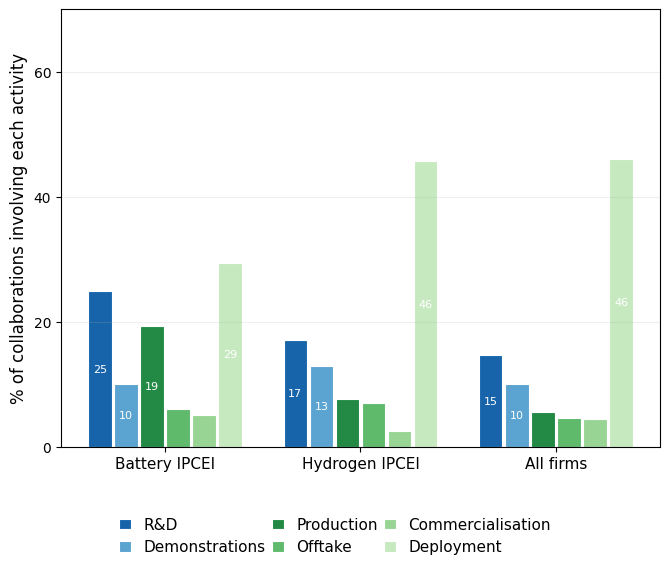

In [17]:
# ============================================================
# Collaboration activities: innovation pipeline composition
# ============================================================

fm = firm_master_ipcei.copy()
p  = partnership_master.copy()

# ── Activity columns and clean names ─────────────────────────────────────────
innovation_cols = [
    "r_and_d_collaborations",
    "demonstrations_and_pilots",
    "production_and_manufacturing",
    "offtake_agreements_and_futures",
    "commercialisation_and_product_launches",
    "adoption_and_deployments",
]
innovation_cols = [c for c in innovation_cols if c in p.columns]

col_labels = {
    "r_and_d_collaborations":               "R&D",
    "demonstrations_and_pilots":            "Demonstrations",
    "commercialisation_and_product_launches": "Commercialisation",
    "production_and_manufacturing":         "Production",
    "offtake_agreements_and_futures":       "Offtake",
    "adoption_and_deployments":             "Deployment",
}

cat_order = [col_labels[c] for c in innovation_cols]

category_colors = {
    "R&D":                    plt.cm.Blues(0.80),
    "Demonstrations":         plt.cm.Blues(0.55),
    "Production":             plt.cm.Greens(0.75),
    "Offtake":     plt.cm.Greens(0.55),
    "Commercialisation":      plt.cm.Greens(0.40),
    "Deployment":  plt.cm.Greens(0.25),
}

# ── Firm flags ────────────────────────────────────────────────────────────────
base = fm.drop_duplicates("Linkedin_name").copy()
types_lc = base["ipcei_types"].astype("string").str.lower()
base["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)
base["is_battery"]  = types_lc.str.contains("battery",  na=False)
base["is_ipcei"]    = base["treated_any"].fillna(0).astype(int) == 1

# ── Reshape to endpoint level ─────────────────────────────────────────────────
tmp = p.copy()
for col in innovation_cols:
    tmp[col] = pd.to_numeric(tmp[col], errors="coerce").fillna(0).astype(int)

src = tmp.rename(columns={"source": "Linkedin_name"})[
    ["Linkedin_name", "collaboration_id"] + innovation_cols]
tgt = tmp.rename(columns={"target": "Linkedin_name"})[
    ["Linkedin_name", "collaboration_id"] + innovation_cols]

endp = pd.concat([src, tgt], ignore_index=True).dropna(subset=["Linkedin_name"])
endp_full = endp.merge(
    base[["Linkedin_name", "is_hydrogen", "is_battery", "is_ipcei"]],
    on="Linkedin_name", how="left"
)

# Rename columns to clean labels
endp_full = endp_full.rename(columns=col_labels)

# ── Build shares ──────────────────────────────────────────────────────────────
group_specs = {
    "Hydrogen IPCEI": endp_full.loc[endp_full["is_ipcei"] & endp_full["is_hydrogen"]],
    "Battery IPCEI":  endp_full.loc[endp_full["is_ipcei"] & endp_full["is_battery"]],
    "All firms":      endp_full.copy(),
}

records = []
for firm_group, sub in group_specs.items():
    total = sub["collaboration_id"].nunique()
    for cat in cat_order:
        n = sub.loc[sub[cat] == 1, "collaboration_id"].nunique()
        records.append({"firm_group": firm_group, "category": cat,
                        "n": n, "total": total})

df = pd.DataFrame(records)
# Independent prevalences: each activity's denominator is ALL collaborations
# in the firm_group, NOT the sum across (overlapping) activity categories.
# Activity flags are multiply-set per collaboration, so these shares do
# NOT sum to 100.
df["share"] = df.apply(
    lambda r: 100 * r["n"] / r["total"] if r["total"] > 0 else 0, axis=1
)

plot_df = (
    df.pivot(index="firm_group", columns="category", values="share")
      .fillna(0)
      .reindex(["Battery IPCEI", "Hydrogen IPCEI", "All firms"])
)[cat_order]

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6.8, 5.8))

n_groups = len(plot_df)
n_cats   = len(cat_order)
x        = np.arange(n_groups)
group_w  = 0.8
bar_w    = group_w / n_cats

# Grouped bars: one bar per activity within each firm_group (not stacked).
for c, cat in enumerate(cat_order):
    vals    = plot_df[cat].values
    offsets = x - group_w / 2 + (c + 0.5) * bar_w
    ax.bar(offsets, vals, width=bar_w * 0.9,
           label=cat,
           color=category_colors[cat],
           edgecolor="white", linewidth=0.8)
    for xi, v in zip(offsets, vals):
        if v >= 8:
            ax.text(xi, v / 2, f"{v:.0f}",
                    ha="center", va="center", fontsize=8, color="white")

ax.set_xticks(x)
ax.set_xticklabels(plot_df.index, fontsize=11)
ax.set_ylim(0, 70)
ax.set_yticks(np.arange(0, 71, 20))
ax.set_ylabel("% of collaborations involving each activity", fontsize=12)
style_ax(ax)
ax.grid(axis="y", alpha=0.2)
ax.grid(axis="x", visible=False)

handles, labels_leg = ax.get_legend_handles_labels()
fig.legend(handles, labels_leg,
           loc="lower center", bbox_to_anchor=(0.5, 0.01),
           ncol=3,
           frameon=False,
           handlelength=0.8,
           columnspacing=0.4,
           fontsize=11)

plt.tight_layout()
plt.subplots_adjust(bottom=0.22)
save_fig(fig, FIG_EXTRA, "collaborations_ipcei_innovation_prevalence_simple")
plt.show()


/var/folders/1w/t9ryrq_57m77f4wzbw78745m044mx9/T/ipykernel_73163/2974565865.py:161: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  v = float(plot_df2.loc[key, cat])


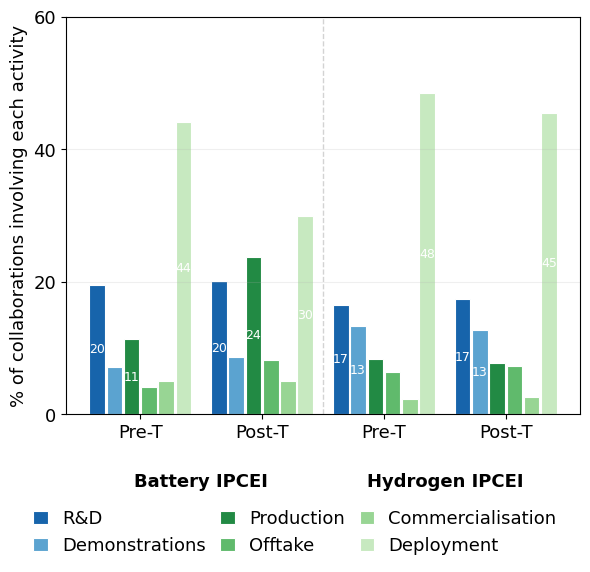

In [18]:
# ============================================================
# Collaboration activities: innovation pipeline composition pre/post
# ============================================================

fm = firm_master_ipcei.copy()
p  = partnership_master.copy()

date_col = "post_date"

# ── Activity columns and clean names ─────────────────────────────────────────
innovation_cols = [
    "r_and_d_collaborations",
    "demonstrations_and_pilots",
    "production_and_manufacturing",
    "offtake_agreements_and_futures",
    "commercialisation_and_product_launches",
    "adoption_and_deployments",
]
innovation_cols = [c for c in innovation_cols if c in p.columns]

col_labels = {
    "r_and_d_collaborations":               "R&D",
    "demonstrations_and_pilots":            "Demonstrations",
    "commercialisation_and_product_launches": "Commercialisation",
    "production_and_manufacturing":         "Production",
    "offtake_agreements_and_futures":       "Offtake",
    "adoption_and_deployments":             "Deployment",
}

cat_order = [col_labels[c] for c in innovation_cols]

category_colors = {
    "R&D":                    plt.cm.Blues(0.80),
    "Demonstrations":         plt.cm.Blues(0.55),
    "Production":             plt.cm.Greens(0.75),
    "Offtake":     plt.cm.Greens(0.55),
    "Commercialisation":      plt.cm.Greens(0.40),
    "Deployment":  plt.cm.Greens(0.25),
}

# ── Font sizes ────────────────────────────────────────────────────────────────
AXIS_LABEL_FS = 13
TICK_FS = 13
GROUP_LABEL_FS = 13
LEGEND_FS = 13
BAR_TEXT_FS = 13

# ── Firm flags ────────────────────────────────────────────────────────────────
base = fm.drop_duplicates("Linkedin_name").copy()
types_lc = base["ipcei_types"].astype("string").str.lower()
base["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)
base["is_battery"]  = types_lc.str.contains("battery",  na=False)
base["is_ipcei"]    = base["treated_any"].fillna(0).astype(int) == 1

# Per-firm treatment dates (firm-relative cohort alignment)
base["first_battery_date"]  = pd.to_datetime(base["first_battery_date"],  errors="coerce")
base["first_hydrogen_date"] = pd.to_datetime(base["first_hydrogen_date"], errors="coerce")
battery_treat_map  = dict(zip(base.loc[base["is_battery"],  "Linkedin_name"],
                              base.loc[base["is_battery"],  "first_battery_date"]))
hydrogen_treat_map = dict(zip(base.loc[base["is_hydrogen"], "Linkedin_name"],
                              base.loc[base["is_hydrogen"], "first_hydrogen_date"]))

# ── Reshape to endpoint level ─────────────────────────────────────────────────
tmp = p.copy()
for col in innovation_cols:
    tmp[col] = pd.to_numeric(tmp[col], errors="coerce").fillna(0).astype(int)
tmp["post_date"] = pd.to_datetime(tmp[date_col], errors="coerce")
tmp = tmp.dropna(subset=["post_date"]).copy()   # per-firm window bounds the sample (no calendar filter)

src = tmp.rename(columns={"source": "Linkedin_name"})[
    ["Linkedin_name", "collaboration_id", "post_date"] + innovation_cols]
tgt = tmp.rename(columns={"target": "Linkedin_name"})[
    ["Linkedin_name", "collaboration_id", "post_date"] + innovation_cols]

endp = pd.concat([src, tgt], ignore_index=True).dropna(subset=["Linkedin_name"])
endp_full = endp.merge(
    base[["Linkedin_name", "is_hydrogen", "is_battery", "is_ipcei"]],
    on="Linkedin_name", how="left"
)
endp_full = endp_full.rename(columns=col_labels)

# ── Per-firm cohort windows (firm-relative; POOLED across firms) ──────────────
# Each treated firm's collaborations are aligned to its OWN approval date:
#   pre  = [t - 12 months, t),   post = [t, t + 24 months).
# Within each (firm_group, period) the in-window collaboration_ids are POOLED
# across firms (collaboration-weighted, NOT equal firm weight), then prevalence
# = 100 * n(collabs with activity) / n(all collabs in pool).
PRE_M, POST_M = 12, 24
tech_specs = [
    ("Battery IPCEI",  "is_battery",  battery_treat_map),
    ("Hydrogen IPCEI", "is_hydrogen", hydrogen_treat_map),
]

records2 = []
for firm_group, flag, treat_map in tech_specs:
    sub_fg = endp_full.loc[endp_full["is_ipcei"] & endp_full[flag]].copy()
    sub_fg["t_date"] = pd.to_datetime(sub_fg["Linkedin_name"].map(treat_map))
    sub_fg = sub_fg[sub_fg["t_date"].notna()]

    in_pre  = ((sub_fg["post_date"] >= sub_fg["t_date"] - pd.DateOffset(months=PRE_M)) &
               (sub_fg["post_date"] <  sub_fg["t_date"]))
    in_post = ((sub_fg["post_date"] >= sub_fg["t_date"]) &
               (sub_fg["post_date"] <  sub_fg["t_date"] + pd.DateOffset(months=POST_M)))

    for period_key, period_label, mask in [
        ("pre",  "Pre-T",  in_pre),
        ("post", "Post-T", in_post),
    ]:
        pool  = sub_fg[mask]
        total = pool["collaboration_id"].nunique()
        for cat in cat_order:
            n = pool.loc[pool[cat] == 1, "collaboration_id"].nunique()
            records2.append({
                "firm_group":   firm_group,
                "period_key":   period_key,
                "period_label": period_label,
                "category":     cat,
                "n":            n,
                "total":        total
            })

df2 = pd.DataFrame(records2)
# Independent prevalences: each activity's denominator is ALL collaborations
# in the firm_group/period, NOT the sum across (overlapping) activity
# categories. Activity flags are multiply-set per collaboration, so these
# shares do NOT sum to 100.
df2["share"] = df2.apply(
    lambda r: 100 * r["n"] / r["total"] if r["total"] > 0 else 0, axis=1
)

plot_df2 = (
    df2.pivot(
        index=["firm_group", "period_key", "period_label"],
        columns="category", values="share"
    )
    .fillna(0)
    .reindex(columns=cat_order)
)

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 5.6))

firm_order2 = ["Battery IPCEI", "Hydrogen IPCEI"]
period_keys = ["pre", "post"]
n_cats      = len(cat_order)

# One column per (firm_group, period); activity bars grouped within each
# column (not stacked). Shares are independent prevalences and need not
# sum to 100.
col_keys   = [(fg, pk) for fg in firm_order2 for pk in period_keys]
col_center = {key: i for i, key in enumerate(col_keys)}
col_width  = 0.85
bar_w      = col_width / n_cats

for c, cat in enumerate(cat_order):
    xs, ys = [], []
    for key in col_keys:
        center = col_center[key]
        offset = center - col_width / 2 + (c + 0.5) * bar_w
        try:
            v = float(plot_df2.loc[key, cat])
        except KeyError:
            v = 0.0
        xs.append(offset)
        ys.append(v)

    ax.bar(
        xs, ys,
        width=bar_w * 0.9,
        label=cat,
        color=category_colors[cat],
        edgecolor="white", linewidth=0.8
    )

    for x, v in zip(xs, ys):
        if v >= 9:
            ax.text(
                x, v / 2, f"{v:.0f}",
                ha="center", va="center",
                fontsize=BAR_TEXT_FS - 4, color="white"
            )

# x-axis period labels
tick_xs, tick_labels = [], []
for key in col_keys:
    fg, pk = key
    tick_xs.append(col_center[key])
    lbl = df2.loc[
        (df2["firm_group"] == fg) & (df2["period_key"] == pk),
        "period_label"
    ].iloc[0]
    tick_labels.append(lbl)

ax.set_xticks(tick_xs)
ax.set_xticklabels(tick_labels, fontsize=TICK_FS)

# Group labels
group_centers = [
    np.mean([col_center[(fg, pk)] for pk in period_keys])
    for fg in firm_order2
]
for fg, cx in zip(firm_order2, group_centers):
    ax.annotate(
        fg,
        xy=(cx, 0), xycoords=("data", "axes fraction"),
        xytext=(0, -42), textcoords="offset points",
        ha="center", va="top",
        fontsize=GROUP_LABEL_FS, fontweight="bold",
        annotation_clip=False
    )

# Separator
sep_x = (col_center[("Battery IPCEI", "post")] +
         col_center[("Hydrogen IPCEI", "pre")]) / 2
ax.axvline(sep_x, color="lightgrey", linewidth=1, linestyle="--")

ax.set_ylim(0, 60)
ax.set_yticks(np.arange(0, 61, 20))
ax.set_ylabel("% of collaborations involving each activity", fontsize=AXIS_LABEL_FS)
ax.tick_params(axis="y", labelsize=TICK_FS)

style_ax(ax)
ax.grid(axis="y", alpha=0.2)
ax.grid(axis="x", visible=False)

handles, labels_leg = ax.get_legend_handles_labels()
fig.legend(
    handles, labels_leg,
    loc="lower center", bbox_to_anchor=(0.5, -0.03),
    ncol=3,
    frameon=False,
    handlelength=0.8,
    columnspacing=0.8,
    fontsize=LEGEND_FS
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.25, top=0.96)
save_fig(fig, FIG_EXTRA, "collaborations_ipcei_innovation_prevalence_prepost")
plt.show()


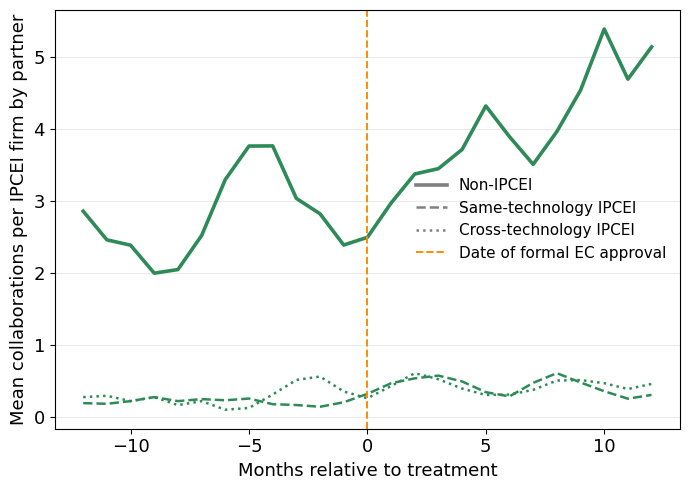

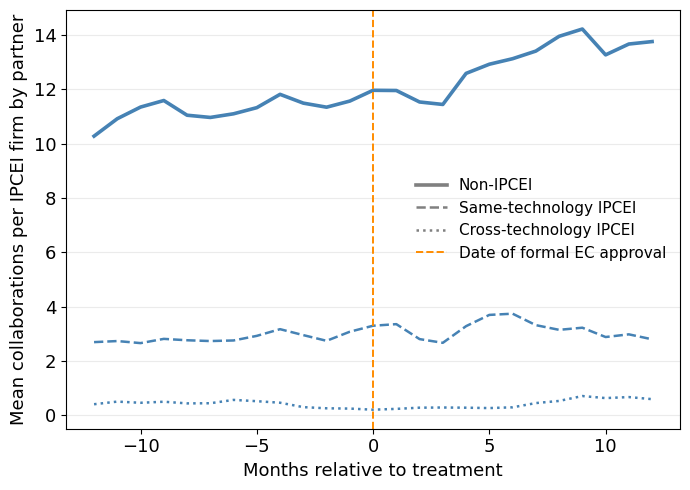

In [19]:
# ============================================================
# Collaboration composition over event time (LEVELS, not shares)
# ============================================================

def build_partner_type_event_levels(firm_master_ipcei, partnership_master, window=12):
    fm = firm_master_ipcei.copy()
    fm["first_battery_date"]  = pd.to_datetime(fm["first_battery_date"],  errors="coerce")
    fm["first_hydrogen_date"] = pd.to_datetime(fm["first_hydrogen_date"], errors="coerce")

    battery_firms  = set(fm.loc[fm["first_battery_date"].notna(),  "Linkedin_name"])
    hydrogen_firms = set(fm.loc[fm["first_hydrogen_date"].notna(), "Linkedin_name"])

    # focal firm × tech × treatment date
    treat_rows = []
    for _, row in fm.iterrows():
        firm = row["Linkedin_name"]
        if pd.notna(row["first_battery_date"]):
            treat_rows.append({"firm": firm, "tech": "Battery",  "t0": row["first_battery_date"]})
        if pd.notna(row["first_hydrogen_date"]):
            treat_rows.append({"firm": firm, "tech": "Hydrogen", "t0": row["first_hydrogen_date"]})
    treat_df = pd.DataFrame(treat_rows)

    pm = partnership_master.copy()
    pm["post_date"] = pd.to_datetime(pm["post_date"], errors="coerce")
    pm = pm.dropna(subset=["post_date", "collaboration_id"]).copy()

    # endpoint-long so the focal firm can be either source or target
    long = pd.concat([
        pm.rename(columns={"source": "firm", "target": "partner"})[
            ["firm", "partner", "collaboration_id", "post_date"]],
        pm.rename(columns={"target": "firm", "source": "partner"})[
            ["firm", "partner", "collaboration_id", "post_date"]],
    ], ignore_index=True)

    # keep only firms with treatment dates; event month relative to firm's own t0
    long = long.merge(treat_df, on="firm", how="inner")
    long["event_month"] = (
        (long["post_date"].dt.year - long["t0"].dt.year) * 12
        + (long["post_date"].dt.month - long["t0"].dt.month)
    )
    long = long[long["event_month"].between(-window, window)].copy()

    # classify partner type relative to focal firm's technology
    def classify_partner(row):
        if row["tech"] == "Battery":
            same_set, other_set = battery_firms, hydrogen_firms
        else:
            same_set, other_set = hydrogen_firms, battery_firms
        if row["partner"] in same_set:
            return "Same-technology IPCEI"
        elif row["partner"] in other_set:
            return "Cross-technology IPCEI"
        else:
            return "Non-IPCEI"
    long["partner_type"] = long.apply(classify_partner, axis=1)

    # one row per focal firm × event-month × partner_type × collaboration_id
    # (per-firm distinct-collaboration counts; avoids double counting within a firm)
    deduped = long.drop_duplicates(
        ["firm", "tech", "event_month", "partner_type", "collaboration_id"])

    # summed per-firm distinct-collab counts = firm-collaboration pairs
    summed = (deduped.groupby(["tech", "event_month", "partner_type"])
                     .size().reset_index(name="sum_collabs"))

    # focal firms PRESENT (any partner type) at each (tech, event_month) -- the
    # denominator. It varies by event-month across hydrogen's staggered cohorts,
    # which keeps the LEVEL comparable across event-months.
    firms_present = (deduped.groupby(["tech", "event_month"])["firm"]
                            .nunique().reset_index(name="n_firms"))

    # complete (tech, event_month, partner_type) grid -> 0 where a type is absent
    ptypes = ["Same-technology IPCEI", "Cross-technology IPCEI", "Non-IPCEI"]
    grid = firms_present.merge(pd.DataFrame({"partner_type": ptypes}), how="cross")
    out = grid.merge(summed, on=["tech", "event_month", "partner_type"], how="left")
    out["sum_collabs"] = out["sum_collabs"].fillna(0)

    # LEVEL: mean collaborations per firm present at that event-month
    out["mean_collabs"] = out["sum_collabs"] / out["n_firms"]
    return out


def plot_partner_type_composition_event_time(firm_master_ipcei, partnership_master):
    WINDOW = 12
    SMOOTH = 3

    agg = build_partner_type_event_levels(
        firm_master_ipcei=firm_master_ipcei,
        partnership_master=partnership_master,
        window=WINDOW
    )

    # Non-IPCEI carries the argument -> most prominent (solid, full weight);
    # the two IPCEI lines dashed/dotted.
    line_styles = {
        "Non-IPCEI":              {"linestyle": "-",  "linewidth": 2.6},
        "Same-technology IPCEI":  {"linestyle": "--", "linewidth": 1.8},
        "Cross-technology IPCEI": {"linestyle": ":",  "linewidth": 1.8},
    }

    legend_handles = [
        plt.Line2D([0], [0], color="grey", **ls, label=ptype)
        for ptype, ls in line_styles.items()
    ] + [
        plt.Line2D([0], [0], color="darkorange",
                   linestyle="--", linewidth=1.4,
                   label="Date of formal EC approval")
    ]

    for tech, color, figname in [
        ("Battery",  COLORS["two"][1], "collaborations_intra_ipcei_battery_lineplot"),
        ("Hydrogen", COLORS["two"][0], "collaborations_intra_ipcei_hydrogen_lineplot"),
    ]:
        fig, ax = plt.subplots(figsize=(7, 5))
        sub = agg[agg["tech"] == tech].copy()

        for ptype, ls in line_styles.items():
            s = (
                sub[sub["partner_type"] == ptype]
                .sort_values("event_month")
                .set_index("event_month")["mean_collabs"]
                .rolling(SMOOTH, center=True, min_periods=1)
                .mean()
            )
            ax.plot(s.index, s.values, color=color, **ls)

        ax.axvline(0, linestyle="--", color="darkorange", linewidth=1.4)

        ax.set_xlabel("Months relative to treatment", fontsize=13)
        ax.set_ylabel("Mean collaborations per IPCEI firm by partner", fontsize=13)
        ax.tick_params(axis="both", labelsize=13)
        style_ax(ax)

        ax.legend(handles=legend_handles, frameon=False,
                  fontsize=11, loc="center right")

        plt.tight_layout()
        save_fig(fig, FIG_SI, figname)   # cited in Methods (fig:intra_ipcei_eventtime) -> SI
        plt.show()


plot_partner_type_composition_event_time(firm_master_ipcei, partnership_master)


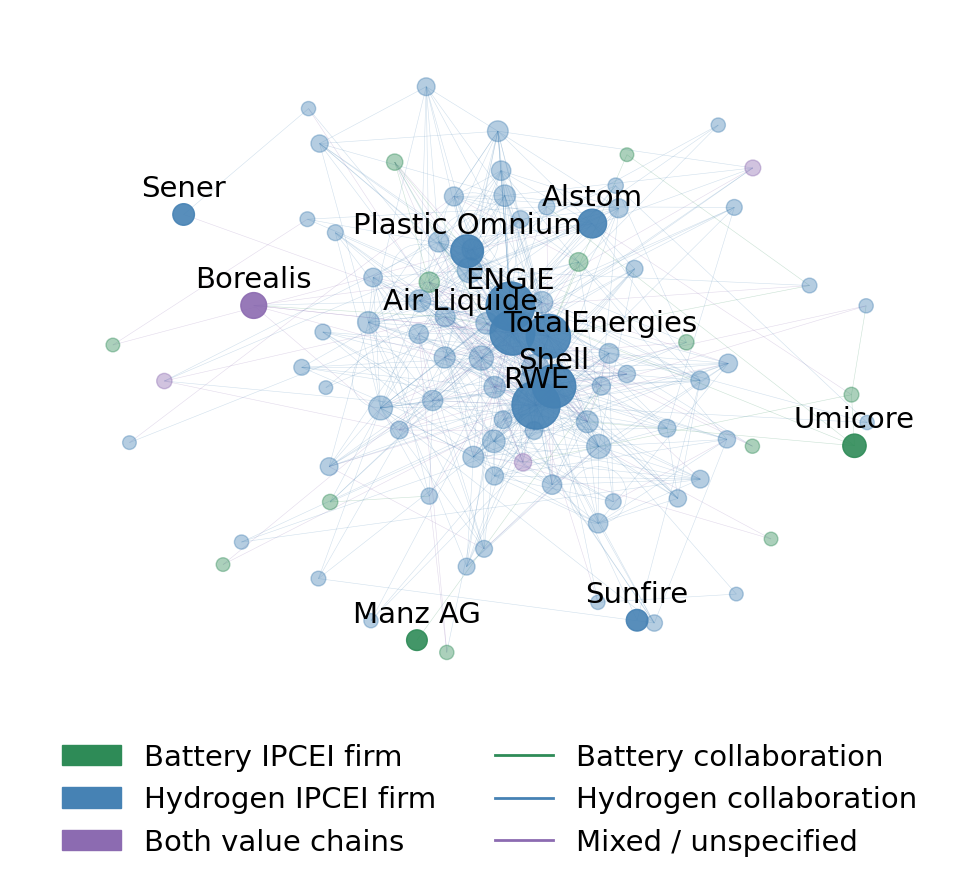

In [20]:
# ============================================================
# Collaboration composition pre-T
# Network plot
# ============================================================

def plot_intra_ipcei_network():
    import networkx as nx
    from matplotlib.lines import Line2D

    fm = firm_master_ipcei.copy()
    fm["first_battery_date"]  = pd.to_datetime(fm["first_battery_date"],  errors="coerce")
    fm["first_hydrogen_date"] = pd.to_datetime(fm["first_hydrogen_date"], errors="coerce")

    battery_firms  = set(fm.loc[fm["first_battery_date"].notna(),  "Linkedin_name"])
    hydrogen_firms = set(fm.loc[fm["first_hydrogen_date"].notna(), "Linkedin_name"])
    all_ipcei      = battery_firms | hydrogen_firms

    t0_lookup = {}
    for _, row in fm.iterrows():
        dates = []
        if pd.notna(row["first_battery_date"]):
            dates.append(row["first_battery_date"])
        if pd.notna(row["first_hydrogen_date"]):
            dates.append(row["first_hydrogen_date"])
        if dates:
            t0_lookup[row["Linkedin_name"]] = min(dates)

    pm = partnership_master.copy()
    pm["post_date"] = pd.to_datetime(pm["post_date"], errors="coerce")
    pm = pm.dropna(subset=["post_date"])

    edges = []
    for firm, t0 in t0_lookup.items():
        window_start = t0 - pd.DateOffset(months=12)
        sub = pm[
            (pm["source"] == firm) &
            (pm["target"].isin(all_ipcei)) &
            (pm["post_date"] >= window_start) &
            (pm["post_date"] < t0)
        ]
        for _, row in sub.iterrows():
            is_battery  = row.get("Battery",  0) == 1
            is_hydrogen = row.get("Hydrogen", 0) == 1
            if is_battery and not is_hydrogen:
                edge_tech = "Battery"
            elif is_hydrogen and not is_battery:
                edge_tech = "Hydrogen"
            else:
                edge_tech = "Mixed"
            edges.append((firm, row["target"], edge_tech))

    if not edges:
        print("No intra-IPCEI edges found in pre-approval window.")
        return

    edge_df = pd.DataFrame(edges, columns=["source", "target", "tech"])

    G_full = nx.Graph()
    for _, row in edge_df.iterrows():
        if G_full.has_edge(row["source"], row["target"]):
            G_full[row["source"]][row["target"]]["weight"] += 1
        else:
            G_full.add_edge(row["source"], row["target"],
                            weight=1, tech=row["tech"])

    nodes_to_keep = [n for n, d in G_full.degree() if d >= 2]
    G = G_full.subgraph(nodes_to_keep).copy()

    if len(G.nodes()) == 0:
        print("No nodes remain after filtering.")
        return

    deg = nx.degree_centrality(G)

    def node_color(n):
        in_b = n in battery_firms
        in_h = n in hydrogen_firms
        if in_b and in_h:   return "#8c6bb1"
        if in_b:            return COLORS["two"][1]
        if in_h:            return COLORS["two"][0]
        return "#cccccc"

    edge_color_map = {
        "Battery":  COLORS["two"][1],
        "Hydrogen": COLORS["two"][0],
        "Mixed":    "#8c6bb1",
    }

    name_lookup = (
        fm[["Linkedin_name", "name"]]
        .copy()
        .assign(
            Linkedin_name = lambda d: d["Linkedin_name"].astype(str).str.strip(),
            name          = lambda d: d["name"].astype(str).str.strip()
        )
        .dropna(subset=["name"])
        .query("name != '' and name != 'nan'")
        .drop_duplicates("Linkedin_name")
        .set_index("Linkedin_name")["name"]
    )

    N_CENTER = 4
    N_MIDDLE = 5
    N_EDGE   = 3

    all_nodes_sorted = sorted(deg.keys(), key=lambda n: deg[n], reverse=True)
    top_nodes    = all_nodes_sorted[:N_CENTER]
    bottom_nodes = all_nodes_sorted[-N_EDGE:]
    remaining    = all_nodes_sorted[N_CENTER:-N_EDGE]
    step         = max(1, len(remaining) // N_MIDDLE)
    middle_nodes = remaining[::step][:N_MIDDLE]
    label_nodes  = set(top_nodes) | set(middle_nodes) | set(bottom_nodes)

    labels = {
        n: name_lookup.get(n, n)[:18]
        for n in label_nodes
        if name_lookup.get(n, "") not in ("", n)
    }

    node_list        = list(G.nodes())
    labelled_nodes   = [n for n in node_list if n in label_nodes]
    unlabelled_nodes = [n for n in node_list if n not in label_nodes]

    edge_colors = [edge_color_map[G[u][v]["tech"]] for u, v in G.edges()]
    edge_widths = [0.5 + G[u][v]["weight"] * 0.5 for u, v in G.edges()]

    # ── Layout with correct tuple stretching ─────────────────
    raw_pos = nx.spring_layout(G, k=2.0, iterations=100, seed=42)

    xs = np.array([raw_pos[n][0] for n in raw_pos])
    ys = np.array([raw_pos[n][1] for n in raw_pos])
    x_min, x_max = xs.min(), xs.max()
    y_min, y_max = ys.min(), ys.max()
    SCALE = 2.2

    pos = {
        n: (
            (raw_pos[n][0] - x_min) / (x_max - x_min) * SCALE - SCALE / 2,
            (raw_pos[n][1] - y_min) / (y_max - y_min) * SCALE - SCALE / 2
        )
        for n in raw_pos
    }

    pos_labels = {k: (v[0], v[1] + 0.10) for k, v in pos.items()}

    # Manual label offsets
    reverse_lookup = {v: k for k, v in name_lookup.items()}
    label_offsets  = {
        "TotalEnergies": (0.15, -0.05),
        "Air Liquide":   (-0.15, 0.02),
    }
    for display_name, (dx, dy) in label_offsets.items():
        linkedin_key = reverse_lookup.get(display_name) or next(
            (k for k, v in name_lookup.items()
             if display_name.lower() in v.lower()), None
        )
        if linkedin_key and linkedin_key in pos_labels:
            x, y = pos_labels[linkedin_key]
            pos_labels[linkedin_key] = (x + dx, y + dy)

    # ── Draw ─────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(10, 9))

    nx.draw_networkx_edges(G, pos, ax=ax,
                           edge_color=edge_colors,
                           width=0.4, alpha=0.25)

    nx.draw_networkx_nodes(G, pos, ax=ax,
                           nodelist=labelled_nodes,
                           node_color=[node_color(n) for n in labelled_nodes],
                           node_size=[200 + deg[n] * 2000 for n in labelled_nodes],
                           alpha=0.90)

    nx.draw_networkx_nodes(G, pos, ax=ax,
                           nodelist=unlabelled_nodes,
                           node_color=[node_color(n) for n in unlabelled_nodes],
                           node_size=[80 + deg[n] * 800 for n in unlabelled_nodes],
                           alpha=0.40)

    nx.draw_networkx_labels(G, pos_labels, labels=labels,
                            ax=ax, font_size=21)

    # Explicit axis limits to use full canvas
    ax.set_xlim(-SCALE / 2 - 0.3, SCALE / 2 + 0.3)
    ax.set_ylim(-SCALE / 2 - 0.3, SCALE / 2 + 0.3)
    ax.axis("off")

    legend_elements = [
        mpatches.Patch(color=COLORS["two"][1],  label="Battery IPCEI firm"),
        mpatches.Patch(color=COLORS["two"][0],  label="Hydrogen IPCEI firm"),
        mpatches.Patch(color="#8c6bb1",          label="Both value chains"),
        Line2D([0], [0], color=COLORS["two"][1], linewidth=2,
               label="Battery collaboration"),
        Line2D([0], [0], color=COLORS["two"][0], linewidth=2,
               label="Hydrogen collaboration"),
        Line2D([0], [0], color="#8c6bb1",         linewidth=2,
               label="Mixed / unspecified"),
    ]

    fig.legend(handles=legend_elements, loc="lower center", ncol=2,
               frameon=False, fontsize=21,
               bbox_to_anchor=(0.5, 0.01))

    ax.set_position([0.02, 0.18, 0.96, 0.80])
    save_fig(fig, FIG_EXTRA, "collaborations_intra_ipcei_preapproval_network", tight=False)
    plt.show()

plot_intra_ipcei_network()


In [21]:
# ============================================================
# Partner overlap between treated firms and matched controls
# ============================================================

def compute_partner_overlap(cs_panel, partnership_master, tech_name,
                            start_date=None, end_date=None,
                            save_prefix=None):
    """
    Compute partner-set overlap between treated firms and their matched controls.

    Overlap metrics:
      - n_treated_partners
      - n_control_partners
      - n_shared_partners
      - jaccard_overlap = shared / union

    Notes:
      - Uses unique collaboration partners from partnership_master
      - Treats source/target symmetrically
      - If start_date/end_date are given, restricts collaborations to that window
    """

    # --------------------------------------------------------
    # 1) Reduce to one row per matched firm
    # --------------------------------------------------------
    matched = (
        cs_panel[["Linkedin_name", "is_treated", "is_control", "matched_to"]]
        .drop_duplicates()
        .copy()
    )

    # treated firm's own id is stored in matched_to in your saved panels
    treated_units = matched.loc[matched["is_treated"] == 1, ["Linkedin_name", "matched_to"]].copy()
    controls      = matched.loc[matched["is_control"] == 1, ["Linkedin_name", "matched_to"]].copy()

    # If treated rows have matched_to missing for some reason, fall back to own name
    treated_units["treated_id"] = treated_units["matched_to"].fillna(treated_units["Linkedin_name"])
    controls["treated_id"] = controls["matched_to"]

    # control → treated pair table
    pair_df = (
        controls.rename(columns={"Linkedin_name": "control_firm"})
        .merge(
            treated_units[["treated_id", "Linkedin_name"]].rename(columns={"Linkedin_name": "treated_firm"}),
            on="treated_id",
            how="left"
        )
        [["treated_id", "treated_firm", "control_firm"]]
        .dropna()
        .drop_duplicates()
        .copy()
    )

    # --------------------------------------------------------
    # 2) Build partner sets from collaboration data
    # --------------------------------------------------------
    p = partnership_master.copy()
    p["post_date"] = pd.to_datetime(p["post_date"], errors="coerce")

    if start_date is not None:
        p = p.loc[p["post_date"] >= pd.Timestamp(start_date)].copy()
    if end_date is not None:
        p = p.loc[p["post_date"] < pd.Timestamp(end_date)].copy()

    # make collaborations undirected at the firm level
    long = pd.concat([
        p.rename(columns={"source": "firm", "target": "partner"})[["firm", "partner", "collaboration_id"]],
        p.rename(columns={"target": "firm", "source": "partner"})[["firm", "partner", "collaboration_id"]],
    ], ignore_index=True)

    long = long.dropna(subset=["firm", "partner"]).copy()

    partner_sets = (
        long.groupby("firm")["partner"]
        .agg(lambda s: set(pd.Series(s).dropna().astype(str)))
        .to_dict()
    )

    # --------------------------------------------------------
    # 3) Overlap metrics for each treated-control pair
    # --------------------------------------------------------
    rows = []
    for _, row in pair_df.iterrows():
        treated_firm = row["treated_firm"]
        control_firm = row["control_firm"]

        treated_partners = partner_sets.get(treated_firm, set())
        control_partners = partner_sets.get(control_firm, set())

        shared = treated_partners & control_partners
        union  = treated_partners | control_partners

        rows.append({
            "treated_firm": treated_firm,
            "control_firm": control_firm,
            "n_treated_partners": len(treated_partners),
            "n_control_partners": len(control_partners),
            "n_shared_partners": len(shared),
            "jaccard_overlap": len(shared) / len(union) if len(union) > 0 else np.nan,
            "shared_partner_examples": ", ".join(sorted(list(shared))[:10]) if len(shared) > 0 else ""
        })

    overlap_df = pd.DataFrame(rows)

    # --------------------------------------------------------
    # 4) Summary printout
    # --------------------------------------------------------
    print("\n" + "=" * 70)
    print(f"{tech_name.upper()} — PARTNER OVERLAP BETWEEN TREATED FIRMS AND MATCHED CONTROLS")
    print("=" * 70)

    if overlap_df.empty:
        print("No treated-control pairs found.")
        return overlap_df

    print(f"Matched treated-control pairs: {len(overlap_df)}")
    print(f"Pairs with any shared partners: {(overlap_df['n_shared_partners'] > 0).sum()} "
          f"({100 * (overlap_df['n_shared_partners'] > 0).mean():.1f}%)")
    print(f"Mean shared partners: {overlap_df['n_shared_partners'].mean():.2f}")
    print(f"Median shared partners: {overlap_df['n_shared_partners'].median():.2f}")
    print(f"Mean Jaccard overlap: {overlap_df['jaccard_overlap'].mean():.4f}")
    print(f"Median Jaccard overlap: {overlap_df['jaccard_overlap'].median():.4f}")

    print("\nTop 10 pairs by Jaccard overlap:")
    display(
        overlap_df.sort_values(
            ["jaccard_overlap", "n_shared_partners"],
            ascending=[False, False]
        ).head(10)
    )

    # --------------------------------------------------------
    # 5) Save outputs (optional)
    # --------------------------------------------------------
    if save_prefix is not None:
        out_path = results_path("tables", TAB_MAIN, f"{save_prefix}_partner_overlap_pairs.csv")
        out_path.parent.mkdir(parents=True, exist_ok=True)
        overlap_df.to_csv(out_path, index=False)
        print(f"\nSaved pair-level overlap table to: {out_path}")

        summary_df = pd.DataFrame([{
            "technology": tech_name,
            "n_pairs": len(overlap_df),
            "share_with_any_overlap_pct": 100 * (overlap_df["n_shared_partners"] > 0).mean(),
            "mean_shared_partners": overlap_df["n_shared_partners"].mean(),
            "median_shared_partners": overlap_df["n_shared_partners"].median(),
            "mean_jaccard_overlap": overlap_df["jaccard_overlap"].mean(),
            "median_jaccard_overlap": overlap_df["jaccard_overlap"].median(),
        }])

        summary_path = results_path("tables", TAB_MAIN, f"{save_prefix}_partner_overlap_summary.csv")
        summary_df.to_csv(summary_path, index=False)
        print(f"Saved summary overlap table to: {summary_path}")

    return overlap_df


# ============================================================
# Run for primary matched samples
# ============================================================

battery_overlap = compute_partner_overlap(
    battery_cs,
    partnership_master,
    tech_name="Battery",
    start_date="2020-01-01",   # optional; remove if you want full sample
    end_date="2026-01-01",
    save_prefix="battery_spec2"
)

hydrogen_overlap = compute_partner_overlap(
    hydrogen_cs,
    partnership_master,
    tech_name="Hydrogen",
    start_date="2020-01-01",
    end_date="2026-01-01",
    save_prefix="hydrogen_spec2"
)



BATTERY — PARTNER OVERLAP BETWEEN TREATED FIRMS AND MATCHED CONTROLS
Matched treated-control pairs: 195
Pairs with any shared partners: 72 (36.9%)
Mean shared partners: 3.59
Median shared partners: 0.00
Mean Jaccard overlap: 0.0054
Median Jaccard overlap: 0.0000

Top 10 pairs by Jaccard overlap:


,treated_firm,control_firm,n_treated_partners,n_control_partners,n_shared_partners,jaccard_overlap,shared_partner_examples
155,arkema,saint-gobain,589,463,74,0.075665,"AIT Austrian Institute of Technology, AVESTA, ..."
111,inobat1,kukaglobal,210,118,18,0.058065,"acc-automotive-cells-company, batteryline-com,..."
187,avl,volvo-trucks,853,952,74,0.042750,"abb-e-mobility, alice-logistics, audi-ag, bake..."
63,arkema,eaton,589,512,37,0.034774,"abb, airbusgroup, austrian-institute-of-techno..."
129,borealis,neoen-renewables,258,448,22,0.032164,"ademe, afry, airliquide, axpo-group, axpo-nord..."
154,borealis,sabic,258,121,11,0.029891,"2633, abb, airliquide, basf, covestro, engie-b..."
95,borealis,honeywell,258,634,25,0.028835,"2633, abb, adnoc, adnocgroup, airliquide, avl,..."
194,northvolt,zf-group,518,385,25,0.028474,Federal Ministry for Economic Affairs and Clim...
116,elringklinger,liebherr,171,307,12,0.025751,"airbusgroup, alstom, avl, ballard-power-system..."
65,arkema,edf-european-affairs,589,135,18,0.025496,"airbusgroup, alstom, arcelormittal, cea, edf, ..."



Saved pair-level overlap table to: /Users/go82gax/Documents/Projekte/IPCEI/Analyse/PythonProject/ipcei-spillovers/results/tables/post-audit/psm/battery_spec2_partner_overlap_pairs.csv
Saved summary overlap table to: /Users/go82gax/Documents/Projekte/IPCEI/Analyse/PythonProject/ipcei-spillovers/results/tables/post-audit/psm/battery_spec2_partner_overlap_summary.csv



HYDROGEN — PARTNER OVERLAP BETWEEN TREATED FIRMS AND MATCHED CONTROLS
Matched treated-control pairs: 251
Pairs with any shared partners: 124 (49.4%)
Mean shared partners: 7.48
Median shared partners: 0.00
Mean Jaccard overlap: 0.0083
Median Jaccard overlap: 0.0000

Top 10 pairs by Jaccard overlap:


,treated_firm,control_firm,n_treated_partners,n_control_partners,n_shared_partners,jaccard_overlap,shared_partner_examples
211,enbw,sse-renewables,1123,965,202,0.107105,"50hertz-transmission-gmbh, H2sea - Offshore Hy..."
76,enel_green_power,edp,1112,691,149,0.090085,"aalborg-universitet, abb, acciona, acciona-sol..."
243,airliquide,wartsila,2266,1259,232,0.070452,"2633, Alsa, Bioscor, CHEMGAS S.R.L., CHEMGAS ..."
240,plastic-omnium,vicat,279,267,34,0.066406,"7467, ademe, airbusgroup, airliquide, alstom, ..."
145,avl,johnson-matthey,853,655,93,0.065724,"advanced-propulsion-centre-uk, airliquide, ark..."
1,eustream-a.s.,28153947,82,16,6,0.065217,"amber-grid-ab, conexus-baltic-grid, gasgrid, g..."
23,avl,ballard-power-systems,853,1136,121,0.064775,"airbusgroup, airliquide, alstom, arrivagroup, ..."
136,eni,hydrogen-europe,685,1471,100,0.048638,"AGICI, Edison, FINCANTIERI, H2IT - Associazion..."
107,gasunie-deutschland,gelsenwasser-ag,269,84,16,0.047478,"NaTran Deutschland, Uniper, deutscher-verein-d..."
216,uniper-se,stedin,609,496,49,0.046402,"abb, airliquide, alliander, battolysersystems,..."



Saved pair-level overlap table to: /Users/go82gax/Documents/Projekte/IPCEI/Analyse/PythonProject/ipcei-spillovers/results/tables/post-audit/psm/hydrogen_spec2_partner_overlap_pairs.csv
Saved summary overlap table to: /Users/go82gax/Documents/Projekte/IPCEI/Analyse/PythonProject/ipcei-spillovers/results/tables/post-audit/psm/hydrogen_spec2_partner_overlap_summary.csv


In [22]:
# ============================================================
# Supplementary: full collaboration type inventory (counts)
# ============================================================
p = partnership_master.copy()
total = p["collaboration_id"].nunique()

def counts_for(cols):
    present = [c for c in cols if c in p.columns]
    cl = p.groupby("collaboration_id")[present].max()
    out = [(c, int(cl[c].sum())) for c in present]
    return out

tech_cols = [
    "Biomass","Biofuels","Biogas","Wind","Offshore_Wind","Solar","Concentrated_Solar",
    "Waste_to_Heat","Direct_Air_Capture","Carbon_Capture_And_Storage","Biochar",
    "Carbon_Direct_Removal","BECCS","Hydrogen","Nuclear_Energy","Nuclear_Fusion",
    "Hydro_Energy","Geothermal","Battery","Electric_Vehicles","Sustainable_Aviation_Fuels",
    "E_Fuels","Marine_Energy","Heat_Pumps","Railway","Electric_Shipping",
    "Electric_Aviation","Fuel_Cell_Aviation","Other_Technology",
]
activity_cols = [
    "r_and_d_collaborations","demonstrations_and_pilots","commercialisation_and_product_launches",
    "production_and_manufacturing","offtake_agreements_and_futures","adoption_and_deployments",
    "operations_and_maintenance","grants","equity_investments","loans",
    "other_unspecified_finance","spin_offs","joint_ventures",
    "incubators_and_accelerator_programs","certification_and_approvals","training",
]
domain_cols = [
    "core_technology","infrastructure","software_and_digital_platforms",
    "raw_materials","recycling","other_complementary_activities",
]

for group, cols in [("A. Technology", tech_cols),
                    ("B. Activity type", activity_cols),
                    ("C. Activity domain", domain_cols)]:
    print(f"\n=== {group} ===")
    res = sorted(counts_for(cols), key=lambda x: -x[1])  # rank by frequency
    for name, n in res:
        print(f"  {name:42s} {n:>8,}  {100*n/total:5.1f}%")

print(f"\nTotal unique collaborations: {total:,}")



=== A. Technology ===


  Solar                                       169,089   24.1%
  Electric_Vehicles                           128,289   18.3%
  Hydrogen                                    112,721   16.1%
  Battery                                     106,230   15.1%
  Wind                                         93,278   13.3%
  Offshore_Wind                                51,117    7.3%
  Other_Technology                             38,765    5.5%
  Biogas                                       19,532    2.8%
  Carbon_Capture_And_Storage                   19,301    2.8%
  Electric_Shipping                            16,476    2.3%
  Heat_Pumps                                   14,485    2.1%
  Biofuels                                     13,687    2.0%
  Sustainable_Aviation_Fuels                   12,489    1.8%
  Nuclear_Energy                               11,018    1.6%
  Geothermal                                   10,303    1.5%
  Marine_Energy                                 9,599    1.4%
  Hydro_

  adoption_and_deployments                    323,723   46.1%
  r_and_d_collaborations                      102,863   14.7%
  demonstrations_and_pilots                    70,580   10.1%
  grants                                       45,036    6.4%
  equity_investments                           40,284    5.7%
  production_and_manufacturing                 39,472    5.6%
  offtake_agreements_and_futures               32,768    4.7%
  commercialisation_and_product_launches       31,325    4.5%
  training                                     29,356    4.2%
  other_unspecified_finance                    20,758    3.0%
  joint_ventures                               14,734    2.1%
  loans                                        13,409    1.9%
  operations_and_maintenance                   12,376    1.8%
  certification_and_approvals                   9,240    1.3%
  incubators_and_accelerator_programs           7,505    1.1%
  spin_offs                                     2,567    0.4%

=== C. 

  core_technology                             531,618   75.8%
  infrastructure                              127,719   18.2%
  software_and_digital_platforms               40,007    5.7%
  other_complementary_activities               14,298    2.0%
  recycling                                    11,199    1.6%
  raw_materials                                 1,065    0.2%

Total unique collaborations: 701,566


## 4. Supplementary Information

Identification robustness: PSM-vs-unmatched pre-trend comparison table and event-study overlay.

In [23]:
# ============================================================
# SI: pre-trend comparison, PSM vs unmatched.
# The evidence for choosing matching: PSM delivers parallel trends for both
# technologies; the unmatched (no-matching) design fails them for hydrogen.
# Reads BOTH methods directly (independent of the METHOD switch above).
# ============================================================
def build_pretrend_table():
    cols = ["Technology", "Outcome", "pretrend_p_value", "pretrend_test"]
    def _load(method):
        return pd.read_csv(
            R_RESULTS_DIR / method / "composition_techtagged" / "month"
            / "att_techtagged_table.csv")[cols]
    psm = _load("psm").rename(columns={"pretrend_p_value": "PSM", "pretrend_test": "test_psm"})
    unm = _load("unmatched").rename(columns={"pretrend_p_value": "Unmatched", "pretrend_test": "test_unm"})
    m = psm.merge(unm, on=["Technology", "Outcome"])
    order = ["Technology-tagged collaborations", "Non-funded collaborations",
             "Cross-border collaborations", "EU-internal collaborations",
             "International collaborations", "National collaborations",
             "Cross-sector collaborations", "Same-sector collaborations"]
    m["_o"] = m["Outcome"].map({o: i for i, o in enumerate(order)})
    m = m.dropna(subset=["_o"]).sort_values(["Technology", "_o"])
    out = m[["Technology", "Outcome", "PSM", "Unmatched", "test_unm"]].rename(
        columns={"test_unm": "Test"})
    out["fails_unmatched"] = out["Unmatched"] < 0.05
    # Working CSV, not an SI exhibit: the SI table itself is built by
    # ipcei_spillovers.tables from the same R outputs. Kept in post-audit/
    # so results/tables/si/ holds only what the SI actually inputs.
    _p = results_path("tables", "post-audit", "psm", "pretrend_comparison_psm_vs_unmatched.csv")
    _p.parent.mkdir(parents=True, exist_ok=True)
    out.to_csv(_p, index=False)
    try:
        out.drop(columns="fails_unmatched").to_latex(
            str(_p).replace(".csv", ".tex"), index=False, float_format="%.2f")
    except Exception as e:
        print("LaTeX export skipped:", e)
    print("Pre-trend p (PSM vs unmatched); <0.05 fails parallel trends:")
    print(out.to_string(index=False))
    return out

pretrend_table = build_pretrend_table()


Pre-trend p (PSM vs unmatched); <0.05 fails parallel trends:
Technology                          Outcome   PSM  Unmatched Test  fails_unmatched
   Battery Technology-tagged collaborations 0.580      0.355 Wald            False
   Battery        Non-funded collaborations 0.482      0.329 Wald            False
   Battery      Cross-border collaborations 0.347      0.391 Wald            False
   Battery       EU-internal collaborations 0.423      0.511 Wald            False
   Battery     International collaborations 0.344      0.338 Wald            False
   Battery          National collaborations 0.706      0.559 Wald            False
   Battery      Cross-sector collaborations 0.529      0.250 Wald            False
   Battery      Cross-sector collaborations 0.529      0.332 Wald            False
   Battery       Same-sector collaborations 0.391      0.677 Wald            False
  Hydrogen Technology-tagged collaborations 0.441      0.000 Wald             True
  Hydrogen        Non-fund

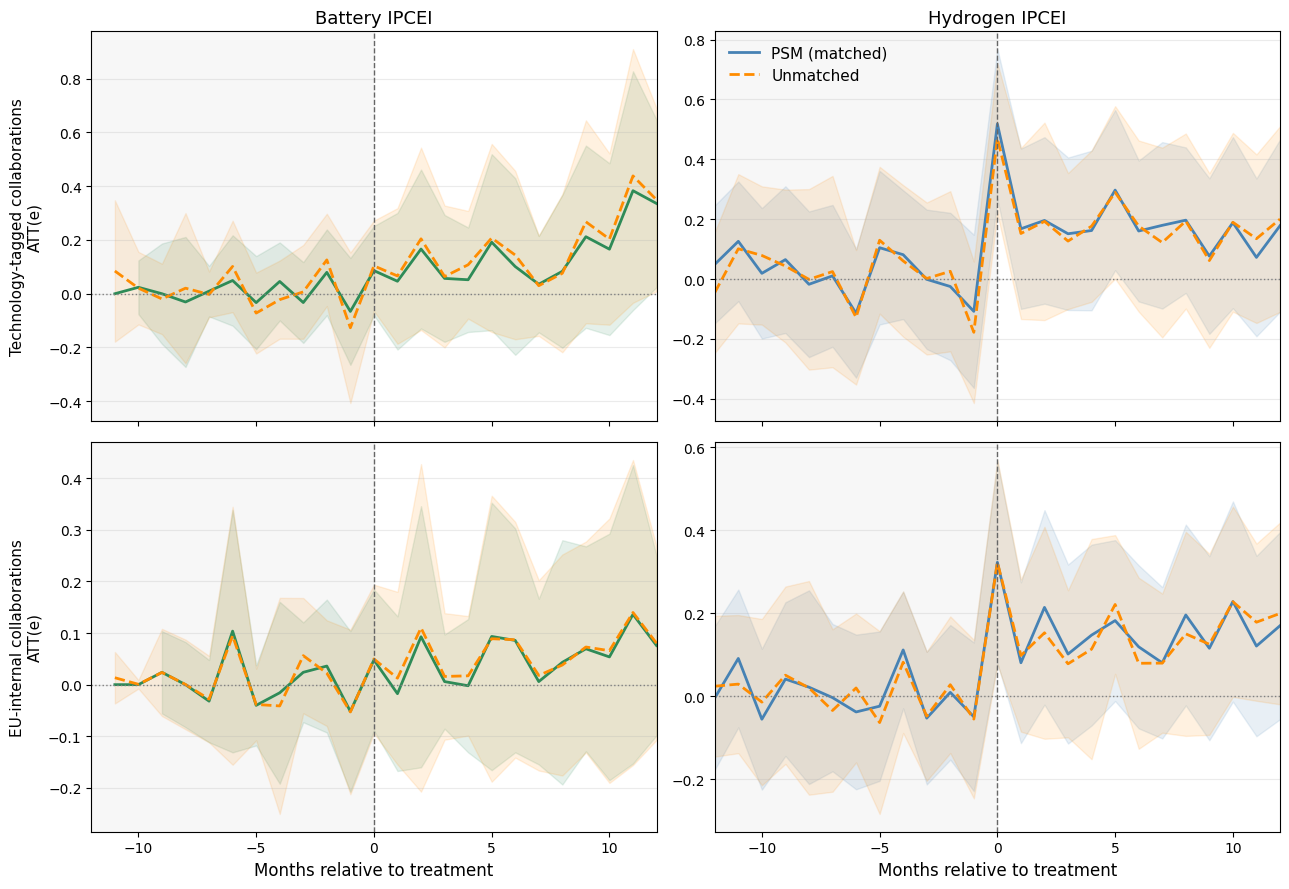

In [24]:
# ============================================================
# SI figure: event-study overlay, PSM vs unmatched.
# Shades the pre-period (e<0): PSM pre-coefficients hug zero; the unmatched
# hydrogen pre-coefficients trend, i.e. parallel trends fail without matching.
# ============================================================
def plot_pretrend_overlay():
    def _es(method):
        return pd.read_csv(
            R_RESULTS_DIR / method / "composition_techtagged" / "month"
            / "event_study_techtagged.csv")
    psm_es, unm_es = _es("psm"), _es("unmatched")
    outcomes = ["Technology-tagged collaborations", "EU-internal collaborations"]
    techs = [("Battery", COLORS["two"][1]), ("Hydrogen", COLORS["two"][0])]
    fig, axes = plt.subplots(len(outcomes), len(techs), figsize=(13, 9), sharex=True)
    for r, oc in enumerate(outcomes):
        for c, (tech, color) in enumerate(techs):
            ax = axes[r, c]
            lab = f"{tech} -- {oc}"
            for es, name, col, ls in [(psm_es, "PSM (matched)", color, "-"),
                                      (unm_es, "Unmatched", "#FF8C00", "--")]:
                d = es[es["label"] == lab]
                d = d[(d["e"] >= -12) & (d["e"] <= 12)]
                if d.empty:
                    continue
                ax.plot(d["e"], d["att"], color=col, ls=ls, lw=2, label=name)
                ax.fill_between(d["e"], d["ci_lower"], d["ci_upper"], color=col, alpha=0.12)
            ax.axvspan(-12, 0, color="grey", alpha=0.06)     # pre-period
            ax.axhline(0, ls=":", color="grey", lw=1)
            ax.axvline(0, ls="--", color="#666666", lw=1)
            ax.set_xlim(-12, 12)
            style_ax(ax)
            if r == 0:
                ax.set_title(f"{tech} IPCEI", fontsize=13)
            if c == 0:
                ax.set_ylabel(f"{oc}\nATT(e)", fontsize=11)
            if r == len(outcomes) - 1:
                ax.set_xlabel("Months relative to treatment", fontsize=12)
            if r == 0 and c == 1:
                ax.legend(frameon=False, fontsize=11, loc="upper left")
    plt.tight_layout()
    save_fig(fig, FIG_SI, "pretrend_overlay_psm_vs_unmatched")
    plt.show()

plot_pretrend_overlay()


In [ ]:
# ============================================================
# SI figure: statistical power for the insignificant outcomes.
#
# Reads the design-based power simulations written by the R scripts:
#   07_..._psm.Rmd -> power_all_outcomes.csv     (composition outcomes)
#   06_..._psm.Rmd -> power_intensity_long.csv   (total collaborations)
#   10_..._country.R -> p6_power_contrasts.csv   (direct contrasts)
# All three use the same effect grid, which BEGINS AT 0. The simulation imposes
# the null on the real treated firms, so a true effect of zero must be rejected
# at about the nominal 5%. That size check travels with every curve, and it is
# the first thing to read in the MDE table: if size is far from 0.05 the design
# is broken and the whole column is void. The rest of the grid is 5, 10, 15, 20,
# 30 and 40%, so the three files stack.
#
# The simulation was REWRITTEN in Nov 2026. The earlier design built synthetic
# treated firms by drawing them from the matched CONTROLS, which overstated
# power in every cell -- by 1.07x on hydrogen non-funded up to 4.5x on battery
# EU-internal -- because controls are 96-99% zeros on the technology-tagged
# outcomes, so a constant added to a near-degenerate series is detected almost
# surely. Any power CSV written before that rewrite has no zero row and is void;
# the full reasoning is in the run_power_sim header in _cs_helpers.R.
#
# The FIGURE shows only the outcomes that are NOT significant. A significant
# estimate is its own evidence of power; a null is informative only once the
# design is shown to detect an effect of the size in question. The contrasts
# are kept out of the figure because a contrast is a difference of two log1p
# counts, so its effect size is a shift in that difference and does not share
# the "% change" axis; they enter the MDE table instead, in log points.
# ============================================================
DX_DIR = R_RESULTS_DIR / METHOD / "diagnostics"

POWER_SOURCES = [
    (TT_DIR / "power_all_outcomes.csv", "composition"),
    (INT_DIR / "power_intensity_long.csv", "intensity"),
    (DX_DIR / "p6_power_contrasts.csv", "contrast"),
]


def load_power():
    frames = []
    for path, src in POWER_SOURCES:
        if not path.exists():
            print(f"missing (run the R power chunks first): {path.name}")
            continue
        d = pd.read_csv(path)
        d["source"] = src
        frames.append(d)
    if not frames:
        print("no power results yet -- nothing to plot")
        return None
    out = pd.concat(frames, ignore_index=True)
    # Spec 2 is a robustness arm of the intensity run; the paper's spec is 1.
    if "Spec" in out.columns:
        out = out[out["Spec"].isna() | (out["Spec"] == "Spec 1")]
    return out


def mde_at(effect, power, target=0.80):
    """Effect size at which the simulated power curve first reaches `target`.

    Linear interpolation between the two bracketing grid points. With a finite
    number of draws the curve need not be monotone, so the convention is the
    FIRST crossing. NaN means the curve never reaches the target on the grid,
    which is itself the finding.
    """
    d = (pd.DataFrame({"e": effect, "p": power})
         .dropna().sort_values("e").reset_index(drop=True))
    if d.empty or d["p"].max() < target:
        return float("nan")
    if d["p"].iloc[0] >= target:
        return float(d["e"].iloc[0])
    i = int((d["p"] >= target).idxmax())
    e0, p0 = d["e"].iloc[i - 1], d["p"].iloc[i - 1]
    e1, p1 = d["e"].iloc[i], d["p"].iloc[i]
    return float(e0 + (target - p0) * (e1 - e0) / (p1 - p0))


def plot_power_nulls(power):
    """One figure PER TECHNOLOGY, battery then hydrogen, no in-figure title.

    House pattern: separate PDFs combined as LaTeX subfigures, so the panel
    caption lives in the .tex and the ordering is set there too. Nov 2026: this
    replaced a single two-panel figure, which also meant the set_title/style_ax
    ordering trap disappears, since nothing sets a title any more.

    No legend: labelling each line at its right-hand end is less ink and less
    eye-travel than a shared key, and it removes the risk of mapping a colour
    to the wrong row. The minimum detectable effect rides in the label, since
    that is the number the SI text quotes for each null. The palette is built
    once over BOTH technologies, so an outcome keeps its colour across the two
    PDFs and they can be read side by side.

    The curve starts at a true effect of zero, where it should sit at the
    nominal 5%. That left-hand anchor is evidence in its own right: it shows
    the simulated test is correctly sized before any power claim is read off
    the right-hand side of the panel.
    """
    d = power[(power["source"] != "contrast") & (~power["significant"])].copy()
    if d.empty:
        print("no insignificant outcomes to plot")
        return

    # Battery first, matching the subfigure order used for the event studies.
    techs = ["Battery", "Hydrogen"]
    outcomes = sorted(d["Outcome"].unique())
    palette = dict(zip(outcomes, plt.cm.tab10(np.linspace(0, 0.9, len(outcomes)))))

    # Shared across both files so the two panels line up when placed together.
    x_max = float(d["att_pct"].max())
    x_pad = 0.34 * x_max          # room for the end labels
    LABEL_TOP = 0.95              # highest label sits below the top spine
    LABEL_GAP = 0.135             # vertical spacing between stacked labels
    FS_AXIS, FS_LABEL = 13, 11    # house sizes (see cells 9/10/24/30/35/36)

    for tech in techs:
        sub = d[d["Technology"] == tech]
        if sub.empty:
            continue
        fig, ax = plt.subplots(figsize=(7.2, 5.0))
        ends = []
        for oc, g in sub.groupby("Outcome"):
            g = g.sort_values("att_pct")
            ax.plot(g["att_pct"], g["power"], marker="o", ms=4, lw=1.8,
                    color=palette[oc], label=oc)
            m = mde_at(g["att_pct"], g["power"])
            tag = f"{m:.0f}%" if np.isfinite(m) else f">{x_max:.0f}%"
            ends.append([float(g["power"].iloc[-1]),
                         f"{oc.replace(' collaborations', '')}\n(MDE {tag})",
                         palette[oc]])

        # Stack the labels downwards so two curves that finish at similar power
        # do not overprint. The first one is pulled down to LABEL_TOP rather
        # than left at its own endpoint: curves that saturate finish at ~1.0,
        # where a two-line label straddles the top spine and the grid.
        ends.sort(key=lambda r: -r[0])
        ends[0][0] = min(ends[0][0], LABEL_TOP)
        for i in range(1, len(ends)):
            ends[i][0] = min(ends[i][0], ends[i - 1][0] - LABEL_GAP)
        for y, txt, col in ends:
            # White bbox so the y-grid does not run through the text; the grid
            # comes from style_ax() and spans the whole axes, label margin
            # included.
            ax.text(x_max + 0.04 * x_max, y, txt, color=col, fontsize=FS_LABEL,
                    va="center", ha="left", linespacing=1.3, zorder=5,
                    bbox=dict(facecolor="white", edgecolor="none", pad=1.5))

        # xmax stops the 80% rule at the end of the data rather than letting it
        # strike through the labels in the right-hand margin.
        ax.axhline(0.80, xmax=x_max / (x_max + x_pad),
                   ls="--", lw=1, color="grey", zorder=0)
        ax.set_ylim(0, 1.02)
        ax.set_xlim(0, x_max + x_pad)
        ax.set_xticks(sorted(d["att_pct"].unique()))
        # NOT "% change in collaborations": the simulation imposes a constant
        # shift in log(1+y), and with 76-98% of firm-months at zero that shift
        # is not a percentage change in a count (Chen & Roth 2024). The axis
        # reports what it means for a firm that is already active.
        ax.set_xlabel("Imposed effect (% change for an active firm)",
                      fontsize=FS_AXIS)
        ax.set_ylabel("Simulated power", fontsize=FS_AXIS)
        ax.text(0.3, 0.815, "80% power", fontsize=FS_LABEL, color="grey",
                va="bottom")
        style_ax(ax)
        plt.tight_layout()
        save_fig(fig, FIG_SI, f"power_null_outcomes_{tech.lower()}")
        plt.show()


def build_power_mde(power):
    """Minimum detectable effect at 80% power, every cell, for the SI text."""
    rows = []
    for (tech, oc), g in power.groupby(["Technology", "Outcome"]):
        zero = g[g["att_log"].abs() < 1e-12]
        rows.append({
            "Technology": tech,
            "Outcome": oc,
            "Type": g["Type"].iloc[0],
            "ATT": g["ATT"].iloc[0],
            "p_value": g["p_value"].iloc[0],
            "significant": bool(g["significant"].iloc[0]),
            "is_contrast": g["source"].iloc[0] == "contrast",
            "mde_pct": mde_at(g["att_pct"], g["power"]),
            "mde_log": mde_at(g["att_log"], g["power"]),
            "power_at_10": g.loc[(g["att_pct"] - 10).abs().idxmin(), "power"],
            "power_at_20": g.loc[(g["att_pct"] - 20).abs().idxmin(), "power"],
            # Rejection rate at a true effect of zero. Nominal is 0.05.
            "size": float(zero["power"].iloc[0]) if len(zero) else float("nan"),
        })
    out = (pd.DataFrame(rows)
           .sort_values(["significant", "Technology", "Outcome"])
           .reset_index(drop=True))
    out["mde_pct"] = out["mde_pct"].round(1)
    out["mde_log"] = out["mde_log"].round(3)
    # Gate the whole table on the size check rather than trusting the MDEs.
    if out["size"].isna().any():
        print("!! rows with no zero-effect point: that CSV predates the Nov 2026"
              " rewrite and its MDEs are NOT usable. Re-run the R power chunks.")
        print(out.loc[out["size"].isna(), ["Technology", "Outcome"]]
              .to_string(index=False), "\n")
    hot = out[out["size"] > 0.12]
    if len(hot):
        print("!! size well above the nominal 5%: the MDEs on these rows are"
              " optimistic and should be quoted with the size, or not at all.")
        print(hot[["Technology", "Outcome", "size"]].to_string(index=False), "\n")

    p = results_path("tables", "post-audit", "psm", "power_mde.csv")
    p.parent.mkdir(parents=True, exist_ok=True)
    out.to_csv(p, index=False)
    print("Minimum detectable effect at 80% power "
          "(NaN = never reached on the grid tested).")
    print("For contrasts read mde_log, not mde_pct.\n")
    print(out.to_string(index=False))
    return out


power = load_power()
if power is not None:
    plot_power_nulls(power)
    power_mde = build_power_mde(power)

## 5. Archive — not in current draft

Cells kept for reference; not used in the paper. Safe to skip on Run All.

Battery:


  strengthened: 23 pairs | weakened: 5 pairs | sectors: ['Electronics Mfg.', 'Machinery Mfg.', 'Motor Mfg.', 'Chemical Mfg.', 'Oil & Gas', 'Energy/Utilities', 'Env. Services', 'Transport', 'Digital/IT', 'Research', 'Mining']
Hydrogen:


  strengthened: 36 pairs | weakened: 13 pairs | sectors: ['Electronics Mfg.', 'Machinery Mfg.', 'Motor Mfg.', 'Chemical Mfg.', 'Oil & Gas', 'Energy/Utilities', 'Env. Services', 'Transport', 'Digital/IT', 'Research', 'Mining']


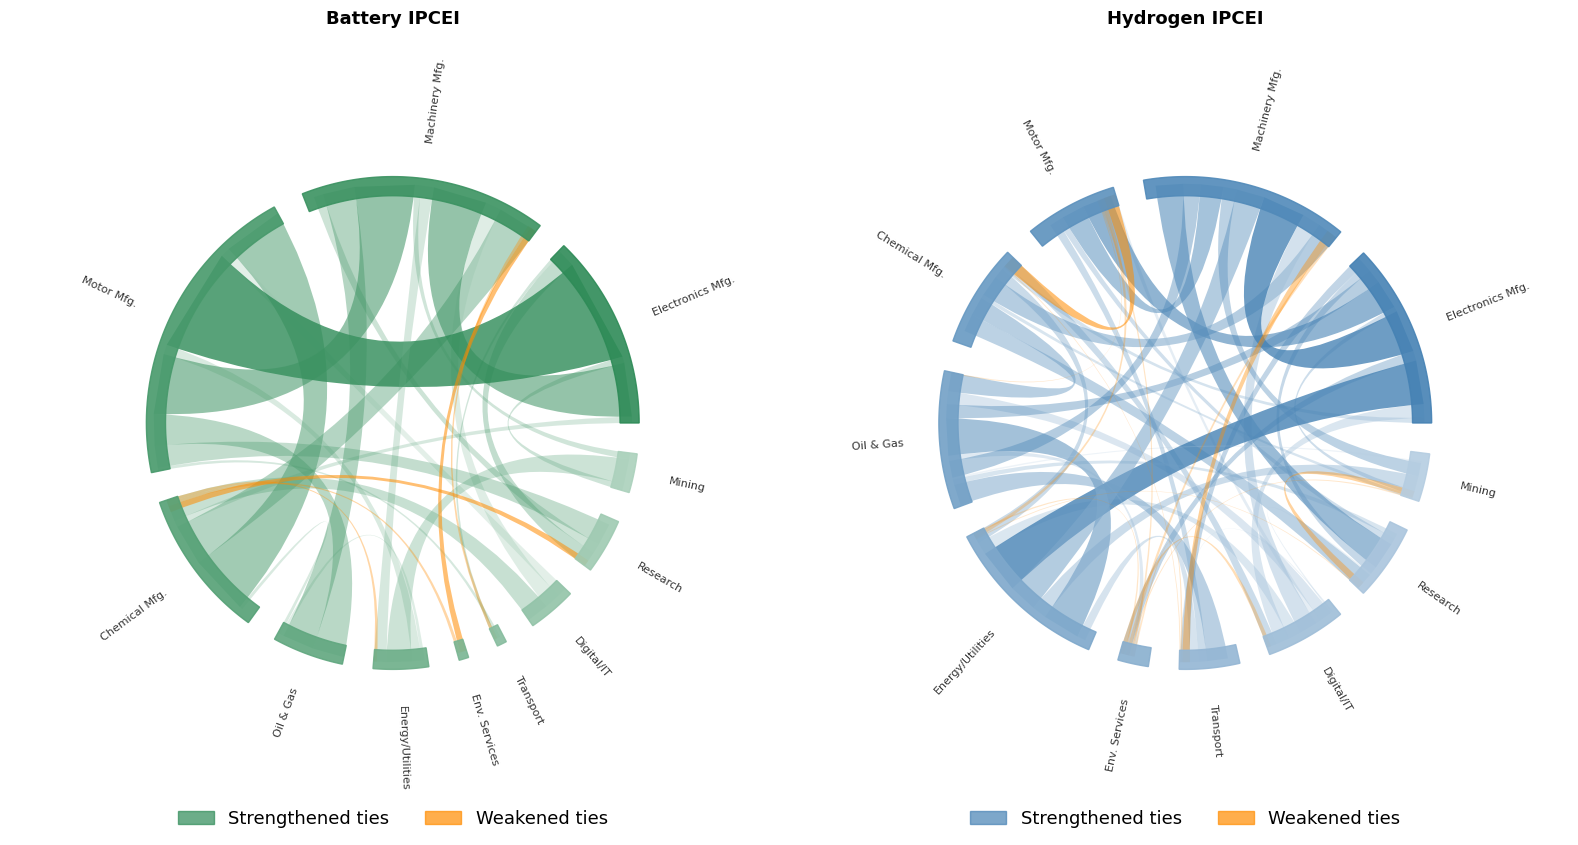

In [25]:
# ============================================================
# *** CURRENTLY NOT USED ***  Change in cross-sector ties — delta chord
# Post (0..+12 months) minus pre (-12..0 months) sector-pair counts around
# the first approval in each technology; strengthened ties in the
# technology colour, weakened ties in orange. Candidate SI figure for the
# within-sector result. Requires the chord helpers cell in section 3.
# ============================================================

def build_sector_flows_delta(partnership_master, firm_master_ipcei, treated_names,
                             tech_col, treatment_date, sector_labels, sector_order,
                             window_months=12, min_flow=3):
    """
    delta = post (t .. t+w) - pre (t-w .. t) per sector pair; keeps pairs with
    |delta| >= min_flow. Returns (pos, neg, sectors_present); pos/neg carry
    sec_a / sec_b / n with n = |delta|.
    """
    t         = pd.Timestamp(treatment_date)
    pre_start = t - pd.DateOffset(months=window_months)
    post_end  = t + pd.DateOffset(months=window_months)

    pre  = _sector_pair_counts(partnership_master, firm_master_ipcei, treated_names,
                               tech_col, sector_labels, pre_start, t)
    post = _sector_pair_counts(partnership_master, firm_master_ipcei, treated_names,
                               tech_col, sector_labels, t, post_end)

    delta = pre.rename(columns={"n": "n_pre"}).merge(
        post.rename(columns={"n": "n_post"}), on=["sec_a", "sec_b"], how="outer").fillna(0)
    delta["n_delta"] = delta["n_post"] - delta["n_pre"]
    delta = delta[delta["n_delta"].abs() >= min_flow]

    present = set(delta["sec_a"]) | set(delta["sec_b"])
    sectors = [s for s in sector_order if s in present]
    pos = delta[delta["n_delta"] > 0].assign(n=lambda d: d["n_delta"])
    neg = delta[delta["n_delta"] < 0].assign(n=lambda d: d["n_delta"].abs())
    print(f"  strengthened: {len(pos)} pairs | weakened: {len(neg)} pairs | sectors: {sectors}")
    return pos, neg, sectors


DELTA_SPECS = [
    # (tech, panel, colour, reference approval date, min_flow)
    ("Battery",  battery_cs,  COLORS["two"][1], "2021-01-01", 1),
    ("Hydrogen", hydrogen_cs, COLORS["two"][0], "2022-07-01", 3),
]

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, (tech, cs, color, ref_date, min_flow) in zip(axes, DELTA_SPECS):
    print(f"{tech}:")
    treated = set(cs.loc[cs["is_treated"] == 1, "Linkedin_name"])
    pos, neg, sectors = build_sector_flows_delta(
        partnership_master, firm_master_ipcei, treated, tech, ref_date,
        sector_labels, sector_order, window_months=12, min_flow=min_flow)
    draw_sector_chord(ax, pos, sectors, color=color, neg_flows=neg,
                      title=f"{tech} IPCEI", label_fontsize=8)
plt.tight_layout()
save_fig(fig, FIG_EXTRA, "collaborations_crosssector_chord_delta")
plt.show()


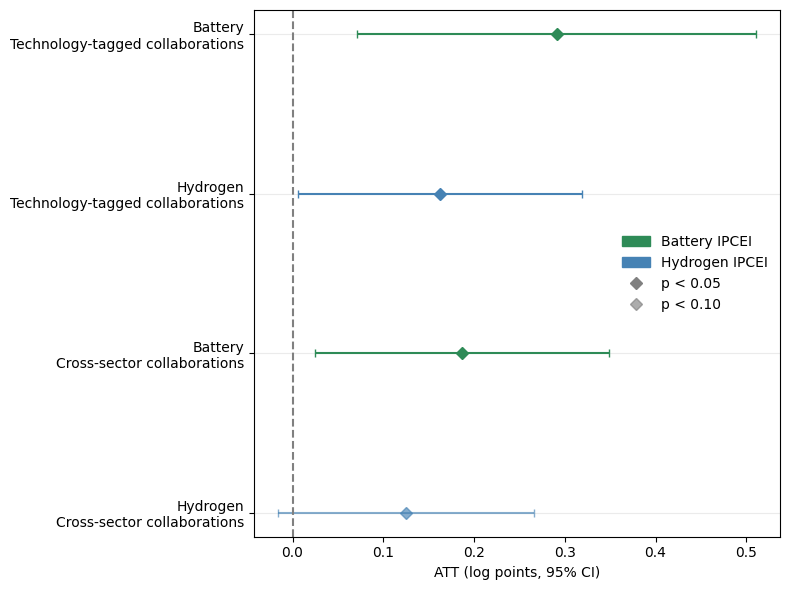

In [26]:
# ============================================================
# *** CURRENTLY NOT USED *** (not in the current draft)
# Kept for reference / possible future use. Not needed for the paper;
# safe to skip when running the notebook.
# ============================================================
# ============================================================
# ATT coefficient plot
# ============================================================

def plot_att_coefficients(att_summary):

    df = att_summary.copy()
    df.columns = [c.strip().title() for c in df.columns]

    # Keep only the outcomes we want
    keep_outcomes = [
        "Technology-tagged collaborations",
        "Cross-border EU collaborations",
        "Cross-sector collaborations",
    ]
    df = df[df["Outcome"].isin(keep_outcomes)]

    # Confidence intervals and significance
    df["Ci_Lo"] = df["Att"] - 1.96 * df["Se"]
    df["Ci_Hi"] = df["Att"] + 1.96 * df["Se"]
    df["Sig_05"] = df["P_Value"] < 0.05
    df["Sig_10"] = (df["P_Value"] >= 0.05) & (df["P_Value"] < 0.10)

    # Order outcomes bottom to top
    outcome_order = [
        "Cross-sector collaborations",
        "Cross-border EU collaborations",
        "Technology-tagged collaborations",
    ]
    df["Outcome"] = pd.Categorical(
        df["Outcome"], categories=outcome_order, ordered=True
    )
    df = df.sort_values(["Outcome", "Technology"], ascending=[True, False])
    df["Y_Label"] = df["Technology"].astype(str) + "\n" + \
                    df["Outcome"].astype(str)

    fig, ax = plt.subplots(figsize=(8, 6))

    for _, row in df.iterrows():
        color  = COLORS["two"][1] if row["Technology"] == "Battery" \
                 else COLORS["two"][0]

        if row["Sig_05"]:
            alpha  = 1.0
            marker = "D"
        elif row["Sig_10"]:
            alpha  = 0.65
            marker = "D"
        else:
            alpha  = 0.25
            marker = "o"

        ax.errorbar(
            row["Att"], row["Y_Label"],
            xerr=[[row["Att"] - row["Ci_Lo"]], [row["Ci_Hi"] - row["Att"]]],
            fmt=marker, color=color, alpha=alpha,
            capsize=3, linewidth=1.5, markersize=6
        )

    ax.axvline(0, linestyle="--", color="grey")
    ax.set_xlabel("ATT (log points, 95% CI)")

    patches = [
        mpatches.Patch(color=COLORS["two"][1], label="Battery IPCEI"),
        mpatches.Patch(color=COLORS["two"][0], label="Hydrogen IPCEI"),
        plt.Line2D([0], [0], marker="D", color="grey", linestyle="None",
                   markersize=6, alpha=1.0,  label="p < 0.05"),
        plt.Line2D([0], [0], marker="D", color="grey", linestyle="None",
                   markersize=6, alpha=0.65, label="p < 0.10"),
        #plt.Line2D([0], [0], marker="o", color="grey", linestyle="None",
        #           markersize=6, alpha=0.40, label="p ≥ 0.10"),
    ]

    ax.legend(handles=patches, frameon=False, loc="center right")
    style_ax(ax)

    plt.tight_layout()
    save_fig(fig, FIG_EXTRA, "collaborations_att_coefficients")
    plt.show()

plot_att_coefficients(att_summary)


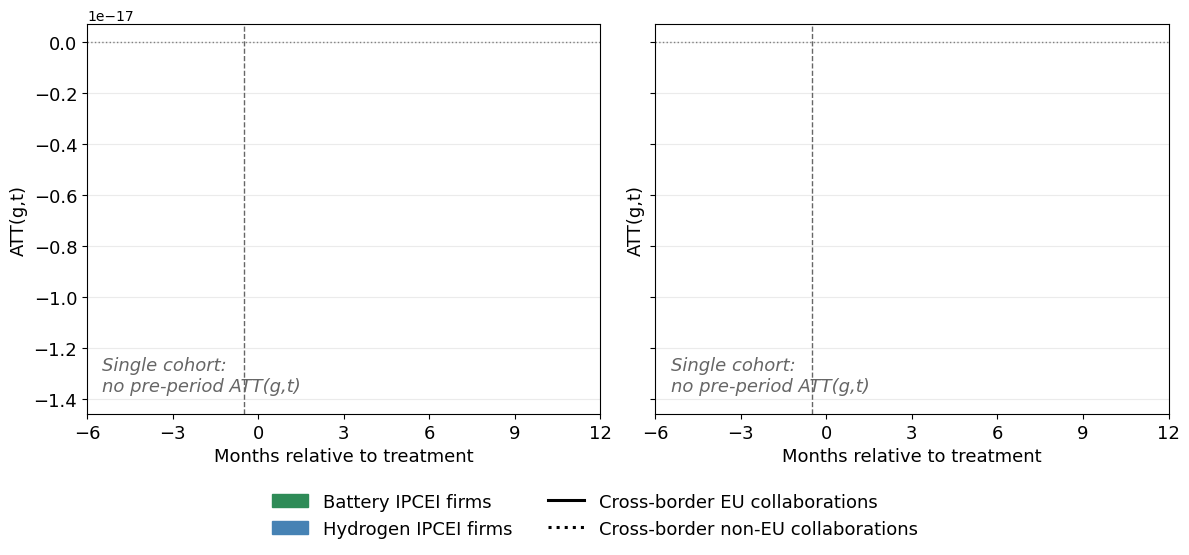

In [27]:
# ============================================================
# *** CURRENTLY NOT USED *** (not in the current draft)
# Kept for reference / possible future use. Not needed for the paper;
# safe to skip when running the notebook.
# ============================================================
# ============================================================
# EU collaboration event studies
# ============================================================

def plot_eu_event_overlay(event_study):

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

    specs = [
        ("Battery",  "Battery -- Cross-border EU collaborations",  "Battery -- Non-EU collaborations"),
        ("Hydrogen", "Hydrogen -- Cross-border EU collaborations", "Hydrogen -- Non-EU collaborations"),
    ]

    for ax, (tech, eu_label, non_label) in zip(axes, specs):

        eu = event_study[event_study["label"] == eu_label].copy()
        non = event_study[event_study["label"] == non_label].copy()

        eu = eu[(eu["e"] >= -6) & (eu["e"] <= 12)]
        non = non[(non["e"] >= -6) & (non["e"] <= 12)]

        base_color = COLORS["two"][1] if tech == "Battery" else COLORS["two"][0]

        # --- EU collaborations ---
        ax.fill_between(eu["e"], eu["ci_lower"], eu["ci_upper"],
                        color=base_color, alpha=0.18)

        pre = eu[eu["e"] < 0]
        post = eu[eu["e"] >= 0]

        if not pre.empty:
            ax.plot(pre["e"], pre["att"],
                    color=base_color,
                    linestyle="--", linewidth=1.6)

        ax.plot(post["e"], post["att"],
                color=base_color,
                linewidth=2.2)

        # --- NON-EU collaborations ---
        ax.fill_between(non["e"], non["ci_lower"], non["ci_upper"],
                        color=base_color, alpha=0.08)

        pre = non[non["e"] < 0]
        post = non[non["e"] >= 0]

        if not pre.empty:
            ax.plot(pre["e"], pre["att"],
                    color=base_color,
                    linestyle="--", linewidth=1.6, alpha=0.7)

        ax.plot(post["e"], post["att"],
                color=base_color,
                linewidth=2.2,
                linestyle=":")

        ax.axhline(0, linestyle=":", color="grey", linewidth=1)
        ax.axvline(-0.5, linestyle="--", color="#666666", linewidth=1)

        ax.set_xlim(-6, 12)
        ax.set_xticks(range(-6, 13, 3))

        ax.set_xlabel("Months relative to treatment", fontsize=13)
        ax.set_ylabel("ATT(g,t)", fontsize=13)
        ax.tick_params(axis="both", labelsize=13)

        has_pre = (
            (not eu[eu["e"] < 0].empty) or
            (not non[non["e"] < 0].empty)
        )

        if not has_pre:
            ax.text(
                0.03, 0.05,
                "Single cohort:\nno pre-period ATT(g,t)",
                transform=ax.transAxes,
                fontsize=13,
                color="#666666",
                va="bottom",
                ha="left",
                style="italic"
            )

        style_ax(ax)

    # Shared legend — technology colors + line meanings
    battery_patch = mpatches.Patch(
        color=COLORS["two"][1],
        label="Battery IPCEI firms"
    )
    hydrogen_patch = mpatches.Patch(
        color=COLORS["two"][0],
        label="Hydrogen IPCEI firms"
    )

    eu_line = Line2D(
        [0], [0],
        color="black",
        linewidth=2.2,
        linestyle="-",
        label="Cross-border EU collaborations"
    )
    non_eu_line = Line2D(
        [0], [0],
        color="black",
        linewidth=2.2,
        linestyle=":",
        label="Cross-border non-EU collaborations"
    )

    fig.legend(
        handles=[battery_patch, hydrogen_patch, eu_line, non_eu_line],
        loc="lower center",
        ncol=2,
        frameon=False,
        fontsize=13,
        bbox_to_anchor=(0.5, -0.12)
    )

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.16)

    save_fig(fig, FIG_EXTRA, "collaborations_cross-border_overlay")
    plt.show()

plot_eu_event_overlay(event_study)


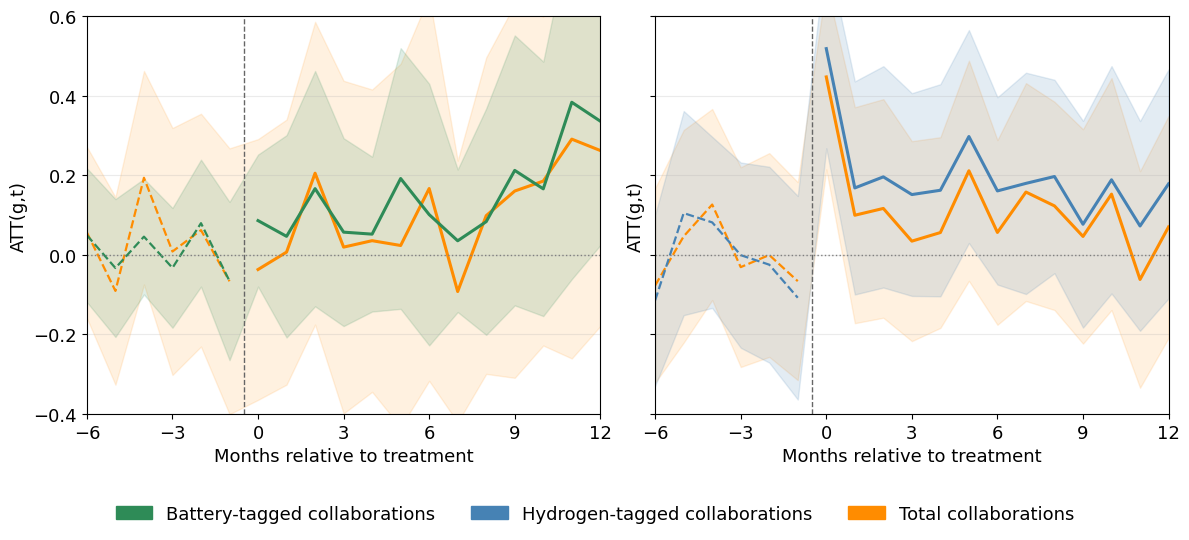

In [28]:
# ============================================================
# *** CURRENTLY NOT USED *** (not in the current draft)
# Kept for reference / possible future use. Not needed for the paper;
# safe to skip when running the notebook.
# ============================================================
# ============================================================
# Technology channel event studies
# ============================================================

def plot_tech_event_overlay(event_study, event_study_total):

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

    specs = [
        ("Battery",  "Battery -- Total collabs",   "Battery -- Technology-tagged collaborations"),
        ("Hydrogen", "Hydrogen -- Total collabs",  "Hydrogen -- Technology-tagged collaborations"),
    ]

    for ax, (tech, total_label, tech_label) in zip(axes, specs):

        total = event_study_total[event_study_total["label"] == total_label].copy()
        techs = event_study[event_study["label"] == tech_label].copy()

        total = total[(total["e"] >= -6) & (total["e"] <= 12)]
        techs = techs[(techs["e"] >= -6) & (techs["e"] <= 12)]

        # --- TOTAL collaborations ---
        ax.fill_between(total["e"], total["ci_lower"], total["ci_upper"],
                        color=COLORS["three"][2], alpha=0.12)

        pre = total[total["e"] < 0]
        post = total[total["e"] >= 0]

        if not pre.empty:
            ax.plot(pre["e"], pre["att"],
                    color=COLORS["three"][2],
                    linestyle="--", linewidth=1.6)

        ax.plot(post["e"], post["att"],
                color=COLORS["three"][2],
                linewidth=2.2)

        # --- TECH collaborations ---
        color = COLORS["two"][1] if tech == "Battery" else COLORS["two"][0]

        ax.fill_between(techs["e"], techs["ci_lower"], techs["ci_upper"],
                        color=color, alpha=0.15)

        pre = techs[techs["e"] < 0]
        post = techs[techs["e"] >= 0]

        if not pre.empty:
            ax.plot(pre["e"], pre["att"],
                    color=color,
                    linestyle="--", linewidth=1.6)

        ax.plot(post["e"], post["att"],
                color=color,
                linewidth=2.2)

        ax.axhline(0, linestyle=":", color="grey", linewidth=1)
        ax.axvline(-0.5, linestyle="--", color="#666666", linewidth=1)

        ax.set_ylim(-0.4, 0.6)
        ax.set_xlim(-6, 12)
        ax.set_xticks(range(-6, 13, 3))

        ax.set_xlabel("Months relative to treatment", fontsize=13)
        ax.set_ylabel("ATT(g,t)", fontsize=13)
        ax.tick_params(axis="both", labelsize=13)

        has_pre = (
            (not total[total["e"] < 0].empty) or
            (not techs[techs["e"] < 0].empty)
        )

        if not has_pre:
            ax.text(
                0.03, 0.05,
                "Single cohort:\nno pre-period ATT(g,t)",
                transform=ax.transAxes,
                fontsize=13,
                color="#666666",
                va="bottom",
                ha="left",
                style="italic"
            )

        style_ax(ax)

    # Shared legend — technology colors + outcome type
    battery_patch = mpatches.Patch(
        color=COLORS["two"][1],
        label="Battery-tagged collaborations"
    )
    hydrogen_patch = mpatches.Patch(
        color=COLORS["two"][0],
        label="Hydrogen-tagged collaborations"
    )
    total_patch = mpatches.Patch(
        color=COLORS["three"][2],
        label="Total collaborations"
    )

    fig.legend(
        handles=[battery_patch, hydrogen_patch, total_patch],
        loc="lower center",
        ncol=3,
        frameon=False,
        fontsize=13,
        bbox_to_anchor=(0.5, -0.09)
    )

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.16)

    save_fig(fig, FIG_EXTRA, "collaborations_tech-total_overlay")
    plt.show()

plot_tech_event_overlay(event_study, event_study_total)


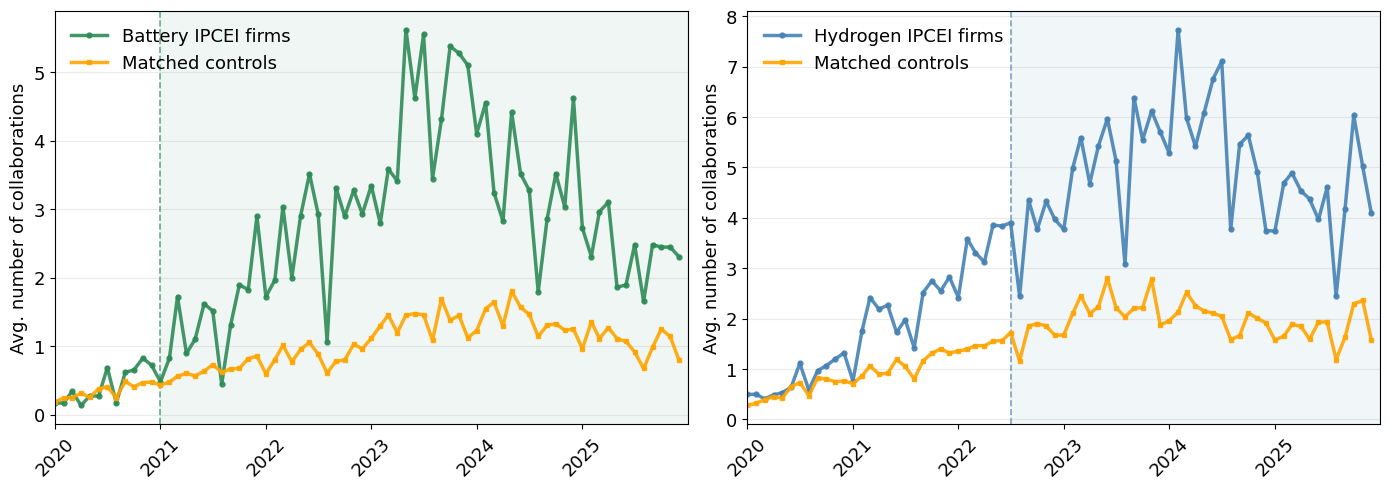

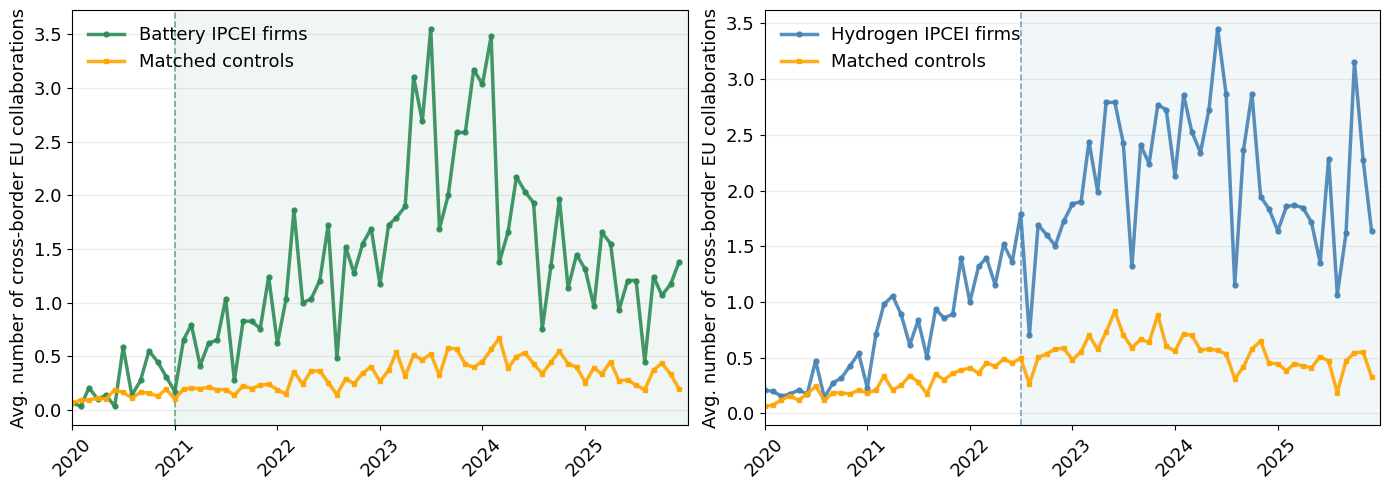

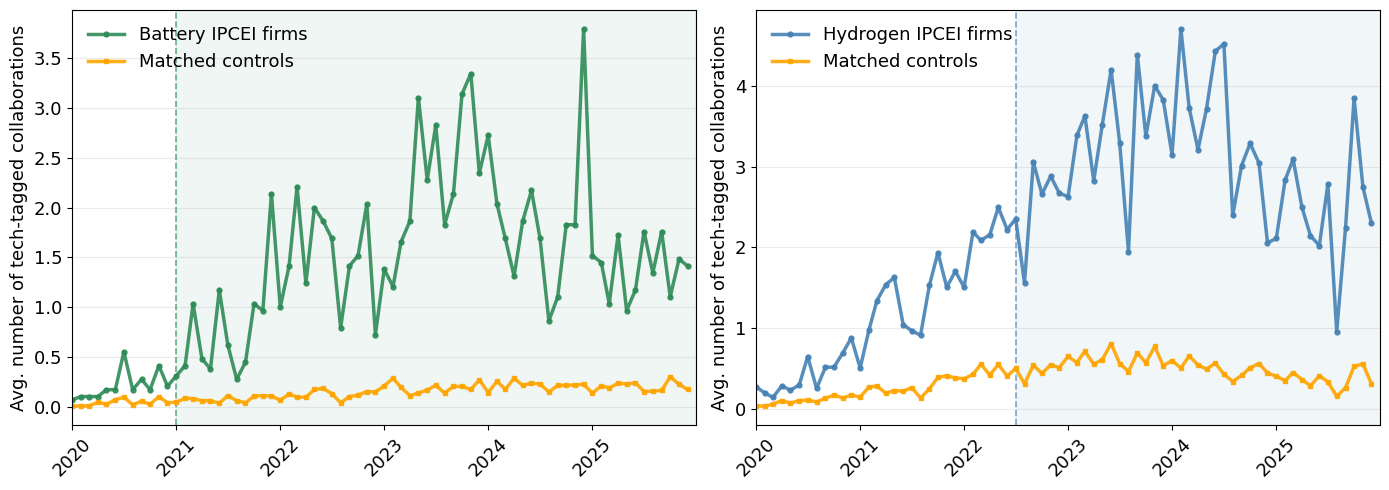

In [29]:
# ============================================================
# *** CURRENTLY NOT USED *** (not in the current draft)
# Kept for reference / possible future use. Not needed for the paper;
# safe to skip when running the notebook.
# ============================================================
# ============================================================
# Annotated outcome trajectories — channels
# ============================================================

def plot_annotated_trajectories(battery_cs, hydrogen_cs,
                                outcome_col="n_collabs",
                                ylabel="Avg. number of collaborations",
                                figname="collaborations_annotated_trajectories"):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    panels = [
        (battery_cs,  "Battery IPCEI",  COLORS["two"][1], "2021-01-01"),
        (hydrogen_cs, "Hydrogen IPCEI", COLORS["two"][0], "2022-07-01"),
    ]

    for ax, (panel, title, color, treat_start) in zip(axes, panels):
        p = panel.copy()
        p["month_dt"] = pd.to_datetime(p["month"])

        if outcome_col not in p.columns:
            print(f"WARNING: column '{outcome_col}' not found. Available: {p.columns.tolist()}")
            continue

        treated_traj = p[p["is_treated"] == 1].groupby("month_dt")[outcome_col].mean()
        control_traj = p[p["is_control"] == 1].groupby("month_dt")[outcome_col].mean()

        ax.axvspan(pd.Timestamp(treat_start), pd.Timestamp("2025-12-31"),
                   alpha=0.07, color=color)
        ax.axvline(pd.Timestamp(treat_start), linestyle="--",
                   color=color, linewidth=1.2, alpha=0.7)

        ax.plot(treated_traj.index, treated_traj.values,
                color=color, linewidth=2.5, marker="o",
                markersize=3.5, label=f"{title} firms", alpha=0.9)
        ax.plot(control_traj.index, control_traj.values,
                color="#FFA500", linewidth=2.5, marker="s",
                markersize=3.5, label="Matched controls", alpha=0.9)

        ax.set_xlim(pd.Timestamp("2020-01-01"), pd.Timestamp("2025-12-31"))
        ax.set_ylabel(ylabel, fontsize=13)
        ax.set_title(title, fontsize=13)
        ax.legend(frameon=False, loc="upper left", fontsize=13)
        ax.tick_params(axis="x", rotation=45, labelsize=13)
        ax.tick_params(axis="y", labelsize=13)

        style_ax(ax)

    plt.tight_layout()
    save_fig(fig, FIG_EXTRA, figname)
    plt.show()

# Total collabs (already working)
plot_annotated_trajectories(battery_cs, hydrogen_cs)

# EU cross-border collabs
plot_annotated_trajectories(
    battery_cs, hydrogen_cs,
    outcome_col="n_collabs_eu_crossborder",
    ylabel="Avg. number of cross-border EU collaborations",
    figname="collaborations_annotated_trajectories_eu"
)

# Tech-specific collabs
# Battery panel uses n_collabs_battery, Hydrogen uses n_collabs_hydrogen
# These differ per technology so we call separately and combine manually
def plot_tech_trajectories(battery_cs, hydrogen_cs):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    configs = [
        (battery_cs,  "n_collabs_battery",  "Battery IPCEI",  COLORS["two"][1], "2021-01-01"),
        (hydrogen_cs, "n_collabs_hydrogen", "Hydrogen IPCEI", COLORS["two"][0], "2022-07-01"),
    ]

    for ax, (panel, col, title, color, treat_start) in zip(axes, configs):
        p = panel.copy()
        p["month_dt"] = pd.to_datetime(p["month"])

        treated_traj = p[p["is_treated"] == 1].groupby("month_dt")[col].mean()
        control_traj = p[p["is_control"] == 1].groupby("month_dt")[col].mean()

        ax.axvspan(pd.Timestamp(treat_start), pd.Timestamp("2025-12-31"),
                   alpha=0.07, color=color)
        ax.axvline(pd.Timestamp(treat_start), linestyle="--",
                   color=color, linewidth=1.2, alpha=0.7)

        ax.plot(treated_traj.index, treated_traj.values,
                color=color, linewidth=2.5, marker="o",
                markersize=3.5, label=f"{title} firms", alpha=0.9)
        ax.plot(control_traj.index, control_traj.values,
                color="#FFA500", linewidth=2.5, marker="s",
                markersize=3.5, label="Matched controls", alpha=0.9)

        ax.set_xlim(pd.Timestamp("2020-01-01"), pd.Timestamp("2025-12-31"))
        ax.set_ylabel("Avg. number of tech-tagged collaborations", fontsize=13)
        ax.set_title(title, fontsize=13)
        ax.legend(frameon=False, loc="upper left", fontsize=13)
        ax.tick_params(axis="x", rotation=45, labelsize=13)
        ax.tick_params(axis="y", labelsize=13)
        style_ax(ax)

    plt.tight_layout()
    save_fig(fig, FIG_EXTRA, "collaborations_annotated_trajectories_tech")
    plt.show()

plot_tech_trajectories(battery_cs, hydrogen_cs)


Battery:  treated 44.8%  control 15.9%
Hydrogen: treated 56.0%  control 21.1%


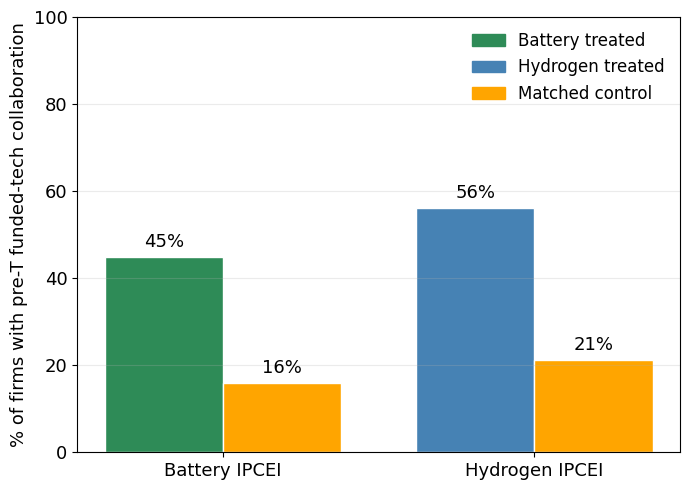

In [30]:
# ============================================================
# *** CURRENTLY NOT USED *** (not in the current draft)
# Kept for reference / possible future use. Not needed for the paper;
# safe to skip when running the notebook.
# ============================================================
# ============================================================
# Baseline funded-tech activity (identification exhibit)
# ============================================================

_pm = partnership_master.copy()
_pm["post_date"] = pd.to_datetime(_pm["post_date"], errors="coerce")
_PRE_CUT = pd.Timestamp("2021-01-01")   # same window for battery AND hydrogen

def _active_firms(tech_flag):
    sub = _pm[(_pm[tech_flag] == 1) & (_pm["post_date"] < _PRE_CUT)]
    return set(sub["source"]).union(set(sub["target"]))

def _share_with_activity(cs, tech_flag):
    active  = _active_firms(tech_flag)
    treated = cs.loc[cs["is_treated"] == 1, "Linkedin_name"].unique()
    control = cs.loc[cs["is_control"] == 1, "Linkedin_name"].unique()
    return (100 * pd.Series(treated).isin(active).mean(),
            100 * pd.Series(control).isin(active).mean())

bat_tr, bat_co = _share_with_activity(battery_cs,  "Battery")
hyd_tr, hyd_co = _share_with_activity(hydrogen_cs, "Hydrogen")
print(f"Battery:  treated {bat_tr:.1f}%  control {bat_co:.1f}%")
print(f"Hydrogen: treated {hyd_tr:.1f}%  control {hyd_co:.1f}%")

# --- grouped bars: 2 technology groups x {treated = tech colour, control = orange} ---
fig, ax = plt.subplots(figsize=(7, 5))
treated_vals = [bat_tr, hyd_tr]
control_vals = [bat_co, hyd_co]
tech_colors  = [COLORS["two"][1], COLORS["two"][0]]   # battery seagreen, hydrogen steelblue
x = np.arange(2)
w = 0.38

for xi, (tv, cv, tcol) in enumerate(zip(treated_vals, control_vals, tech_colors)):
    ax.bar(xi - w / 2, tv, width=w, color=tcol,      edgecolor="white")
    ax.bar(xi + w / 2, cv, width=w, color="#FFA500", edgecolor="white")
    for xpos, v in [(xi - w / 2, tv), (xi + w / 2, cv)]:
        ax.text(xpos, v + 1.5, f"{v:.0f}%", ha="center", va="bottom", fontsize=13)

ax.set_xticks(x)
ax.set_xticklabels(["Battery IPCEI", "Hydrogen IPCEI"], fontsize=13)
ax.set_ylabel("% of firms with pre-T funded-tech collaboration",
              fontsize=13)
ax.set_ylim(0, 100)
ax.tick_params(axis="both", labelsize=13)

handles = [
    mpatches.Patch(color=COLORS["two"][1], label="Battery treated"),
    mpatches.Patch(color=COLORS["two"][0], label="Hydrogen treated"),
    mpatches.Patch(color="#FFA500",        label="Matched control"),
]
ax.legend(handles=handles, frameon=False, fontsize=12, loc="upper right")
style_ax(ax)

plt.tight_layout()
save_fig(fig, FIG_EXTRA, "collaborations_tech_baseline_barchart")
plt.show()


Battery geography prevalence per firm (%) (±12 months):
geo_cat  Domestic  Cross-border EU  Non-EU
period                                    
post        32.01            29.72   28.70
pre         12.13            18.36   17.01

Hydrogen geography prevalence per firm (%) (±12 months):
geo_cat  Domestic  Cross-border EU  Non-EU
period                                    
post        57.19            40.84   36.08
pre         57.92            33.58   36.83


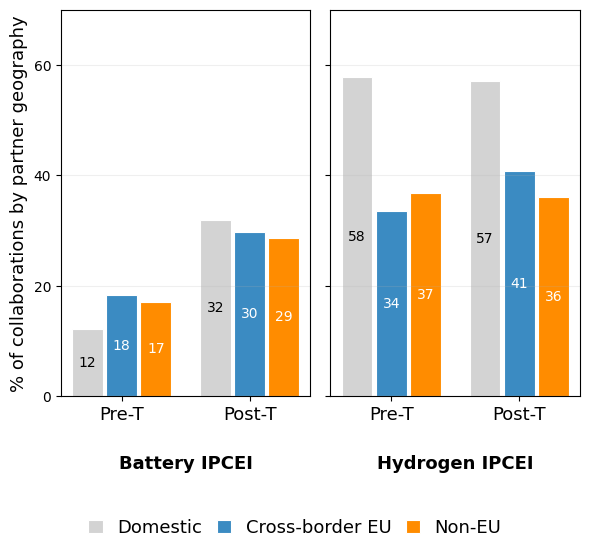

In [31]:
# ============================================================
# *** CURRENTLY NOT USED *** (not in the current draft)
# Kept for reference / possible future use. Not needed for the paper;
# safe to skip when running the notebook.
# ============================================================
# ============================================================
# Geographic composition of collaborations — pre vs post treatment
# ============================================================

fm = firm_master_ipcei.copy()
p  = partnership_master.copy()

# ── Setup ─────────────────────────────────────────────────────────────────────
EU_CODES = {
    "AT","BE","BG","HR","CY","CZ","DK","EE","FI","FR","DE","GR",
    "HU","IE","IT","LV","LT","LU","MT","NL","PL","PT","RO","SK",
    "SI","ES","SE"
}

AXIS_LABEL_FS = 13
TICK_FS       = 13
GROUP_LABEL_FS = 13
LEGEND_FS     = 13
BAR_TEXT_FS   = 13

geo_categories  = ["Domestic", "Cross-border EU", "Non-EU"]
geo_colors = {
    "Domestic":        "lightgrey",
    "Cross-border EU": plt.cm.Blues(0.65),
    "Non-EU":          "darkorange",
}

# ── Primary country lookup ────────────────────────────────────────────────────
primary_map = dict(zip(
    fm["Linkedin_name"],
    fm["primary_country"].str.strip().str.upper()
))

# ── Firm flags and treatment dates ───────────────────────────────────────────
base = fm.drop_duplicates("Linkedin_name").copy()
types_lc = base["ipcei_types"].astype("string").str.lower()
base["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)
base["is_battery"]  = types_lc.str.contains("battery",  na=False)
base["is_ipcei"]    = base["treated_any"].fillna(0).astype(int) == 1

base["first_battery_date"]  = pd.to_datetime(
    base["first_battery_date"],  errors="coerce")
base["first_hydrogen_date"] = pd.to_datetime(
    base["first_hydrogen_date"], errors="coerce")

# Treatment date lookup per firm per technology
battery_treat_map  = dict(zip(
    base.loc[base["is_battery"],  "Linkedin_name"],
    base.loc[base["is_battery"],  "first_battery_date"]
))
hydrogen_treat_map = dict(zip(
    base.loc[base["is_hydrogen"], "Linkedin_name"],
    base.loc[base["is_hydrogen"], "first_hydrogen_date"]
))

# ── Prep partnerships ─────────────────────────────────────────────────────────
p["post_date"] = pd.to_datetime(p["post_date"], errors="coerce")
p = p.loc[p["post_date"].between(
    pd.Timestamp("2020-01-01"), pd.Timestamp("2025-12-31")
)].copy()

p["src_country"] = p["source"].map(primary_map)
p["tgt_country"] = p["target"].map(primary_map)

valid_iso2 = lambda x: isinstance(x, str) and len(x) == 2 and x.isalpha()
p = p[p["src_country"].apply(valid_iso2) & p["tgt_country"].apply(valid_iso2)]

def classify_geo(src, tgt, eu_codes):
    if src == tgt:
        return "Domestic"
    elif src in eu_codes and tgt in eu_codes:
        return "Cross-border EU"
    else:
        return "Non-EU"

p["geo_cat"] = p.apply(
    lambda r: classify_geo(r["src_country"], r["tgt_country"], EU_CODES),
    axis=1
)

# ── Build firm-level pre/post geographic shares ───────────────────────────────
def build_geo_counts_firmwise(p, ipcei_names, treat_map,
                               window_months=12):
    """
    For each IPCEI firm, compute the prevalence (%) of each geographic
    category among that firm's collaborations in ±window_months around the
    treatment date, then average across firms. Geographies co-occur within
    multi-firm collaborations, so the prevalences are independent and need
    NOT sum to 100.
    """
    records = []

    for firm in ipcei_names:
        t_date = treat_map.get(firm)
        if pd.isna(t_date):
            continue

        pre_start = t_date - pd.DateOffset(months=window_months)
        post_end  = t_date + pd.DateOffset(months=window_months)

        firm_p = p.loc[
            (p["source"] == firm) | (p["target"] == firm)
        ].copy()

        pre_p  = firm_p[
            (firm_p["post_date"] >= pre_start) &
            (firm_p["post_date"] <  t_date)
        ]
        post_p = firm_p[
            (firm_p["post_date"] >= t_date) &
            (firm_p["post_date"] <  post_end)
        ]

        for period, sub in [("pre", pre_p), ("post", post_p)]:
            total = sub["collaboration_id"].nunique()
            for cat in geo_categories:
                n = sub.loc[
                    sub["geo_cat"] == cat, "collaboration_id"
                ].nunique()
                # Independent prevalence: share of THIS firm's collaborations
                # in the period that involve geography `cat`. Denominator is
                # ALL of the firm's collaborations, not the sum across the
                # (co-occurring) geographies, so these do NOT sum to 100.
                records.append({
                    "firm":       firm,
                    "period":     period,
                    "geo_cat":    cat,
                    "prevalence": 100 * n / total if total > 0 else 0.0
                })

    df = pd.DataFrame(records)
    if df.empty:
        return pd.DataFrame(columns=["period"] + geo_categories)

    avg = (
        df.groupby(["period", "geo_cat"])["prevalence"]
          .mean()
          .reset_index()
    )
    return avg.pivot(index="period", columns="geo_cat", values="prevalence")\
              .fillna(0)\
              .reindex(columns=geo_categories)

# ── IPCEI firm lists per technology (keys align with the treat maps above) ────
battery_ipcei  = base.loc[base["is_battery"],  "Linkedin_name"].tolist()
hydrogen_ipcei = base.loc[base["is_hydrogen"], "Linkedin_name"].tolist()

# ── Build geo counts ──────────────────────────────────────────────────────────
battery_geo  = build_geo_counts_firmwise(
    p, battery_ipcei,  battery_treat_map,  window_months=12)
hydrogen_geo = build_geo_counts_firmwise(
    p, hydrogen_ipcei, hydrogen_treat_map, window_months=12)

print("Battery geography prevalence per firm (%) (±12 months):")
print(battery_geo.round(2))
print("\nHydrogen geography prevalence per firm (%) (±12 months):")
print(hydrogen_geo.round(2))

# ── Convert to shares + totals ────────────────────────────────────────────────
# geo_df already holds independent prevalences (%) per geography.
# No partition (sum-over-categories) normalisation: bars need not sum to 100.
battery_shares  = battery_geo
hydrogen_shares = hydrogen_geo

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(6, 5.6), sharey=True)

data_map = {
    "Battery IPCEI":  battery_shares,
    "Hydrogen IPCEI": hydrogen_shares,
}

geo_categories = ["Domestic", "Cross-border EU", "Non-EU"]
geo_colors = {
    "Domestic":        "lightgrey",
    "Cross-border EU": plt.cm.Blues(0.65),
    "Non-EU":          "darkorange",
}

period_keys = ["pre", "post"]
n_cats      = len(geo_categories)
col_width   = 0.8

for ax, fg in zip(axes, ["Battery IPCEI", "Hydrogen IPCEI"]):
    shares = data_map[fg]

    period_x = {pk: j for j, pk in enumerate(period_keys)}
    bar_w    = col_width / n_cats

    # Grouped bars: one bar per geography within each period (not stacked).
    # Independent prevalences; bars need not sum to 100.
    for c, cat in enumerate(geo_categories):
        xs, ys = [], []
        for pk in period_keys:
            center = period_x[pk]
            offset = center - col_width / 2 + (c + 0.5) * bar_w
            v = float(shares.loc[pk, cat]) if pk in shares.index else 0.0
            xs.append(offset)
            ys.append(v)

        ax.bar(
            xs, ys,
            width=bar_w * 0.9,
            label=cat,
            color=geo_colors[cat],
            edgecolor="white", linewidth=0.8
        )

        for x, v in zip(xs, ys):
            if v >= 9:
                ax.text(
                    x, v / 2, f"{v:.0f}",
                    ha="center", va="center",
                    fontsize=BAR_TEXT_FS - 3,
                    color="white" if cat != "Domestic" else "black"
                )

    # x-axis labels
    ax.set_xticks([period_x[pk] for pk in period_keys])
    ax.set_xticklabels(["Pre-T", "Post-T"], fontsize=TICK_FS)

    # Group label below — same style as activity plot
    cx = np.mean([period_x[pk] for pk in period_keys])
    ax.annotate(
        fg,
        xy=(cx, 0), xycoords=("data", "axes fraction"),
        xytext=(0, -42), textcoords="offset points",
        ha="center", va="top",
        fontsize=GROUP_LABEL_FS, fontweight="bold",
        annotation_clip=False
    )

    ax.set_ylim(0, 70)
    ax.set_yticks(np.arange(0, 71, 20))
    style_ax(ax)
    ax.grid(axis="y", alpha=0.2)
    ax.grid(axis="x", visible=False)

axes[0].set_ylabel(
    "% of collaborations by partner geography",
    fontsize=AXIS_LABEL_FS)
axes[1].set_ylabel("")
axes[1].tick_params(axis="y", labelleft=False)

# Legend
handles, labels_leg = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels_leg,
    loc="lower center", bbox_to_anchor=(0.5, -0.03),
    ncol=3, frameon=False,
    handlelength=0.8, columnspacing=0.8,
    fontsize=LEGEND_FS
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.25, top=0.94, wspace=0.08)
save_fig(fig, FIG_EXTRA,
         "partnerhsips_ipcei_geography_prepost")
plt.show()


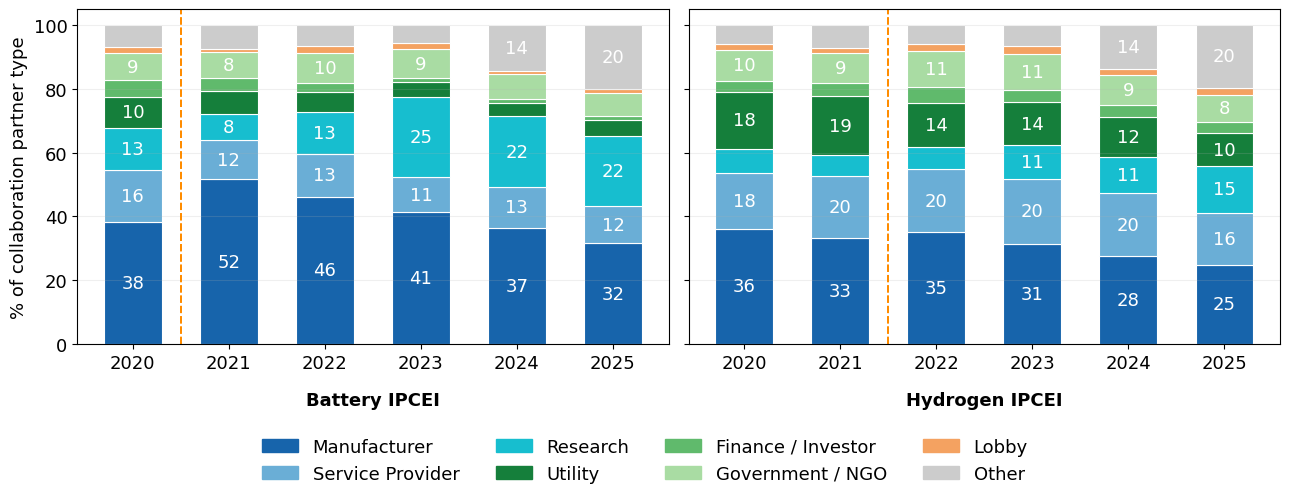

In [32]:
# ============================================================
# *** CURRENTLY NOT USED *** (not in the current draft)
# Kept for reference / possible future use. Not needed for the paper;
# safe to skip when running the notebook.
# ============================================================
# ============================================================
# Partner firm type composition by year
# ============================================================

def plot_partner_firmtype_by_year():

    # --- Identify IPCEI firms and their technology + treatment date ---
    fm = firm_master_ipcei.copy()

    battery_firms  = set(fm.loc[fm["first_battery_date"].notna(),  "Linkedin_name"])
    hydrogen_firms = set(fm.loc[fm["first_hydrogen_date"].notna(), "Linkedin_name"])

    # --- Build partner-level lookup for firm_type ---
    firm_type_lookup = (
        fm[["Linkedin_name", "firm_type"]]
        .dropna(subset=["firm_type"])
        .drop_duplicates("Linkedin_name")
        .set_index("Linkedin_name")["firm_type"]
    )

    # --- Firm type consolidation map ---
    # --- Firm type consolidation map ---
    type_map = {
        "Manufacturer":                    "Manufacturer",
        "Service Provider":                "Service Provider",
        "Consulting":                      "Service Provider",
        "Project Developer":               "Service Provider",
        "Research Institute":              "Research",
        "University":                      "Research",
        "Think Tank":                      "Research",
        "Utility":                         "Utility",
        "Financial Institution":           "Finance / Investor",
        "Investor":                        "Finance / Investor",
        "Venture Capital":                 "Finance / Investor",
        "Bank":                            "Finance / Investor",
        "Other Financing Organization":    "Finance / Investor",
        "Accelerator/Incubator":           "Finance / Investor",
        "Governmental Organization":       "Government / NGO",
        "Governmental organization":       "Government / NGO",
        "Government Organization":         "Government / NGO",
        "Government Administration":       "Government / NGO",
        "International Organization":      "Government / NGO",
        "Intergovernmental Organization":  "Government / NGO",
        "NGO":                             "Government / NGO",
        "Non Governmental Organization":   "Government / NGO",
        "Non-Governmental Organization":   "Government / NGO",
        "Non Govermental Organization":    "Government / NGO",
        "Government":                      "Government / NGO",
        "Lobby Group":                     "Lobby",
        "Industry Association":            "Lobby",
        "Trade Association":               "Lobby",
        "Professional Association":        "Lobby",
        "Professional Organization":       "Lobby",
        "Chamber of Commerce":             "Lobby",
        "Other":                           "Other",
        "Media Firm":                      "Other",
        "Event Organizer":                 "Other",
        "Mining":                          "Other",
        "0":                               "Other",
    }

    type_order = [
        "Manufacturer", "Service Provider", "Research",
        "Utility", "Finance / Investor", "Government / NGO", "Lobby", "Other"
    ]

    type_colors = {
        "Manufacturer":        plt.cm.Blues(0.80),
        "Service Provider":    plt.cm.Blues(0.50),
        "Research":            "#17becf",
        "Utility":             plt.cm.Greens(0.80),
        "Finance / Investor":  plt.cm.Greens(0.55),
        "Government / NGO":    plt.cm.Greens(0.35),
        "Lobby":               "#f4a261",   # warm orange
        "Other":               "#cccccc",
    }

    results = {}

    for tech, focal_firms, date_col in [
        ("Battery",  battery_firms,  "first_battery_date"),
        ("Hydrogen", hydrogen_firms, "first_hydrogen_date"),
    ]:
        # Partnerships where source is a focal IPCEI firm
        pm = partnership_master.copy()
        pm["post_date"] = pd.to_datetime(pm["post_date"], errors="coerce")
        pm = pm[pm["source"].isin(focal_firms)].copy()

        # Merge partner firm_type
        pm["partner_type_raw"] = pm["target"].map(firm_type_lookup)
        pm["partner_type"] = (
            pm["partner_type_raw"]
            .astype("string")
            .str.split(",").str[0]   # take first role if multiple
            .str.strip()
            .map(type_map)
            .fillna("Other")
        )

        pm["year"] = pm["post_date"].dt.year
        pm = pm[pm["year"].between(2020, 2025)]

        # Share per year
        yearly = (
            pm.groupby(["year", "partner_type"])
            .size()
            .reset_index(name="n")
        )
        yearly["share"] = yearly.groupby("year")["n"].transform(
            lambda x: x / x.sum() * 100
        )

        pivot = (
            yearly.pivot(index="year", columns="partner_type", values="share")
            .reindex(columns=type_order)
            .fillna(0)
        )
        results[tech] = pivot

    # --- Plot ---
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

    for ax, (tech, pivot) in zip(axes, results.items()):
        bottom = np.zeros(len(pivot))
        x = np.arange(len(pivot))

        for ptype in type_order:
            if ptype not in pivot.columns:
                continue
            vals = pivot[ptype].values
            ax.bar(x, vals, bottom=bottom,
                   color=type_colors[ptype],
                   label=ptype, width=0.6,
                   edgecolor="white", linewidth=0.8)
            for xi, (v, b) in enumerate(zip(vals, bottom)):
                if v >= 8:
                    ax.text(xi, b + v / 2, f"{v:.0f}",
                            ha="center", va="center",
                            fontsize=13, color="white")
            bottom += vals

        ax.set_xticks(x)
        ax.set_xticklabels(pivot.index.astype(int), rotation=0)
        #ax.set_xlabel("Year")
        ax.set_ylabel("% of collaboration partner type" if ax is axes[0] else "", fontsize=13)
        ax.axvline(
            x=(2021 if tech == "Battery" else 2022) - 2020 - 0.5,
            linestyle="--", color="darkorange", linewidth=1.4,
            label="First approval"
        )
        style_ax(ax)
        ax.grid(axis="y", alpha=0.2)
        ax.grid(axis="x", visible=False)
        ax.tick_params(axis="both", labelsize=13)

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.3)

    # Technology titles below each axis, above legend
    for ax, title in zip(axes, ["Battery IPCEI", "Hydrogen IPCEI"]):
        x_center = ax.get_position().x0 + ax.get_position().width / 2
        fig.text(x_center, 0.17, title,
                 ha="center", va="bottom",
                 fontsize=13, fontweight="bold")

    # Patch handles for firm types only (no "First approval")
    handles = [
        mpatches.Patch(color=type_colors[t], label=t) for t in type_order
    ]

    fig.legend(handles=handles, loc="lower center", ncol=4,
               frameon=False, fontsize=13,
               bbox_to_anchor=(0.5, -0.01))

    # Draw "First approval" line on each axis without adding to legend
    for ax, tech in zip(axes, ["Battery", "Hydrogen"]):
        ax.axvline(
            x=(2021 if tech == "Battery" else 2022) - 2020 - 0.5,
            linestyle="--", color="darkorange", linewidth=1.4,
        )

    save_fig(fig, FIG_EXTRA, "partnerships_firmtype_yearly_barchart")
    plt.show()

plot_partner_firmtype_by_year()


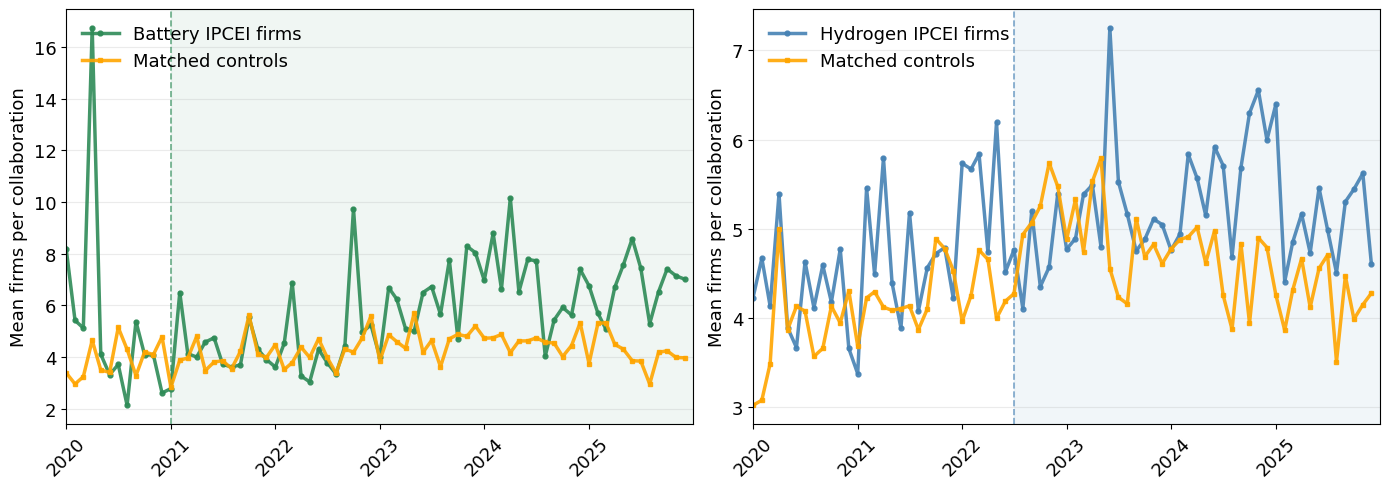

In [33]:
# ============================================================
# *** CURRENTLY NOT USED *** (not in the current draft)
# Kept for reference / possible future use. Not needed for the paper;
# safe to skip when running the notebook.
# ============================================================
# ============================================================
# Appendix: Mean consortium size trajectories (treated vs control)
# ============================================================

if "mean_collab_size" not in globals():
    _pm = partnership_master.copy()
    _pm["post_date"] = pd.to_datetime(_pm["post_date"], errors="coerce")
    _pm["month_dt"]  = _pm["post_date"].dt.to_period("M").dt.to_timestamp()

    _endp = pd.concat([
        _pm[["collaboration_id", "month_dt", "source"]].rename(columns={"source": "Linkedin_name"}),
        _pm[["collaboration_id", "month_dt", "target"]].rename(columns={"target": "Linkedin_name"}),
    ], ignore_index=True).dropna(subset=["collaboration_id", "Linkedin_name"])

    _n_firms = (
        _endp.groupby("collaboration_id")["Linkedin_name"]
             .nunique().rename("n_firms_in_collab")
    )
    _endp = (
        _endp.merge(_n_firms, on="collaboration_id", how="left")
             .dropna(subset=["month_dt"])
             .drop_duplicates(subset=["Linkedin_name", "month_dt", "collaboration_id"])
    )
    mean_collab_size = (
        _endp.groupby(["Linkedin_name", "month_dt"])["n_firms_in_collab"]
             .mean().reset_index(name="mean_collab_size")
    )


def plot_consortium_size_trajectories(battery_cs, hydrogen_cs):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    panels = [
        (battery_cs,  "Battery IPCEI",  COLORS["two"][1], "2021-01-01"),
        (hydrogen_cs, "Hydrogen IPCEI", COLORS["two"][0], "2022-07-01"),
    ]

    for ax, (panel, title, color, treat_start) in zip(axes, panels):
        p = panel.copy()
        p["month_dt"] = pd.to_datetime(p["month"])
        # cs_ready panels carry their own 'mean_collab_size' column (the DiD
        # outcome); drop it so the merge brings in the NaN-on-no-collab lookup
        # below (otherwise the merge suffixes both to _x/_y and the column is lost).
        p = p.drop(columns=["mean_collab_size"], errors="ignore")
        p = p.merge(mean_collab_size, on=["Linkedin_name", "month_dt"], how="left")

        # mean over firms per month; firm-months with no collaboration are NaN
        # and skipped by mean() (consortium size is undefined with no collabs)
        treated_traj = p[p["is_treated"] == 1].groupby("month_dt")["mean_collab_size"].mean()
        control_traj = p[p["is_control"] == 1].groupby("month_dt")["mean_collab_size"].mean()

        ax.axvspan(pd.Timestamp(treat_start), pd.Timestamp("2025-12-31"),
                   alpha=0.07, color=color)
        ax.axvline(pd.Timestamp(treat_start), linestyle="--",
                   color=color, linewidth=1.2, alpha=0.7)

        ax.plot(treated_traj.index, treated_traj.values,
                color=color, linewidth=2.5, marker="o",
                markersize=3.5, label=f"{title} firms", alpha=0.9)
        ax.plot(control_traj.index, control_traj.values,
                color="#FFA500", linewidth=2.5, marker="s",
                markersize=3.5, label="Matched controls", alpha=0.9)

        ax.set_xlim(pd.Timestamp("2020-01-01"), pd.Timestamp("2025-12-31"))
        ax.set_ylabel("Mean firms per collaboration", fontsize=13)
        ax.set_title(title, fontsize=13)
        ax.legend(frameon=False, loc="upper left", fontsize=13)
        ax.tick_params(axis="x", rotation=45, labelsize=13)
        ax.tick_params(axis="y", labelsize=13)
        style_ax(ax)

    plt.tight_layout()
    save_fig(fig, FIG_EXTRA, "collaborations_consortium_size_trajectories")
    plt.show()


plot_consortium_size_trajectories(battery_cs, hydrogen_cs)


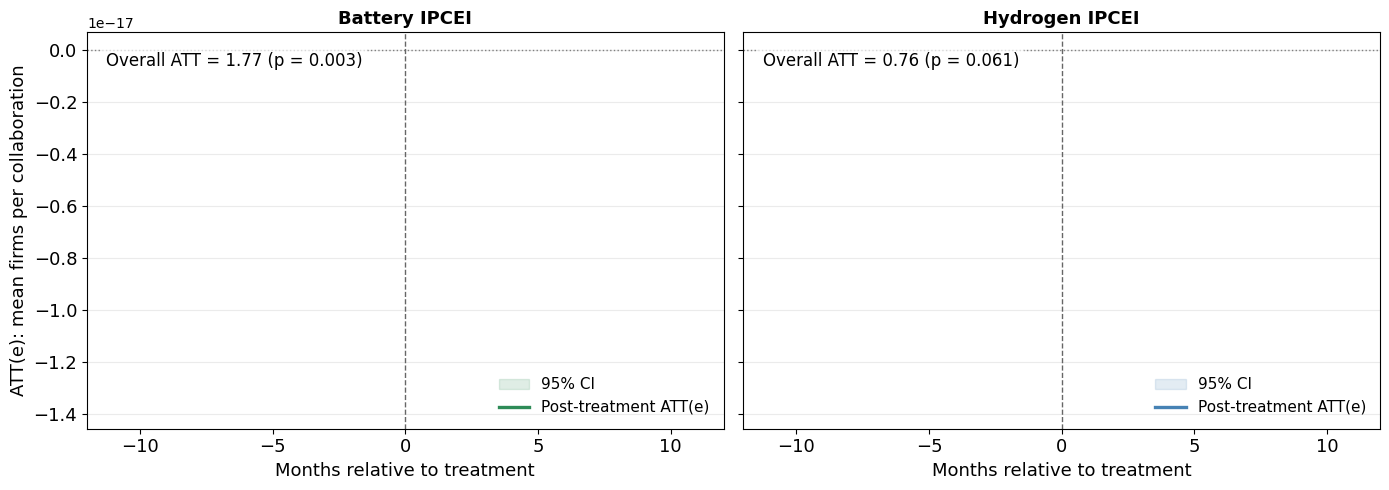

In [34]:
# ============================================================
# *** CURRENTLY NOT USED *** (not in the current draft)
# Kept for reference / possible future use. Not needed for the paper;
# safe to skip when running the notebook.
# ============================================================
# ============================================================
# Consortium-size mechanism (event-time ATT)
# ============================================================

_csize_att = pd.read_csv(TT_DIR / "consortium_size_att.csv")

def plot_consortium_size_event_study(event_study, att_tbl):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    techs = [
        ("Battery",  "Battery IPCEI",  COLORS["two"][1]),
        ("Hydrogen", "Hydrogen IPCEI", COLORS["two"][0]),
    ]

    for ax, (tech, title, color) in zip(axes, techs):
        label = f"{tech} -- Consortium size (mean firms/collab)"
        df = event_study[event_study["label"] == label].copy()
        df = df[(df["e"] >= -12) & (df["e"] <= 12)]
        pre, post = df[df["e"] < 0], df[df["e"] >= 0]

        ax.fill_between(df["e"], df["ci_lower"], df["ci_upper"],
                        color=color, alpha=0.15, label="95% CI")
        if not pre.empty:
            ax.plot(pre["e"], pre["att"], color=color, linewidth=1.8,
                    linestyle="--", alpha=0.7, label="Pre-treatment ATT(e)")
        ax.plot(post["e"], post["att"], color=color, linewidth=2.4,
                label="Post-treatment ATT(e)")

        ax.axhline(0, linestyle=":",  color="grey",    linewidth=1)
        ax.axvline(0, linestyle="--", color="#666666", linewidth=1)
        ax.set_xlim(-12, 12)
        ax.set_xlabel("Months relative to treatment", fontsize=13)
        ax.tick_params(axis="both", labelsize=13)

        row = att_tbl[att_tbl["Technology"] == tech].iloc[0]
        ax.text(0.03, 0.95,
                f"Overall ATT = {row['ATT']:.2f} (p = {row['p_value']:.3f})",
                transform=ax.transAxes, fontsize=12, va="top", ha="left",
                bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.7, ec="none"))

        style_ax(ax)
        ax.set_title(title, fontsize=13, fontweight="bold")
        ax.legend(loc="lower right", frameon=False, fontsize=11)

    axes[0].set_ylabel("ATT(e): mean firms per collaboration", fontsize=13)
    plt.tight_layout()
    save_fig(fig, FIG_EXTRA, "collaborations_consortium_size_event")
    plt.show()

plot_consortium_size_event_study(event_study, _csize_att)


In [35]:
# ============================================================
# *** CURRENTLY NOT USED *** (not in the current draft)
# Sector heatmap; the cross-sector chord (Fig 5) is used instead.
# Kept for reference / possible future use.
# ============================================================
# ============================================================
# NACE sector pair heatmaps — change in cross-sector collaboration
# Post minus pre-treatment, Battery and Hydrogen separately
# ============================================================

import seaborn as sns
import matplotlib.colors as mcolors

# Self-contained: sector label map, ordering, and matrix builder
# (formerly defined in the removed sector-heatmap cell).
# ── Sector label mapping ──────────────────────────────────────────────────────
sector_labels = {
    "M72 — Research Services":           "R&D",
    "B07 — Mining":                      "Mining",
    "E38 — Environmental Services":      "Env. Services",
    "H49 — Land Transport":              "Transport",
    "J62 — IT Services":                 "Digital/IT",
    "C20 — Chemical Manufacturing":      "Chemical Mfg.",
    "D06 — Oil and Gas":                 "Oil & Gas",
    "C29 — Motor Vehicle Manufacturing": "Motor Mfg.",
    "C26 — Electronics Manufacturing":   "Electronics Mfg.",
    "C28 — Machinery Manufacturing":     "Machinery Mfg.",
    "D35 — Utilities":                   "Energy/Utilities",
}

# Sector order for consistent axis ordering
sector_order = [
    # Core manufacturing value chain
    "Electronics Mfg.", "Machinery Mfg.", "Motor Mfg.", "Chemical Mfg.",
    # Energy system
    "Oil & Gas", "Energy/Utilities", "Env. Services",
    # Enabling / upstream
    "Transport", "Digital/IT", "R&D", "Mining"
]

def build_sector_matrix(partnership_master, firm_master_ipcei,
                         treated_names, tech_col,
                         start_date, end_date,
                         sector_labels, sector_order):
    """
    Build normalised sector-pair collaboration matrix.
    Rows and columns = NACE sectors of source and target firms.
    Values = share of total cross-sector collaborations.
    """
    # Sector lookup
    sector_map = dict(zip(
        firm_master_ipcei["Linkedin_name"],
        firm_master_ipcei["nace2_proxy"].map(sector_labels)
    ))

    p = partnership_master.copy()
    p["post_date"] = pd.to_datetime(p["post_date"], errors="coerce")
    p = p[(p["post_date"] >= pd.Timestamp(start_date)) &
          (p["post_date"] <  pd.Timestamp(end_date))]
    p = p[p[tech_col] == 1]
    p = p[p["source"].isin(treated_names) | p["target"].isin(treated_names)]

    p["src_sector"] = p["source"].map(sector_map)
    p["tgt_sector"] = p["target"].map(sector_map)

    # Keep only pairs where both sectors are known and different
    p = p.dropna(subset=["src_sector", "tgt_sector"])
    p = p[p["src_sector"] != p["tgt_sector"]]

    # Normalise pair order
    p["sec_a"] = p.apply(
        lambda r: min(r["src_sector"], r["tgt_sector"]), axis=1)
    p["sec_b"] = p.apply(
        lambda r: max(r["src_sector"], r["tgt_sector"]), axis=1)

    flows = (
        p.groupby(["sec_a", "sec_b"])["collaboration_id"]
         .nunique()
         .reset_index(name="n")
    )

    # Normalise to shares
    total = flows["n"].sum()
    flows["share"] = flows["n"] / total if total > 0 else 0

    # Build symmetric matrix
    sectors = [s for s in sector_order
               if s in flows["sec_a"].values or s in flows["sec_b"].values]

    matrix = pd.DataFrame(0.0, index=sectors, columns=sectors)
    for _, row in flows.iterrows():
        if row["sec_a"] in matrix.index and row["sec_b"] in matrix.columns:
            matrix.loc[row["sec_a"], row["sec_b"]] = row["share"]
            matrix.loc[row["sec_b"], row["sec_a"]] = row["share"]

    return matrix


def plot_sector_heatmaps_diff(
    battery_cs, hydrogen_cs,
    partnership_master, firm_master_ipcei,
    sector_labels, sector_order
):

    configs = [
        (
            battery_cs, "Battery",
            "2020-01-01", "2021-01-01", "2022-01-01",
            "collaborations_battery_sector_heatmap_diff"
        ),
        (
            hydrogen_cs, "Hydrogen",
            "2021-07-01", "2022-07-01", "2023-07-01",
            "collaborations_hydrogen_sector_heatmap_diff"
        ),
    ]

    for cs, tech_col, pre_s, pre_e, post_e, figname in configs:

        treated_names = set(cs.loc[cs["is_treated"] == 1, "Linkedin_name"])

        mat_pre = build_sector_matrix(
            partnership_master, firm_master_ipcei,
            treated_names, tech_col,
            start_date=pre_s,
            end_date=pre_e,
            sector_labels=sector_labels,
            sector_order=sector_order
        )

        mat_post = build_sector_matrix(
            partnership_master, firm_master_ipcei,
            treated_names, tech_col,
            start_date=pre_e,
            end_date=post_e,
            sector_labels=sector_labels,
            sector_order=sector_order
        )

        # Align matrices
        all_sectors = sorted(
            set(mat_pre.index.tolist() + mat_post.index.tolist()),
            key=lambda x: sector_order.index(x) if x in sector_order else 99
        )

        mat_pre = mat_pre.reindex(index=all_sectors, columns=all_sectors, fill_value=0)
        mat_post = mat_post.reindex(index=all_sectors, columns=all_sectors, fill_value=0)

        # Difference: post - pre
        mat_diff = mat_post - mat_pre

        # Shared symmetric scale around zero
        vmax = 0.10

        # Technology-specific diverging colormap:
        # negative = darkorange, zero = white, positive = tech color
        pos_color = COLORS["two"][1] if tech_col == "Battery" else COLORS["two"][0]
        cmap = mcolors.LinearSegmentedColormap.from_list(
            f"{tech_col.lower()}_diff",
            ["darkorange", "white", pos_color],
            N=256
        )

        fig, ax = plt.subplots(figsize=(7.2, 6.6))

        # mask diagonal since same-sector cells are zero / not used
        mat_plot = mat_diff.copy()
        mat_plot.values[np.triu_indices_from(mat_plot, k=0)] = np.nan

        sns.heatmap(
            mat_plot,
            ax=ax,
            cmap=cmap,
            center=0,
            vmin=-vmax,
            vmax=vmax,
            linewidths=0.5,
            cbar=True,
            cbar_kws={
                "shrink": 0.7,
                "label": "Change in cross-sector collaboration"
            },
            annot=False,
            square=True,
        )

        cbar = ax.collections[0].colorbar
        cbar.ax.tick_params(labelsize=13)
        cbar.set_label("Change in cross-sector collaboration", fontsize=13)

        ax.set_facecolor("white")

        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.tick_params(axis="x", rotation=70, labelsize=12)
        ax.tick_params(axis="y", rotation=0, labelsize=13)

        plt.tight_layout()
        plt.subplots_adjust(bottom=0.24)
        save_fig(fig, FIG_EXTRA, figname)
        plt.show()
